In [1]:
import os
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import scipy.stats as stats
from scipy.stats import binomtest
from scipy.stats import theilslopes, kendalltau
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from shapely.errors import GEOSException

In [2]:
# The time coordinate is standardized to the first day of each month.
def first_day_each_month(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month. 
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
#loading era5 data
era5_path = os.path.join("/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed", "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
era5_data = first_day_each_month(era5_data)
era5_data

<xarray.Dataset> Size: 15GB
Dimensions:  (time: 900, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    swe      (time, lat, lon) float32 4GB ...
    t2m      (time, lat, lon) float32 4GB ...
    ppt      (time, lat, lon) float32 4GB ...
    eto      (time, lat, lon) float32 4GB ...

In [4]:
# Compute resolution (in degrees)
dlat = np.abs(era5_data.lat[1] - era5_data.lat[0]).item()
dlon = np.abs(era5_data.lon[1] - era5_data.lon[0]).item()
print(f"ERA5 grid spacing: {dlat:.3f}° lat × {dlon:.3f}° lon")

ERA5 grid spacing: 0.250° lat × 0.250° lon


In [5]:
# load hydrobasins level 4
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")
hb.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

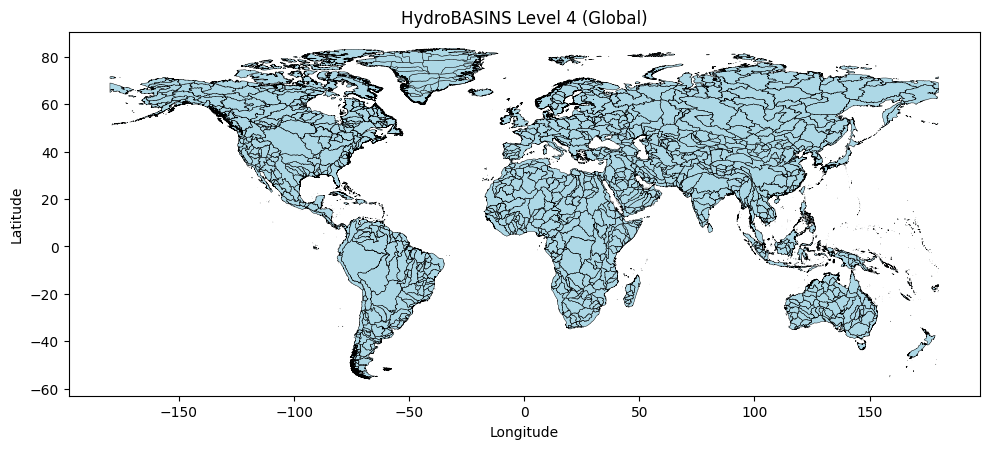

In [6]:
# Plot hydrobasins
fig, ax = plt.subplots(figsize=(10, 6))
hb.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 (Global)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [7]:
# Simplify basin geometries
# Reduces polygon complexity for faster processing
# preserve_topology=True avoids breaking shapes

hb_simple = hb.copy()
hb_simple["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
# buffer(0) is a common geometry fix
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get all unique major basin IDs (sorted)
# (MAIN_BAS groups multiple polygons belonging to one larger basin)
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

Plotting MAIN_BAS = 1040000010


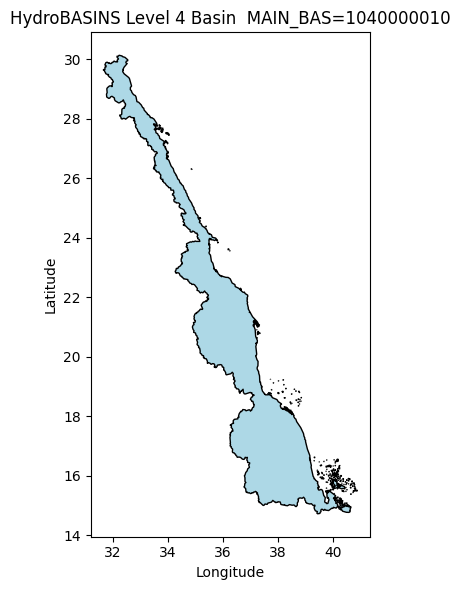

Plotting MAIN_BAS = 9040018060


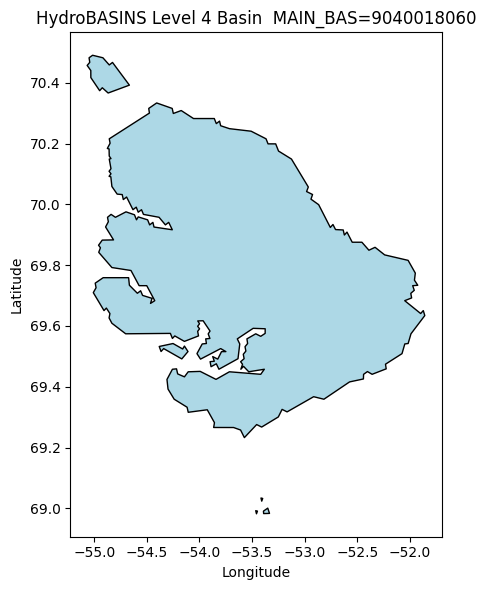

In [8]:
# Identify first and last basins
first_id = main_ids[0]
last_id  = main_ids[-1]

# Plot only first and last basins to verify geometry structure
for main_id in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == main_id]

    # Only plot first and last basins
    if main_id in [first_id, last_id]:
        print(f"Plotting MAIN_BAS = {main_id}")

        fig, ax = plt.subplots(figsize=(8, 6))
        basin.plot(ax=ax, color="lightblue", edgecolor="black")

        ax.set_title(f"HydroBASINS Level 4 Basin  MAIN_BAS={main_id}", fontsize=12)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

        plt.tight_layout()
        plt.show()

In [9]:
print(hb_simple["MAIN_BAS"].values)

[1040000010 1040003990 1040006850 ... 3040024180 3040024310 3040001840]


EPSG:4326
Original basins: 1342
Basins intersecting 0–60°N: 846


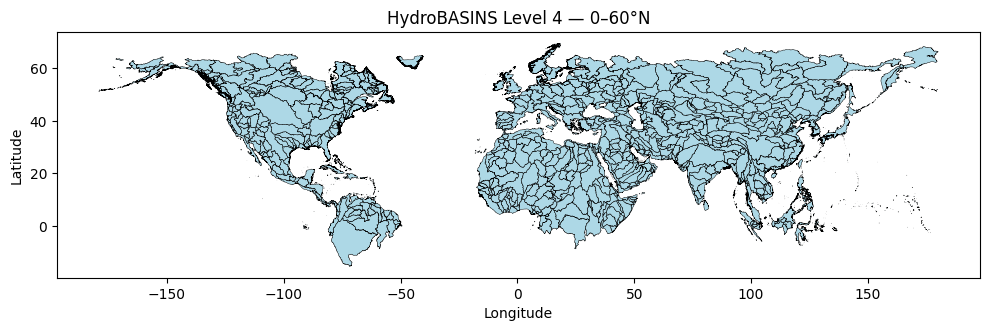

In [10]:
# Create latitude bounding box
# Keep only 0–60°N region

from shapely.geometry import box

# Read HydroBASINS level 3
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")
print(hb.crs)

# Define bounding box for 0–60°N (all longitudes)
bbox_geom = box(-180, 0, 180, 60)  # (minx, miny, maxx, maxy)

# Keep polygons that intersect this band (including edge-touching basins)
# Keep basins intersecting the latitude band -- keeps partial basins crossing boundaries
hb_0_60N = hb[hb.geometry.intersects(bbox_geom)].copy()

# # Keep only basins fully inside the band 
# Alternative: within() would keep only fully enclosed basins
# hb_0_60N = hb[hb.geometry.within(bbox_geom)].copy()

print("Original basins:", len(hb))
print("Basins intersecting 0–60°N:", len(hb_0_60N))

# Quick plot
fig, ax = plt.subplots(figsize=(10, 6))
hb_0_60N.plot(ax=ax, color="lightblue", edgecolor="black", linewidth=0.3)

ax.set_title("HydroBASINS Level 4 — 0–60°N")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

In [11]:
# Simplify geometries again after subsetting
hb_simple = hb_0_60N.copy()

hb_simple["geometry"] = hb_0_60N.geometry.simplify(0.01, preserve_topology=True)

# Fix invalid geometries introduced by simplify
hb_simple["geometry"] = hb_simple.geometry.buffer(0)

# Get all unique MAIN_BAS IDs (sorted) 
main_ids = np.sort(hb_simple["MAIN_BAS"].unique())

In [12]:
# These will define regionmask regions
main_ids = main_ids.copy()  # keep original order used to build `regions`
basin_to_region_index = {bid: i for i, bid in enumerate(main_ids)} # Dictionary: MAIN_BAS → region index - Useful later for mapping outputs

In [13]:
# Build regionmask inputs
geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

# Create one merged geometry per MAIN_BAS
for mid in main_ids:
    basin = hb_simple[hb_simple["MAIN_BAS"] == mid]

    try:
        # dissolve polygons for this MAIN_BAS
        geom = basin.geometry.union_all()
        # clean again just in case
        geom = geom.buffer(0)
        if geom.is_empty:
            print(f"Skipping MAIN_BAS={mid} (empty after buffer)")
            continue
    except GEOSException as e:
        print(f"Skipping MAIN_BAS={mid} due to topology error: {e}")
        continue
    
    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid) 

In [14]:
# Create regionmask object
# This enables assigning ERA5 / GRACE grid cells to basin IDs
regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)
regions

<regionmask.Regions 'unnamed'>
overlap:  None

Regions:
  0 1040000010 basin_1040000010
  1 1040003990 basin_1040003990
  2 1040006850 basin_1040006850
  3 1040006860 basin_1040006860
  4 1040007000 basin_1040007000
 ..        ...              ...
597 8040018120 basin_8040018120
598 8040018970 basin_8040018970
599 8040018980 basin_8040018980
600 8040019790 basin_8040019790
601 9040005890 basin_9040005890

[602 regions]

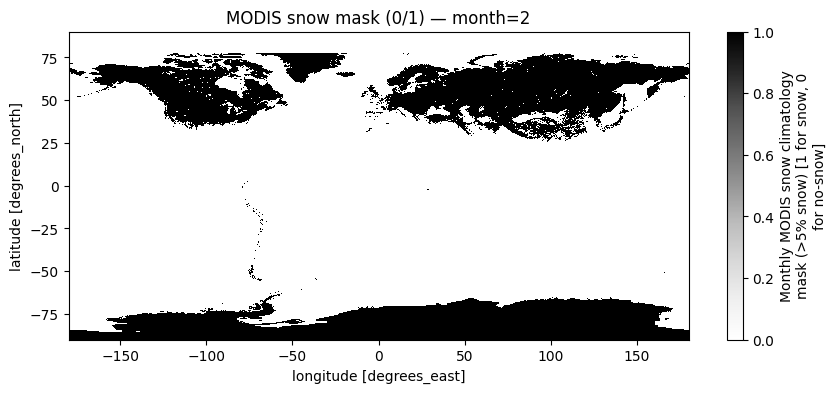

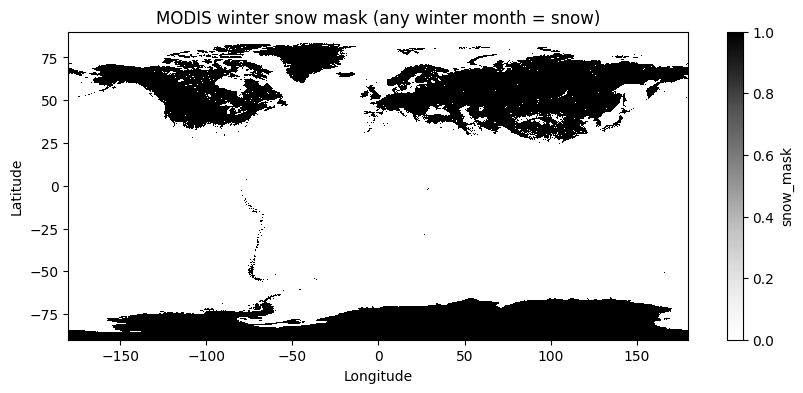

In [15]:
# Load MODIS snow climatology
# Select winter months (Dec–Mar)
# Create a persistent winter snow mask (any winter month)
# load snow mask climatology (MODIS NSIDC)
snow_path = "/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_mask_monthly_0p05deg.nc"
snow = xr.open_dataset(snow_path)

# pick the data_var snow_mask
snow_var_name = list(snow.data_vars)[0]
snow_clim = snow[snow_var_name]  # dims: month, lat, lon, values 0/1

# pick snow months Dec–Mar
snow_winter = snow_clim.sel(month=[12, 1, 2, 3])

snow_winter.isel(month=2).plot(
    x="lon", y="lat",
    cmap="Greys",
    vmin=0, vmax=1,
    figsize=(10, 4)
)
plt.title(f"MODIS snow mask (0/1) — month={int(snow_winter.month.values[2])}")
plt.show()

# # 2D boolean map: True where it is snow-covered in any winter month
snow_mask = (snow_winter == 1).any(dim="month")

snow_mask.plot(
    x="lon", y="lat",
    cmap="Greys",
    figsize=(10, 4),
    add_colorbar=True
)

plt.title("MODIS winter snow mask (any winter month = snow)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [16]:
# Load cropland
# Standardize coordinates (x/y → lon/lat)
# Ensure latitude ordering
# Convert cropland to boolean presence

# load cropland (2019)
crop_path = "/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc"
crop = xr.open_dataset(crop_path)
crop_var_name = list(crop.data_vars)[1]
cropland = crop[crop_var_name]  # e.g., cropland fraction

# If coordinates are named x/y, rename to lon/lat once:
if "x" in cropland.dims and "y" in cropland.dims:
    cropland = cropland.rename({"y": "lat", "x": "lon"})

# sort latitude ascending
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

# make a boolean: True where cropland exists
cropland_any = cropland > 0
cropland_any

<xarray.DataArray 'cropland' (lat: 5200, lon: 14000)> Size: 73MB
array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(5200, 14000))
Coordinates:
  * lat      (lat) float64 42kB -59.99 -59.96 -59.94 ... 69.94 69.96 69.99
  * lon      (lon) float64 112kB -170.0 -170.0 -169.9 ... 179.9 180.0 180.0

In [17]:
# Which basin does each grid cell belong to?
# 3D mask (region, lat, lon) with overlap allowed
mask3d = regions.mask_3D(era5_data["lon"], era5_data["lat"], drop=False)

# Convert to 2D "region id" map by choosing the first True region along region axis
# (True->1, False->0; idxmax returns first max index)
reg2d = mask3d.astype(np.int8).idxmax(dim="region")

# Cells not in any basin become 0 by idxmax; fix them to NaN
reg2d = reg2d.where(mask3d.any("region"))

reg2d = reg2d.load()

# weights -- Because grid cells shrink toward the poles.
w2d = np.cos(np.deg2rad(era5_data["lat"])).broadcast_like(reg2d).load()

print("reg2d:", reg2d.dims, reg2d.shape)

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


reg2d: ('lat', 'lon') (721, 1440)


In [18]:
# Regrid snow + crop masks to ERA5 (nearest)

snow_on_era5 = snow_mask.astype("float32").interp(
    lat=era5_data["lat"], lon=era5_data["lon"], method="nearest"
) > 0.5
snow_on_era5 = snow_on_era5.load()

crop_on_era5 = cropland_any.astype("float32").interp(
    lat=era5_data["lat"], lon=era5_data["lon"], method="nearest"
) > 0.5
crop_on_era5 = crop_on_era5.load()

print("snow_on_era5:", snow_on_era5.dims, snow_on_era5.shape)
print("crop_on_era5:", crop_on_era5.dims, crop_on_era5.shape)

snow_on_era5: ('lat', 'lon') (721, 1440)
crop_on_era5: ('lat', 'lon') (721, 1440)


In [19]:
# flattening the 2D spatial grid (lat, lon) into a single 1D spatial dimension (z)

# Create a single stacked dimension name
SPATIAL_DIM = "z"  # name for stacked (lat, lon)
# Stack reg2d and w2d once (reuse everywhere)
reg_s = reg2d.stack({SPATIAL_DIM: ("lat", "lon")}).load()
w_s   = w2d.stack({SPATIAL_DIM: ("lat", "lon")}).load()
# Stack masks 
snow_s = snow_on_era5.stack({SPATIAL_DIM: ("lat", "lon")}).load()
crop_s = crop_on_era5.stack({SPATIAL_DIM: ("lat", "lon")}).load()

In [20]:
# sanity check / debugging block to see how many ERA5 grid cells belong to a particular basin and how many of those overlap snow and cropland.
    
r = 153
z = "z"

reg_s  = reg2d.stack({z: ("lat","lon")})
snow_s = snow_on_era5.stack({z: ("lat","lon")})
crop_s = crop_on_era5.stack({z: ("lat","lon")})

in_basin = (reg_s == r)

print("Cells in basin:", int(in_basin.sum()))
print("Cells in basin ∩ snow:", int((in_basin & snow_s).sum()))
print("Cells in basin ∩ crop:", int((in_basin & crop_s).sum()))

Cells in basin: 277
Cells in basin ∩ snow: 266
Cells in basin ∩ crop: 146


In [21]:
# area-weighted snow and cropland fractions for every basin, then keeps only basins that meet minimum thresholds.
def basin_fraction_all_stacked(reg_s, w_s, cond_s, spatial_dim="z"):
    # only points that belong to some basin
    in_basin = reg_s.notnull()

    basin_area = w_s.where(in_basin).groupby(reg_s).sum(dim=spatial_dim)
    cond_area  = w_s.where(in_basin & cond_s).groupby(reg_s).sum(dim=spatial_dim)

    return cond_area / basin_area

snow_frac_all = basin_fraction_all_stacked(reg_s, w_s, snow_s, spatial_dim=SPATIAL_DIM)
crop_frac_all = basin_fraction_all_stacked(reg_s, w_s, crop_s, spatial_dim=SPATIAL_DIM)

SNOW_FRAC_MIN = 0.05
CROP_FRAC_MIN = 0.05
eligible = (snow_frac_all >= SNOW_FRAC_MIN) & (crop_frac_all >= CROP_FRAC_MIN)

print("Eligible basins:", int(eligible.sum()))

Eligible basins: 174


In [22]:
# basin-level area-weighted monthly time series
def basin_weighted_mean_all_stacked(da, reg_s, w_s, cond_s, spatial_dim="z"):
    """
    da: (time, lat, lon)  [or lat/lon only]
    reg_s, w_s, cond_s: (z)
    returns: (time, group) where group corresponds to basin index (0..n-1)
    """
    da_s = da.stack({spatial_dim: ("lat", "lon")})

    valid = reg_s.notnull() & cond_s

    num = (da_s * w_s).where(valid).groupby(reg_s).sum(dim=spatial_dim)
    den = (w_s).where(valid).groupby(reg_s).sum(dim=spatial_dim)

    return num / den

swe_all = basin_weighted_mean_all_stacked(era5_data["swe"], reg_s, w_s, snow_s, spatial_dim=SPATIAL_DIM).where(eligible)
eto_all = basin_weighted_mean_all_stacked(era5_data["eto"], reg_s, w_s, crop_s, spatial_dim=SPATIAL_DIM).where(eligible)

print("swe_all dims:", swe_all.dims, "shape:", swe_all.shape)
print("eto_all dims:", eto_all.dims, "shape:", eto_all.shape)

swe_all dims: ('time', 'region') shape: (900, 587)
eto_all dims: ('time', 'region') shape: (900, 587)


In [23]:
# checking whether region index 153 has valid SWE/ETo time series after masking with eligible.
r = 153
print("swe_all all NaN?:", bool(np.isnan(swe_all.isel(region=r)).all()))
print("eto_all all NaN?:", bool(np.isnan(eto_all.isel(region=r)).all()))

swe_all all NaN?: False
eto_all all NaN?: False


In [24]:
print("swe_all region coord (first 20):", swe_all["region"].values[:20])
print("min/max region coord:", swe_all["region"].values.min(), swe_all["region"].values.max())

swe_all region coord (first 20): [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19.]
min/max region coord: 0.0 601.0


In [25]:
# checking whether basin has valid SWE and ETo outputs.
bid = 7040007830
rid = main_ids_valid.index(bid)

print("region label:", rid)
print("swe_all all NaN (sel):", bool(np.isnan(swe_all.sel(region=rid)).all()))
print("eto_all all NaN (sel):", bool(np.isnan(eto_all.sel(region=rid)).all()))

region label: 455
swe_all all NaN (sel): True
eto_all all NaN (sel): True


In [26]:
full_region = xr.DataArray(np.arange(len(main_ids_valid)), dims="region", name="region")

swe_all = swe_all.reindex(region=full_region)
eto_all = eto_all.reindex(region=full_region)

snow_frac_all = snow_frac_all.reindex(region=full_region)
crop_frac_all = crop_frac_all.reindex(region=full_region)
eligible = eligible.reindex(region=full_region)

In [27]:
def water_year_from_time(da_time):
    # Water year Oct–Sep, labeled by ending year
    t = pd.to_datetime(da_time.values)
    wy = t.year + (t.month >= 10).astype(int)
    return xr.DataArray(wy, dims=("time",), coords={"time": da_time}, name="wy")

# WY coordinate
wy = water_year_from_time(swe_all["time"])

# Choose seasons
SWE_MONTHS = [12, 1, 2, 3]      # Dec–Mar
ETO_MONTHS = [4, 5, 6, 7, 8, 9]    # Apr–Sep

# Subset months + attach WY
swe_season = swe_all.where(swe_all["time"].dt.month.isin(SWE_MONTHS), drop=True)
eto_season = eto_all.where(eto_all["time"].dt.month.isin(ETO_MONTHS), drop=True)

swe_season = swe_season.assign_coords(wy=wy.sel(time=swe_season.time))
eto_season = eto_season.assign_coords(wy=wy.sel(time=eto_season.time))

# WY metrics: SWE peak (winter), ETo summer mean
swe_peak = swe_season.groupby("wy").max("time")      # dims: (wy, region)
eto_summer = eto_season.groupby("wy").mean("time")   # dims: (wy, region)

print("swe_peak:", swe_peak.dims, swe_peak.shape)
print("eto_summer:", eto_summer.dims, eto_summer.shape)

# For each water year and basin, computes maximum winter SWE and mean warm-season ETo.

swe_peak: ('wy', 'region') (76, 602)
eto_summer: ('wy', 'region') (75, 602)


In [28]:
# water-year alignment check between your seasonal SWE and ETo datasets.
# WYs present in each dataset
wy_swe = set(swe_peak.wy.values)
wy_eto = set(eto_summer.wy.values)

print("First SWE WY:", min(wy_swe), " Last SWE WY:", max(wy_swe))
print("First ETo WY:", min(wy_eto), " Last ETo WY:", max(wy_eto))

# Which WYs exist in SWE but not ETo?
only_in_swe = sorted(wy_swe - wy_eto)

# Which WYs exist in ETo but not SWE?
only_in_eto = sorted(wy_eto - wy_swe)

print("\nWY only in SWE:", only_in_swe)
print("WY only in ETo:", only_in_eto)

First SWE WY: 1950  Last SWE WY: 2025
First ETo WY: 1950  Last ETo WY: 2024

WY only in SWE: [np.int64(2025)]
WY only in ETo: []


In [29]:
q_lo, q_hi = 0.30, 0.70

# Ensure same WYs
swe_peak, eto_summer = xr.align(swe_peak, eto_summer, join="inner")

# Valid basin-years (both metrics exist)
valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)

# thresholds per basin (computed only from valid years)
swe_tlow  = swe_peak.where(valid_wy).quantile(q_lo, dim="wy", skipna=True)
eto_thigh = eto_summer.where(valid_wy).quantile(q_hi, dim="wy", skipna=True)

low_swe  = (swe_peak <= swe_tlow) & valid_wy
high_eto = (eto_summer >= eto_thigh) & valid_wy

normal        = (~low_swe) & (~high_eto) & valid_wy
low_swe_only  = (low_swe) & (~high_eto) & valid_wy
high_eto_only = (~low_swe) & (high_eto) & valid_wy
compound      = (low_swe) & (high_eto) & valid_wy

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


In [30]:
print("swe_peak:", swe_peak.dims, swe_peak.shape)
print("eto_summer:", eto_summer.dims, eto_summer.shape)

swe_peak: ('wy', 'region') (75, 602)
eto_summer: ('wy', 'region') (75, 602)


In [31]:
bid = 7040007830
r = main_ids_valid.index(bid)
wy_vals = swe_peak.wy.values.astype(int)

print("Basin", bid, "region", r)

# How many valid WYs exist?
valid_r = valid_wy.isel(region=r)
print("Valid WY count:", int(valid_r.sum()))

# Show if the basin has any data at all
print("Any SWE data:", bool(np.isfinite(swe_peak.isel(region=r)).any()))
print("Any ETo data:", bool(np.isfinite(eto_summer.isel(region=r)).any()))

# If no valid years, show why (SWE missing vs ETo missing)
if int(valid_r.sum()) == 0:
    n_swe = int(np.isfinite(swe_peak.isel(region=r)).sum())
    n_eto = int(np.isfinite(eto_summer.isel(region=r)).sum())
    print("Finite SWE years:", n_swe)
    print("Finite ETo years:", n_eto)

# Only print years for classes where valid
def years_where(mask_da):
    m = mask_da.isel(region=r).values
    return wy_vals[m]

print("normal WYs:", years_where(normal))
print("low SWE only WYs:", years_where(low_swe_only))
print("high ETo only WYs:", years_where(high_eto_only))
print("compound WYs:", years_where(compound))

Basin 7040007830 region 455
Valid WY count: 0
Any SWE data: False
Any ETo data: False
Finite SWE years: 0
Finite ETo years: 0
normal WYs: []
low SWE only WYs: []
high ETo only WYs: []
compound WYs: []


In [32]:
good_bids = []

for r, bid in enumerate(main_ids_valid):
    n_valid = int(valid_wy.isel(region=r).sum())

    n_compound = int(compound.isel(region=r).sum())
    n_low_swe = int(low_swe_only.isel(region=r).sum())
    n_high_eto = int(high_eto_only.isel(region=r).sum())

    if n_valid > 0 and (n_compound > 0 or n_low_swe > 0 or n_high_eto > 0):
        good_bids.append({
            "region": r,
            "HYBAS_ID": bid,
            "valid_years": n_valid,
            "low_swe_only": n_low_swe,
            "high_eto_only": n_high_eto,
            "compound": n_compound
        })

good_df = pd.DataFrame(good_bids)
good_df

,region,HYBAS_ID,valid_years,low_swe_only,high_eto_only,compound
0,40,1040029430,75,12,12,11
1,42,1040029700,75,12,12,11
2,105,2040000010,75,13,13,10
3,106,2040003440,75,13,13,10
4,107,2040003550,75,10,10,13
...,...,...,...,...,...,...
169,581,7040073630,75,14,14,9
170,582,7040073690,75,15,15,8
171,583,7040073720,75,11,11,12
172,584,7040073780,75,11,11,12


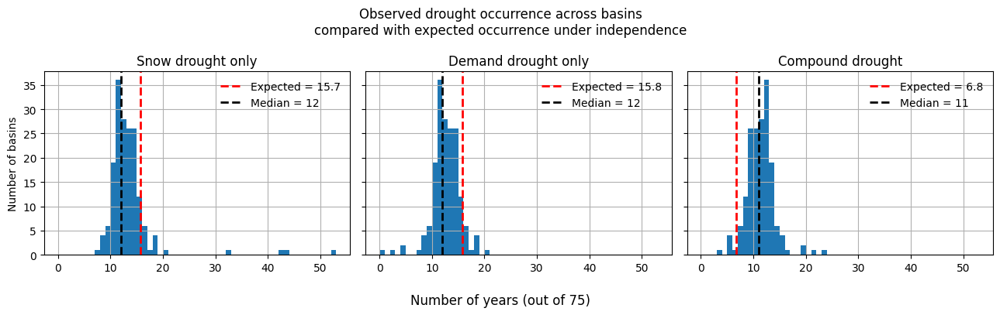

In [33]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 75 * 0.3 * 0.7),
    ("high_eto_only", "Demand drought only", 75 * 0.7 * 0.3),
    ("compound", "Compound drought", 75 * 0.3 * 0.3)
]

for i, (ax, (col, title, expected)) in enumerate(zip(axes, vars_to_plot)):

    good_df[col].hist(
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        ax=ax
    )

    # expected under independence
    ax.axvline(
        expected,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    # observed median
    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(title)

    # only left panel gets y label
    if i == 0:
        ax.set_ylabel("Number of basins")

    # remove repeated y labels/ticks
    if i > 0:
        ax.set_ylabel("")
        ax.tick_params(labelleft=False)

    ax.legend(frameon=False)

# common x label
fig.supxlabel("Number of years (out of 75)")

plt.suptitle(
    "Observed drought occurrence across basins\n"
    "compared with expected occurrence under independence"
)

plt.tight_layout()
plt.show()

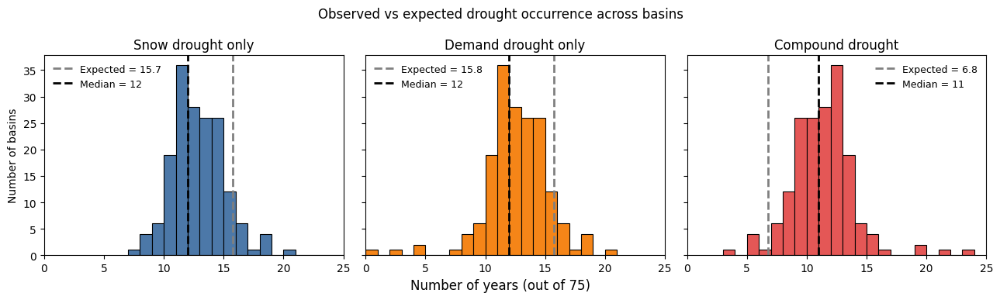

In [34]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 75 * 0.3 * 0.7, "#4C78A8"),   # blue
    ("high_eto_only", "Demand drought only", 75 * 0.7 * 0.3, "#F58518"), # orange
    ("compound", "Compound drought", 75 * 0.3 * 0.3, "#E45756")          # red
]

for i, (ax, (col, title, expected, color)) in enumerate(zip(axes, vars_to_plot)):

    ax.hist(
        good_df[col],
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    # expected under independence
    ax.axvline(
        expected,
        color="0.5",      # gray
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    # observed median
    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(title)

    if i == 0:
        ax.set_ylabel("Number of basins")
    else:
        ax.tick_params(labelleft=False)

    ax.legend(
        frameon=False,
        fontsize=9
    )

fig.supxlabel("Number of years (out of 75)", y=0.06)

plt.suptitle(
    "Observed vs expected drought occurrence across basins"
)

for ax in axes:
    ax.set_xlim(0, 25)
    
plt.tight_layout()
plt.show()

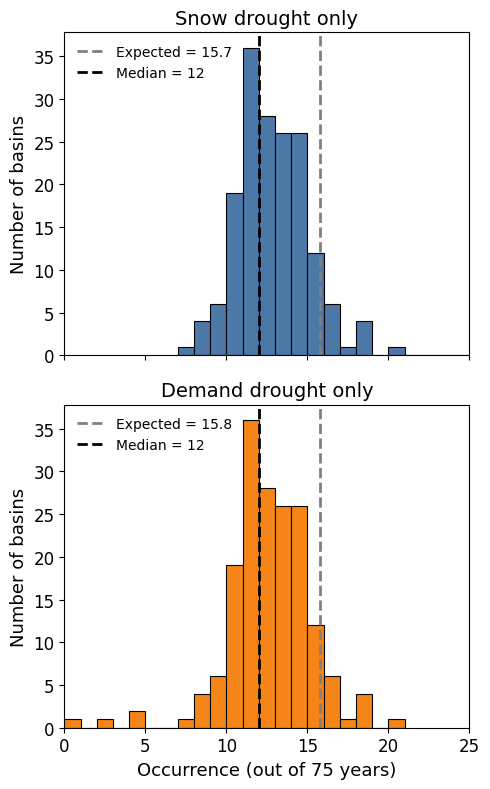

In [35]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(5, 8),
    sharex=True,
    sharey=True
)

vars_to_plot = [
    ("low_swe_only", "Snow drought only", 75 * 0.3 * 0.7, "#4C78A8"),
    ("high_eto_only", "Demand drought only", 75 * 0.7 * 0.3, "#F58518")
]

for i, (ax, (col, title, expected, color)) in enumerate(zip(axes, vars_to_plot)):

    ax.hist(
        good_df[col],
        bins=np.arange(
            good_df[col].min(),
            good_df[col].max() + 2
        ),
        color=color,
        edgecolor="black",
        linewidth=0.8
    )

    ax.axvline(
        expected,
        color="0.5",
        linestyle="--",
        linewidth=2,
        label=f"Expected = {expected:.1f}"
    )

    median = good_df[col].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median = {median:.0f}"
    )

    ax.set_title(
        title,
        fontsize=14
    )

    ax.set_ylabel(
        "Number of basins",
        fontsize=13
    )

    ax.tick_params(
        axis="both",
        labelsize=12
    )

    ax.legend(
    loc="upper left",
    frameon=False,
    fontsize=10,
    handlelength=2
    )

    ax.set_xlim(0, 25)

axes[-1].set_xlabel(
    "Occurrence (out of 75 years)",
    fontsize=13
)

plt.tight_layout()

plt.show()

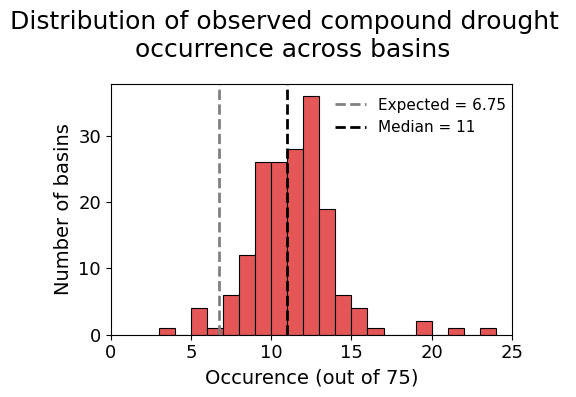

In [36]:
fig, ax = plt.subplots(
    figsize=(5, 4)
)

expected = 75 * 0.3 * 0.3   # 6.75 years

ax.hist(
    good_df["compound"],
    bins=np.arange(
        good_df["compound"].min(),
        good_df["compound"].max() + 2
    ),
    color="#E45756",
    edgecolor="black",
    linewidth=0.8
)

# expected under independence
ax.axvline(
    expected,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected:.2f}"
)

# observed median
median = good_df["compound"].median()

ax.axvline(
    median,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median:.0f}"
)

ax.set_xlim(0, 25)

ax.set_xlabel("Occurence (out of 75)", fontsize=14)
ax.set_ylabel("Number of basins", fontsize=14)

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.02, 1.0),  # move right + slightly down
    frameon=False,
    fontsize=11,
    handlelength=2
)

ax.tick_params(
    axis="both",
    labelsize=13
)


plt.suptitle(
    "Distribution of observed compound drought \n occurrence across basins", fontsize=18
)

plt.tight_layout()
plt.show()

In [37]:
# hb.columns

In [38]:
# bid = 7040007830

# ax = hb.loc[hb["HYBAS_ID"] == bid].plot(figsize=(8,8))

# ax.set_title(f"Basin {bid}")

In [39]:
r = 153
SPATIAL_DIM = "z"

reg_s = reg2d.stack({SPATIAL_DIM: ("lat", "lon")})
n_cells = int((reg_s == r).sum().values)
print("ERA5 cells assigned to this region:", n_cells)

ERA5 cells assigned to this region: 277


In [40]:
# ------------------------------------------------------------
# Basin-level counts + frequencies of each class (robust)
#  - keeps ALL basins (0..len(main_ids_valid)-1)
#  - basins with no valid WYs stay NaN (so they plot as missing/gray)
#  - freq_sum is only computed when all 4 components exist
# ------------------------------------------------------------

# 1) Denominator: WYs with both metrics (per basin)
valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)   # dims: (wy, region)

# Make a FULL region axis so everything lines up (important!)
full_region = xr.DataArray(np.arange(len(main_ids_valid)), dims="region", name="region")

# Reindex to full region axis (missing basins become NaN / 0 appropriately)
valid_wy = valid_wy.reindex(region=full_region)

compound      = compound.reindex(region=full_region)
low_swe_only  = low_swe_only.reindex(region=full_region)
high_eto_only = high_eto_only.reindex(region=full_region)
normal        = normal.reindex(region=full_region)

n_years = valid_wy.sum("wy")  # dims: (region)

# 2) Counts (restrict to valid WYs)
n_compound = (compound & valid_wy).sum("wy")
n_low      = (low_swe_only & valid_wy).sum("wy")
n_high     = (high_eto_only & valid_wy).sum("wy")
n_normal   = (normal & valid_wy).sum("wy")

# 3) Frequencies (NaN where n_years == 0)
freq_compound = xr.where(n_years > 0, n_compound / n_years, np.nan)
freq_low      = xr.where(n_years > 0, n_low      / n_years, np.nan)
freq_high     = xr.where(n_years > 0, n_high     / n_years, np.nan)
freq_normal   = xr.where(n_years > 0, n_normal   / n_years, np.nan)

# 4) xarray sanity check (only meaningful where n_years > 0)
freq_sum = freq_compound + freq_low + freq_high + freq_normal
print(freq_sum.where(n_years > 0).to_series().describe())

# ------------------------------------------------------------
# Convert to dataframe (ALL basins, by MAIN_BAS)
# ------------------------------------------------------------

freq_df = pd.DataFrame({
    "region": full_region.values.astype(int),
    "MAIN_BAS": main_ids_valid,

    "n_years": n_years.values,
    "n_compound": n_compound.values,
    "n_low_swe_only": n_low.values,
    "n_high_eto_only": n_high.values,
    "n_normal": n_normal.values,

    "freq_compound": freq_compound.values,
    "freq_low_swe_only": freq_low.values,
    "freq_high_eto_only": freq_high.values,
    "freq_normal": freq_normal.values,
})

# Strict freq_sum: only compute if all 4 frequencies exist (otherwise NaN)
cols = ["freq_compound", "freq_low_swe_only", "freq_high_eto_only", "freq_normal"]
freq_df["freq_sum"] = freq_df[cols].sum(axis=1, min_count=4)

print(freq_df.loc[freq_df["n_years"] > 0, "freq_sum"].describe())
print("Basins with data (n_years>0):", int((freq_df["n_years"] > 0).sum()))
print("Basins with no data (n_years==0):", int((freq_df["n_years"] == 0).sum()))

# ------------------------------------------------------------
# Attach to basin polygons for mapping
# ------------------------------------------------------------

basins_diss = hb_simple.dissolve(by="MAIN_BAS").reset_index()

basins_diss = basins_diss.merge(
    freq_df.drop(columns=["region"]),
    on="MAIN_BAS",
    how="left"
)

count    174.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64
count    174.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: freq_sum, dtype: float64
Basins with data (n_years>0): 174
Basins with no data (n_years==0): 428


In [41]:
print(freq_df.columns)

Index(['region', 'MAIN_BAS', 'n_years', 'n_compound', 'n_low_swe_only',
       'n_high_eto_only', 'n_normal', 'freq_compound', 'freq_low_swe_only',
       'freq_high_eto_only', 'freq_normal', 'freq_sum'],
      dtype='object')


In [42]:
freq_df["n_years"].describe()

count    602.000000
mean      21.677741
std       34.026893
min        0.000000
25%        0.000000
50%        0.000000
75%       75.000000
max       75.000000
Name: n_years, dtype: float64

In [43]:
global_fraction_cd = freq_df.loc[freq_df["n_years"] > 0, "n_compound"].sum() / \
                  freq_df.loc[freq_df["n_years"] > 0, "n_years"].sum()
global_fraction_sd = freq_df.loc[freq_df["n_years"] > 0, "n_low_swe_only"].sum() / \
                  freq_df.loc[freq_df["n_years"] > 0, "n_years"].sum()
global_fraction_dd = freq_df.loc[freq_df["n_years"] > 0, "n_high_eto_only"].sum() / \
                  freq_df.loc[freq_df["n_years"] > 0, "n_years"].sum()
global_fraction_nd = freq_df.loc[freq_df["n_years"] > 0, "n_normal"].sum() / \
                  freq_df.loc[freq_df["n_years"] > 0, "n_years"].sum()

print(global_fraction_cd)
print(global_fraction_sd)
print(global_fraction_dd)
print(global_fraction_nd)

0.14482758620689656
0.17402298850574713
0.1618390804597701
0.5193103448275862


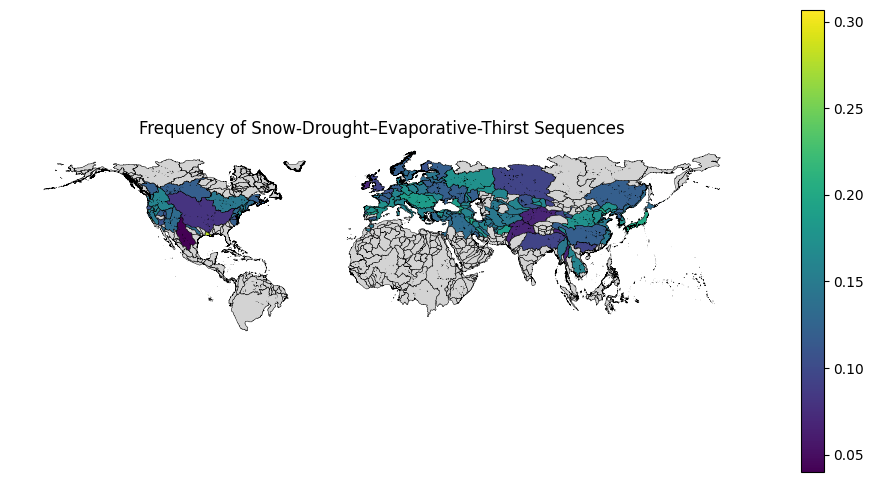

In [44]:
fig, ax = plt.subplots(figsize=(12,6))

basins_diss.plot(
    column="freq_compound",
    cmap="viridis",
    linewidth=0.3,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgray",
        "label": "No data"
    },
    ax=ax
)

ax.set_title("Frequency of Snow-Drought–Evaporative-Thirst Sequences")
ax.set_axis_off()

plt.show()

In [45]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Reds"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

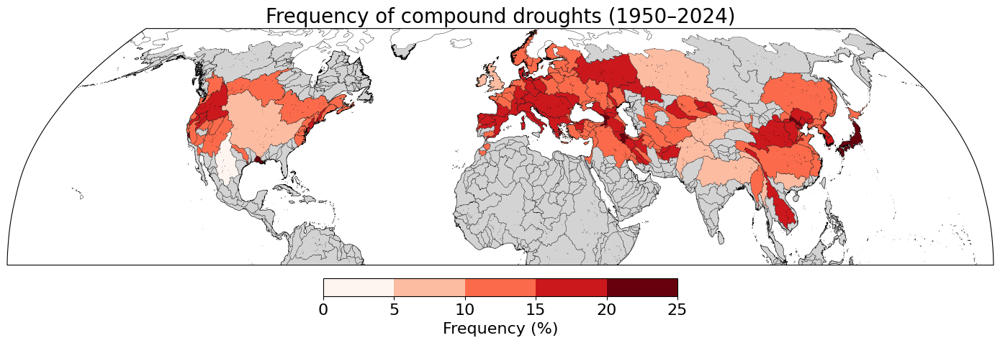

In [46]:
plot_frequency_map(
    basins_diss,
    column="freq_compound",
    title="Frequency of compound droughts (1950–2024)"
)

In [47]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Blues"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

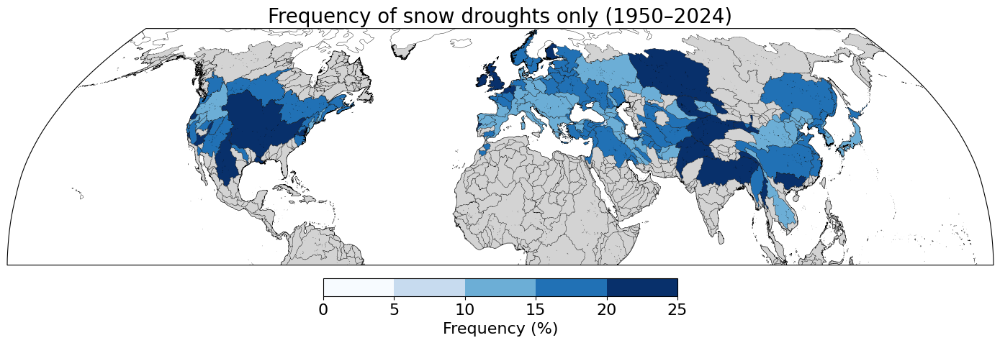

In [48]:
plot_frequency_map(
    basins_diss,
    column="freq_low_swe_only",
    title="Frequency of snow droughts only (1950–2024)"
)

In [49]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

def plot_frequency_map(gdf, column, title, cmap="Oranges"):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # bins in FRACTION units
    bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "label": "No data"
        },
        ax=ax
    )

    sm = cm.ScalarMappable(
        norm=norm,
        cmap=cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.03,
        fraction=0.04,
        boundaries=bounds,
        ticks=bounds
    )

    # show percent labels
    cbar.set_ticklabels(
        ["0", "5", "10", "15", "20", "25"]
    )

    cbar.set_label(
        "Frequency (%)",
        fontsize=16
    )

    cbar.ax.tick_params(
        labelsize=16
    )

    ax.set_title(
        title,
        fontsize=20
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

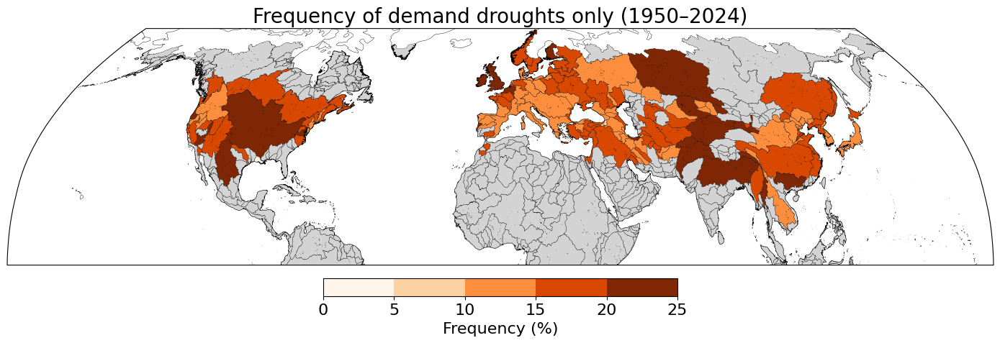

In [50]:
plot_frequency_map(
    basins_diss,
    column="freq_high_eto_only",
    title="Frequency of demand droughts only (1950–2024)"
)

In [51]:
# ------------------------------------------------------------
# Expected frequencies under independence
# ------------------------------------------------------------
expected = {
    "compound": 0.3 * 0.3,        # low SWE AND high ETo = 0.09
    "snow":     0.3 * 0.7,        # low SWE only = 0.21
    "demand":   0.7 * 0.3,        # high ETo only = 0.21
    "normal":   0.7 * 0.7         # neither = 0.49
}

# ------------------------------------------------------------
# Binomial p-values
# ------------------------------------------------------------
def compute_binomial_pvals(freq_df, count_col, p0):
    pvals = []

    for _, row in freq_df.iterrows():
        n = row["n_years"]
        k = row[count_col]

        if n > 0 and pd.notna(k):
            pvals.append(
                binomtest(
                    int(k),
                    int(n),
                    p=p0,
                    alternative="two-sided"
                ).pvalue
            )
        else:
            pvals.append(np.nan)

    return pvals


freq_df["p_compound"] = compute_binomial_pvals(
    freq_df, "n_compound", expected["compound"]
)

freq_df["p_snow"] = compute_binomial_pvals(
    freq_df, "n_low_swe_only", expected["snow"]
)

freq_df["p_demand"] = compute_binomial_pvals(
    freq_df, "n_high_eto_only", expected["demand"]
)

freq_df["p_normal"] = compute_binomial_pvals(
    freq_df, "n_normal", expected["normal"]
)

# ------------------------------------------------------------
# Merge p-values into basin polygons
# Avoid duplicate columns if rerunning
# ------------------------------------------------------------
pval_cols = [
    "p_compound",
    "p_snow",
    "p_demand",
    "p_normal"
]

basins_diss = basins_diss.drop(
    columns=[c for c in pval_cols if c in basins_diss.columns],
    errors="ignore"
)

basins_diss = basins_diss.merge(
    freq_df[["MAIN_BAS"] + pval_cols],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Significance masks
# ------------------------------------------------------------
alpha = 0.05

basins_diss["sig_compound"] = basins_diss["p_compound"] < alpha
basins_diss["sig_snow"]     = basins_diss["p_snow"] < alpha
basins_diss["sig_demand"]   = basins_diss["p_demand"] < alpha
basins_diss["sig_normal"]   = basins_diss["p_normal"] < alpha

# ------------------------------------------------------------
# Frequency anomalies: observed - expected
# ------------------------------------------------------------
basins_diss["compound_anom"] = (
    basins_diss["freq_compound"] - expected["compound"]
)

basins_diss["snow_drought_anom"] = (
    basins_diss["freq_low_swe_only"] - expected["snow"]
)

basins_diss["demand_drought_anom"] = (
    basins_diss["freq_high_eto_only"] - expected["demand"]
)

basins_diss["non_drought_anom"] = (
    basins_diss["freq_normal"] - expected["normal"]
)

# ------------------------------------------------------------
# Percent difference from expected
# ------------------------------------------------------------
basins_diss["compound_pct_diff"] = (
    basins_diss["compound_anom"] / expected["compound"]
) * 100

basins_diss["snow_drought_pct_diff"] = (
    basins_diss["snow_drought_anom"] / expected["snow"]
) * 100

basins_diss["demand_drought_pct_diff"] = (
    basins_diss["demand_drought_anom"] / expected["demand"]
) * 100

basins_diss["non_drought_pct_diff"] = (
    basins_diss["non_drought_anom"] / expected["normal"]
) * 100

# ------------------------------------------------------------
# Summary counts
# ------------------------------------------------------------
n_total = basins_diss["p_compound"].notna().sum()

n_sig_compound = basins_diss["sig_compound"].sum()
n_sig_snow     = basins_diss["sig_snow"].sum()
n_sig_demand   = basins_diss["sig_demand"].sum()
n_sig_normal   = basins_diss["sig_normal"].sum()

summary = pd.DataFrame({
    "class": [
        "compound",
        "snow_only",
        "demand_only",
        "normal"
    ],
    "expected_frequency": [
        expected["compound"],
        expected["snow"],
        expected["demand"],
        expected["normal"]
    ],
    "n_significant": [
        n_sig_compound,
        n_sig_snow,
        n_sig_demand,
        n_sig_normal
    ],
    "pct_significant": [
        100 * n_sig_compound / n_total,
        100 * n_sig_snow / n_total,
        100 * n_sig_demand / n_total,
        100 * n_sig_normal / n_total
    ]
})

print(summary)

         class  expected_frequency  n_significant  pct_significant
0     compound                0.09             70        40.229885
1    snow_only                0.21              9         5.172414
2  demand_only                0.21              9         5.172414
3       normal                0.49              4         2.298851


In [52]:
# ------------------------------------------------------------
# Direction of significant anomalies
# ------------------------------------------------------------
classes = {
    "Compound drought": ("sig_compound", "compound_pct_diff"),
    "Snow drought only": ("sig_snow", "snow_drought_pct_diff"),
    "Demand drought only": ("sig_demand", "demand_drought_pct_diff"),
    "No drought": ("sig_normal", "non_drought_pct_diff")
}

for name, (sig_col, diff_col) in classes.items():

    pos_sig = (
        basins_diss[sig_col] &
        (basins_diss[diff_col] > 0)
    )

    neg_sig = (
        basins_diss[sig_col] &
        (basins_diss[diff_col] < 0)
    )

    print(name)
    print("Significantly higher than expected:", int(pos_sig.sum()))
    print("Significantly lower than expected:", int(neg_sig.sum()))
    print()

Compound drought
Significantly higher than expected: 70
Significantly lower than expected: 0

Snow drought only
Significantly higher than expected: 4
Significantly lower than expected: 5

Demand drought only
Significantly higher than expected: 0
Significantly lower than expected: 9

No drought
Significantly higher than expected: 0
Significantly lower than expected: 4



In [53]:
# ------------------------------------------------------------
# Discrete coolwarm colormap with white center bin (-10 to 10)
# ------------------------------------------------------------
bounds = np.array([-60, -50, -40, -30, -20, -10, 10, 20,  30,  40,  50,  60])

base = plt.get_cmap("coolwarm")

cmap_colors = base(np.linspace(0, 1, len(bounds) - 1))

# bin index corresponding to -10 to +10
center_idx = list(bounds[:-1]).index(-10)
cmap_colors[center_idx] = [1, 1, 1, 1]

disc_cmap = colors.ListedColormap(cmap_colors)

disc_norm = colors.BoundaryNorm(
    boundaries=bounds,
    ncolors=disc_cmap.N,
    clip=True
)

# ------------------------------------------------------------
# Plot function
# ------------------------------------------------------------
def plot_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # Base map
    gdf.plot(
        column=column,
        cmap=disc_cmap,
        norm=disc_norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    # Hatching for significant basins
    gdf[gdf[sig_col]].plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        hatch="///",
        linewidth=0,
        transform=ccrs.PlateCarree()
    )

    # Colorbar
    sm = cm.ScalarMappable(
        norm=disc_norm,
        cmap=disc_cmap
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=np.arange(-80, 81, 20),
        pad=0.03,
        fraction=0.04,
        spacing="proportional"
    )

    cbar.set_label(
        "% difference from expected frequency",
        fontsize=14
    )
    cbar.ax.tick_params(labelsize=14)

    # Hatch legend
    hatch_patch = mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch="///",
        label="p < 0.05"
    )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=12
    )

    ax.set_title(title, fontsize=18)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

    plt.tight_layout()
    plt.show()

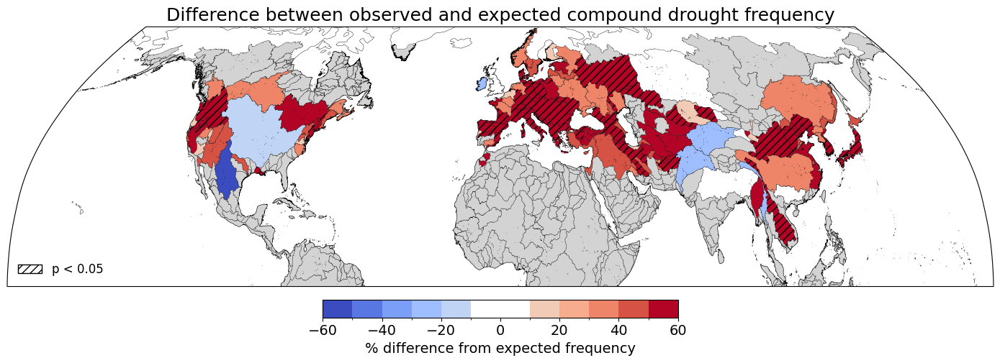

In [54]:
plot_with_hatching(
    basins_diss,
    column="compound_pct_diff",
    sig_col="sig_compound",
    title="Difference between observed and expected compound drought frequency"
)

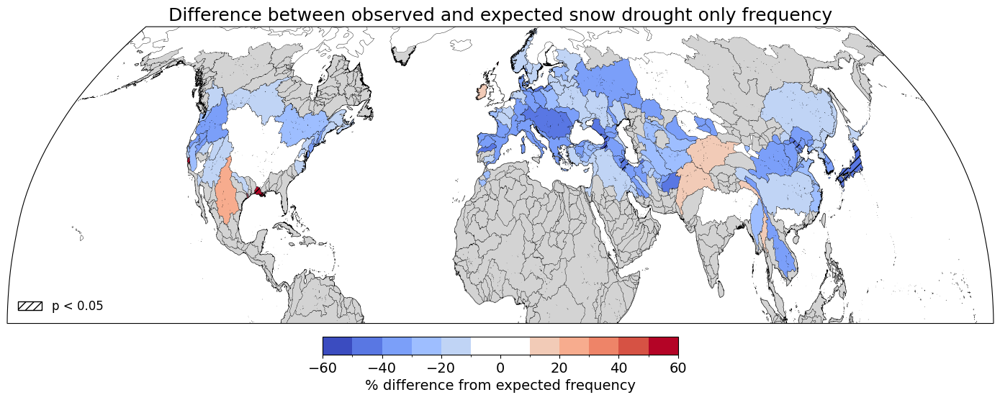

In [55]:
plot_with_hatching(
    basins_diss,
    column="snow_drought_pct_diff",
    sig_col="sig_snow",
    title="Difference between observed and expected snow drought only frequency"
)

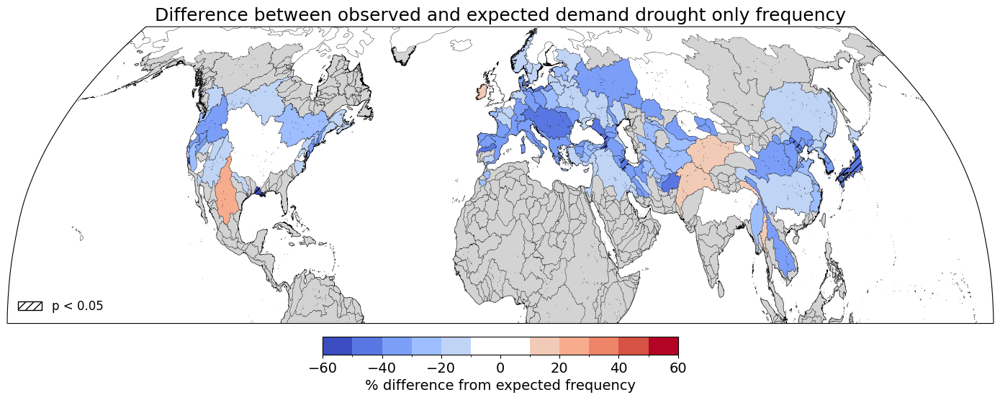

In [56]:
plot_with_hatching(
    basins_diss,
    column="demand_drought_pct_diff",
    sig_col="sig_demand",
    title="Difference between observed and expected demand drought only frequency"
)

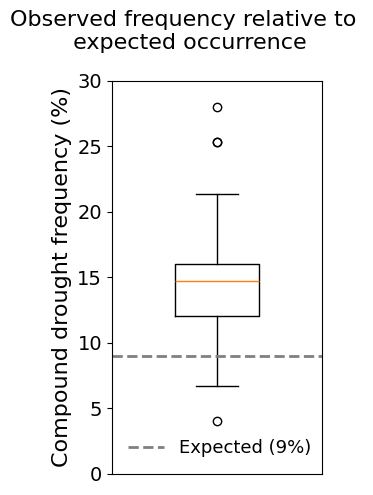

In [57]:
plt.figure(figsize=(3, 5))

vals = (
    freq_df["freq_compound"]
    .dropna()
    * 100
)

plt.boxplot(
    vals,
    widths=0.4
)

plt.axhline(
    y=9,
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Expected (9%)"
)

plt.ylabel(
    "Compound drought frequency (%)",
    fontsize=16
)

# Set y axis
plt.ylim(0, 30)

plt.yticks(
    [0, 5, 10, 15, 20, 25, 30],
    fontsize=14
)

plt.xticks([])

plt.legend(
    frameon=False,
    fontsize=13
)

plt.suptitle(
    "Observed frequency relative to \n expected occurrence",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [58]:
median_freq = freq_df["freq_compound"].median()
print(median_freq)

0.14666666666666667


In [59]:
mean_freq = freq_df["freq_compound"].mean()
print(mean_freq)

0.14482758620689654


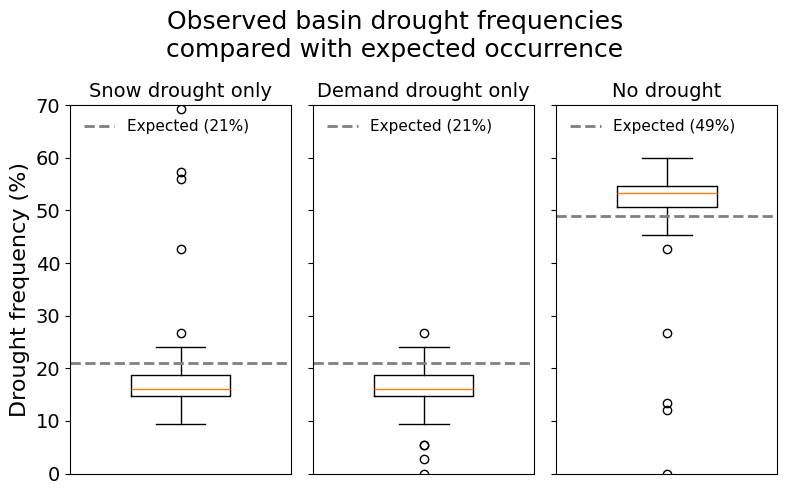

In [60]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(8, 5),
    sharey=True
)

vars_to_plot = [
    ("freq_low_swe_only", "Snow drought only", 21),
    ("freq_high_eto_only", "Demand drought only", 21),
    ("freq_normal", "No drought", 49)
]

for i, (ax, (col, title, expected)) in enumerate(
    zip(axes, vars_to_plot)
):

    vals = (
        freq_df[col]
        .dropna()
        * 100
    )

    ax.boxplot(
        vals,
        widths=0.45
    )

    ax.axhline(
        y=expected,
        color="gray",
        linestyle="--",
        linewidth=2,
        label=f"Expected ({expected}%)"
    )

    ax.set_title(
        title,
        fontsize=14
    )

    ax.set_xticks([])

    if i == 0:
        ax.set_ylabel(
            "Drought frequency (%)",
            fontsize=16
        )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

    ax.legend(
        frameon=False,
        fontsize=11,
        loc="upper left"
    )

# shared y-axis
axes[0].set_ylim(0, 70)

axes[0].set_yticks(
    [0, 10, 20, 30, 40, 50, 60, 70]
)

plt.suptitle(
    "Observed basin drought frequencies\ncompared with expected occurrence",
    fontsize=18
)

plt.tight_layout()

plt.show()

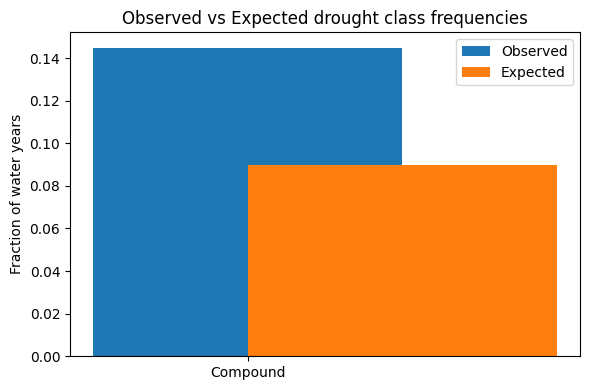

In [61]:
# labels = ["Compound", "Snow only", "Demand only", "Non drought"]
labels = ["Compound"]

# observed = [
#     global_fraction_cd,
#     global_fraction_sd,
#     global_fraction_dd,
#     global_fraction_nd
# ]
observed = [global_fraction_cd]

# expected = [0.09, 0.21, 0.21, 0.49]
expected = [0.09]

x = range(len(labels))

plt.figure(figsize=(6,4))
plt.bar(x, observed, width=0.4, label="Observed", align="center")
plt.bar(x, expected, width=0.4, label="Expected", align="edge")

plt.xticks(x, labels)
plt.ylabel("Fraction of water years")
plt.legend()
plt.title("Observed vs Expected drought class frequencies")

plt.tight_layout()
plt.show()

In [62]:
# Compute p-values for ALL classes

expected = {
    "compound": 0.09,
    "snow": 0.21,
    "demand": 0.21,
    "normal": 0.49
}

pvals = {}

pvals["compound"] = binomtest(
    freq_df["n_compound"].sum(),
    freq_df["n_years"].sum(),
    p=expected["compound"]
).pvalue

pvals["snow"] = binomtest(
    freq_df["n_low_swe_only"].sum(),
    freq_df["n_years"].sum(),
    p=expected["snow"]
).pvalue

pvals["demand"] = binomtest(
    freq_df["n_high_eto_only"].sum(),
    freq_df["n_years"].sum(),
    p=expected["demand"]
).pvalue

pvals["normal"] = binomtest(
    freq_df["n_normal"].sum(),
    freq_df["n_years"].sum(),
    p=expected["normal"]
).pvalue

print(pvals)

{'compound': np.float64(1.6752470108231767e-91), 'snow': np.float64(6.080432959981205e-25), 'demand': np.float64(4.3043060307064927e-44), 'normal': np.float64(2.2155395579872985e-11)}


In [63]:
# Convert p-values → significance stars

def get_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

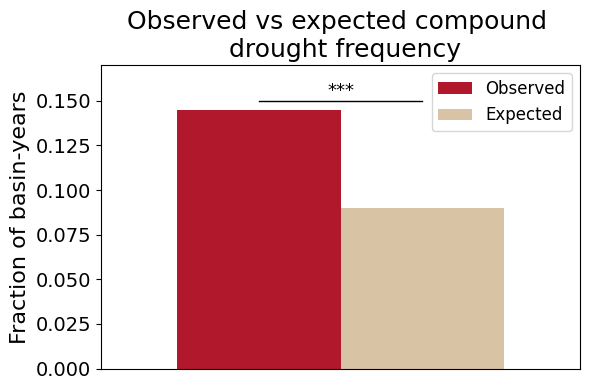

In [64]:
# labels = ["Compound", "Snow only", "Demand only", "Non drought"]
labels = ["Compound"]

# observed = [
#     global_fraction_cd,
#     global_fraction_sd,
#     global_fraction_dd,
#     global_fraction_nd
# ]
observed = [global_fraction_cd]

# expected_vals = [0.09, 0.21, 0.21, 0.49]
expected_vals = [0.09]

stars = [
    get_stars(pvals["compound"]),
    get_stars(pvals["snow"]),
    get_stars(pvals["demand"]),
    get_stars(pvals["normal"])
]

x = range(len(labels))

width = 0.15
x = np.array([0])

obs_color = "#b2182b"
exp_color = "#d8c3a5"

plt.figure(figsize=(6,4))

plt.bar(x - width/2, observed, width=width, label="Observed", color=obs_color)
plt.bar(x + width/2, expected_vals, width=width, label="Expected", color=exp_color)

plt.xlim(-0.22, 0.22)
plt.ylim(0, 0.17)

ax = plt.gca()
ax.set_xticks([])      
ax.set_xticklabels([])  
ax.set_xlabel(None)

ax.tick_params(axis='y', labelsize=14)   # y-tick numbers
plt.ylabel("Fraction of basin-years", fontsize=16)

plt.title("Observed vs expected compound \n drought frequency", fontsize=18)
plt.legend(loc="upper right", frameon=True, fontsize=12)

# bracket + stars
y = max(observed[0], expected_vals[0]) + 0.005
plt.plot([-width/2, width/2], [y, y], color="black", linewidth=1)
plt.text(0, y + 0.003, "***", ha="center", fontsize=13)

plt.tight_layout()
plt.show()

In [65]:
compound.sum("region")
(compound.sum("wy") > 0).sum()

<xarray.DataArray ()> Size: 8B
array(174)

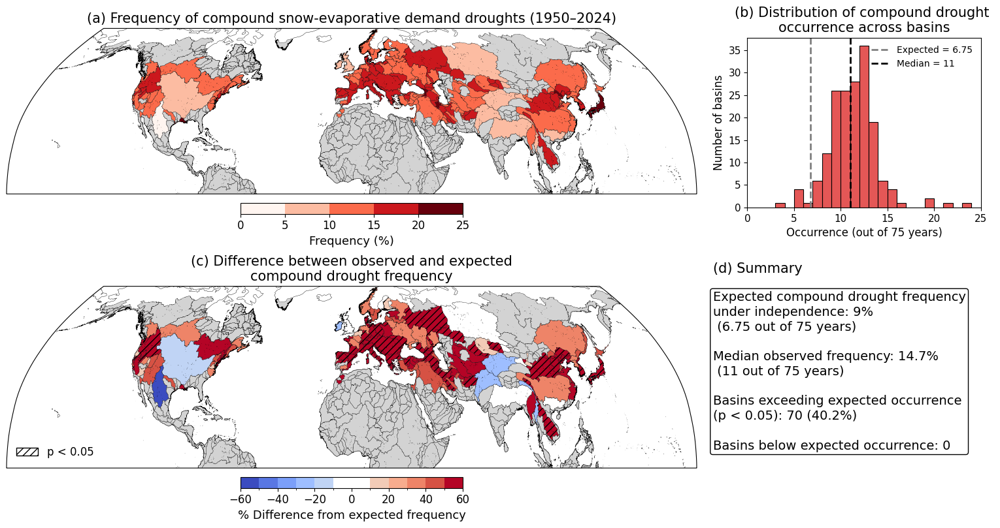

In [66]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import numpy as np

fig = plt.figure(figsize=(16, 10))

# -----------------------------
# Layout
# -----------------------------
ax_a = fig.add_axes([0.03, 0.57, 0.66, 0.34], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.73, 0.57, 0.24, 0.28])

ax_c = fig.add_axes([0.03, 0.15, 0.66, 0.34], projection=ccrs.Robinson())
ax_d = fig.add_axes([0.70, 0.28, 0.27, 0.22])
ax_d.axis("off")

# ============================================================
# (a) Frequency map
# ============================================================
freq_bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])
freq_cmap = "Reds"

freq_norm = colors.BoundaryNorm(
    freq_bounds,
    ncolors=plt.get_cmap(freq_cmap).N,
    clip=True
)

basins_diss.plot(
    column="freq_compound",
    cmap=freq_cmap,
    norm=freq_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color": "lightgray", "label": "No data"},
    ax=ax_a
)

sm_a = cm.ScalarMappable(norm=freq_norm, cmap=freq_cmap)
sm_a.set_array([])

cbar_a = plt.colorbar(
    sm_a,
    ax=ax_a,
    orientation="horizontal",
    pad=0.04,
    fraction=0.05,
    boundaries=freq_bounds,
    ticks=freq_bounds
)

cbar_a.set_ticklabels(["0", "5", "10", "15", "20", "25"])
cbar_a.set_label("Frequency (%)", fontsize=13)
cbar_a.ax.tick_params(labelsize=12)

ax_a.set_title("(a) Frequency of compound snow-evaporative demand droughts (1950–2024)", fontsize=15)
ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)

# ============================================================
# (b) Histogram
# ============================================================
expected = 75 * 0.3 * 0.3
median = good_df["compound"].median()

ax_b.hist(
    good_df["compound"],
    bins=np.arange(good_df["compound"].min(), good_df["compound"].max() + 2),
    color="#E45756",
    edgecolor="black",
    linewidth=0.8
)

ax_b.axvline(
    expected,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected:.2f}"
)

ax_b.axvline(
    median,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median:.0f}"
)

ax_b.set_xlim(0, 25)
ax_b.set_xlabel("Occurrence (out of 75 years)", fontsize=12)
ax_b.set_ylabel("Number of basins", fontsize=12)
ax_b.set_title("(b) Distribution of compound drought \noccurrence across basins", fontsize=15)

ax_b.legend(
    loc="upper right",
    frameon=False,
    fontsize=10,
    handlelength=2
)

ax_b.tick_params(axis="both", labelsize=11)

# ============================================================
# (c) Difference map with hatching
# ============================================================
diff_bounds = np.array([-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60])

base = plt.get_cmap("coolwarm")
cmap_colors = base(np.linspace(0, 1, len(diff_bounds) - 1))

center_idx = list(diff_bounds[:-1]).index(-10)
cmap_colors[center_idx] = [1, 1, 1, 1]

disc_cmap = colors.ListedColormap(cmap_colors)

disc_norm = colors.BoundaryNorm(
    boundaries=diff_bounds,
    ncolors=disc_cmap.N,
    clip=True
)

basins_diss.plot(
    column="compound_pct_diff",
    cmap=disc_cmap,
    norm=disc_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color": "lightgray"},
    ax=ax_c
)

basins_diss[basins_diss["sig_compound"]].plot(
    ax=ax_c,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_c = cm.ScalarMappable(norm=disc_norm, cmap=disc_cmap)
sm_c.set_array([])

cbar_c = plt.colorbar(
    sm_c,
    ax=ax_c,
    orientation="horizontal",
    boundaries=diff_bounds,
    ticks=np.arange(-60, 61, 20),
    pad=0.04,
    fraction=0.05,
    spacing="proportional"
)

cbar_c.set_label("% Difference from expected frequency", fontsize=13)
cbar_c.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_c.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax_c.set_title("(c) Difference between observed and expected\ncompound drought frequency", fontsize=15)
ax_c.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_c.coastlines(linewidth=0.3)

# ============================================================
# (d) Summary box
# ============================================================
summary_text = (
    "Expected compound drought frequency\n"
    "under independence: 9% \n (6.75 out of 75 years)\n\n"
    "Median observed frequency: 14.7%\n (11 out of 75 years)\n\n"
    "Basins exceeding expected occurrence\n"
    "(p < 0.05): 70 (40.2%)\n\n"
    "Basins below expected occurrence: 0"
)

ax_d.text(
    0.02,
    0.98,
    "(d) Summary",
    fontsize=15,
    va="top"
)

ax_d.text(
    0.02,
    0.78,
    summary_text,
    fontsize=14,
    va="top",
    linespacing=1.25,
    bbox=dict(
        boxstyle="round,pad=0.2",
        facecolor="white",
        edgecolor="black",
        linewidth=1
    )
)
pos = ax_b.get_position()

scale = 0.93

new_w = pos.width * scale
new_h = pos.height * scale

new_x = pos.x0 + (pos.width - new_w)/2
new_y = pos.y0 + (pos.height - new_h)/2

ax_b.set_position([
    new_x,
    new_y,
    new_w,
    new_h
])

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

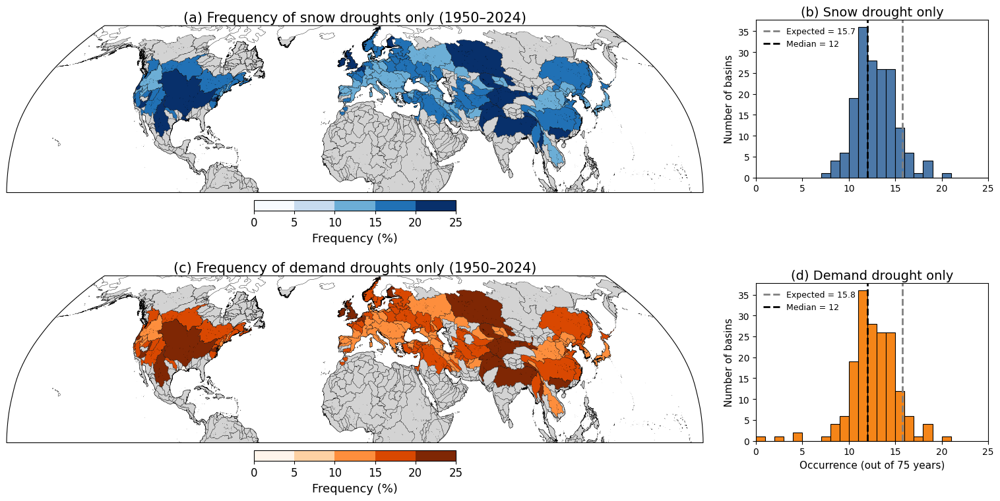

In [67]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import numpy as np

fig = plt.figure(figsize=(16, 10))

# -----------------------------
# Layout
# -----------------------------
ax_a = fig.add_axes([0.03, 0.57, 0.66, 0.34], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.74, 0.62, 0.22, 0.24])

ax_c = fig.add_axes([0.03, 0.19, 0.66, 0.34], projection=ccrs.Robinson())
ax_d = fig.add_axes([0.74, 0.22, 0.22, 0.24])

# -----------------------------
# Shared frequency settings
# -----------------------------
bounds = np.array([0, 0.05, 0.10, 0.15, 0.20, 0.25])

def add_frequency_map(ax, gdf, column, title, cmap):
    norm = colors.BoundaryNorm(
        bounds,
        ncolors=plt.get_cmap(cmap).N,
        clip=True
    )

    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "No data"},
        ax=ax
    )

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        pad=0.035,
        fraction=0.045,
        boundaries=bounds,
        ticks=bounds
    )

    cbar.set_ticklabels(["0", "5", "10", "15", "20", "25"])
    cbar.set_label("Frequency (%)", fontsize=13)
    cbar.ax.tick_params(labelsize=12)

    ax.set_title(title, fontsize=15, pad=4)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

# ============================================================
# (a) Snow drought frequency map
# ============================================================
add_frequency_map(
    ax_a,
    basins_diss,
    column="freq_low_swe_only",
    title="(a) Frequency of snow droughts only (1950–2024)",
    cmap="Blues"
)

# ============================================================
# (b) Snow drought histogram
# ============================================================
expected_snow = 75 * 0.3 * 0.7
median_snow = good_df["low_swe_only"].median()

ax_b.hist(
    good_df["low_swe_only"],
    bins=np.arange(good_df["low_swe_only"].min(), good_df["low_swe_only"].max() + 2),
    color="#4C78A8",
    edgecolor="black",
    linewidth=0.8
)

ax_b.axvline(
    expected_snow,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected_snow:.1f}"
)

ax_b.axvline(
    median_snow,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_snow:.0f}"
)

ax_b.set_xlim(0, 25)
ax_b.set_title("(b) Snow drought only", fontsize=14, pad=4)
ax_b.set_ylabel("Number of basins", fontsize=11)
ax_b.tick_params(axis="both", labelsize=10)
ax_b.legend(loc="upper left", frameon=False, fontsize=9, handlelength=2)

# ============================================================
# (c) Demand drought frequency map
# ============================================================
add_frequency_map(
    ax_c,
    basins_diss,
    column="freq_high_eto_only",
    title="(c) Frequency of demand droughts only (1950–2024)",
    cmap="Oranges"
)

# ============================================================
# (d) Demand drought histogram
# ============================================================
expected_demand = 75 * 0.7 * 0.3
median_demand = good_df["high_eto_only"].median()

ax_d.hist(
    good_df["high_eto_only"],
    bins=np.arange(good_df["high_eto_only"].min(), good_df["high_eto_only"].max() + 2),
    color="#F58518",
    edgecolor="black",
    linewidth=0.8
)

ax_d.axvline(
    expected_demand,
    color="0.5",
    linestyle="--",
    linewidth=2,
    label=f"Expected = {expected_demand:.1f}"
)

ax_d.axvline(
    median_demand,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_demand:.0f}"
)

ax_d.set_xlim(0, 25)
ax_d.set_title("(d) Demand drought only", fontsize=14, pad=4)
ax_d.set_xlabel("Occurrence (out of 75 years)", fontsize=11)
ax_d.set_ylabel("Number of basins", fontsize=11)
ax_d.tick_params(axis="both", labelsize=10)
ax_d.legend(loc="upper left", frameon=False, fontsize=9, handlelength=2)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_S1.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [68]:
expected = {
    "compound": 0.3 * 0.3,        # low SWE AND high ETo = 0.09
    "snow":     0.3 * 0.7,        # low SWE only = 0.21
    "demand":   0.7 * 0.3,        # high ETo only = 0.21
    "normal":   0.7 * 0.7         # neither = 0.49
}

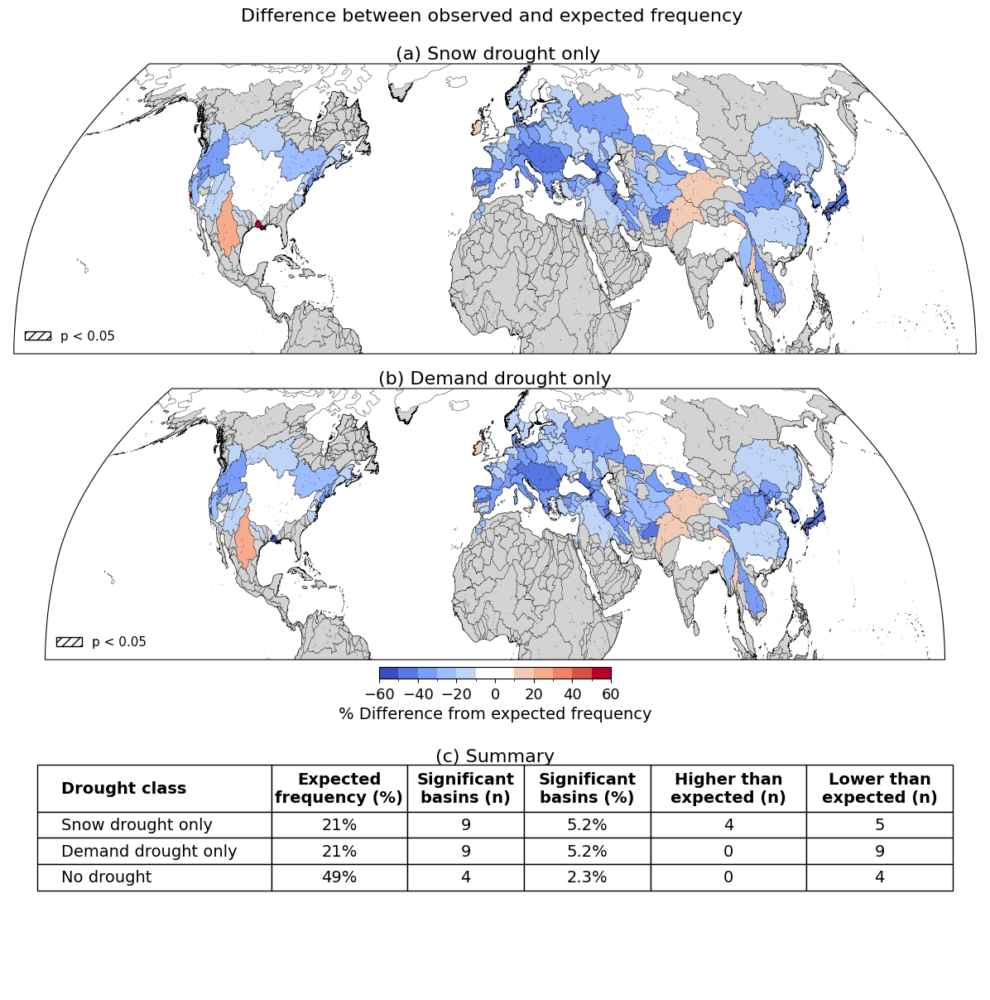

In [69]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import numpy as np
import pandas as pd

fig = plt.figure(figsize=(14, 14))

# -----------------------------
# Layout: 3 rows, 1 column
# -----------------------------
ax_a = fig.add_axes([0.05, 0.68, 0.90, 0.25], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.40, 0.90, 0.25], projection=ccrs.Robinson())
ax_c = fig.add_axes([0.08, 0.13, 0.84, 0.20])
ax_c.axis("off")

# ------------------------------------------------------------
# Discrete coolwarm colormap with white center bin (-10 to 10)
# ------------------------------------------------------------
bounds = np.array([-60, -50, -40, -30, -20, -10, 10, 20, 30, 40, 50, 60])

base = plt.get_cmap("coolwarm")
cmap_colors = base(np.linspace(0, 1, len(bounds) - 1))

center_idx = list(bounds[:-1]).index(-10)
cmap_colors[center_idx] = [1, 1, 1, 1]

disc_cmap = colors.ListedColormap(cmap_colors)
disc_norm = colors.BoundaryNorm(
    boundaries=bounds,
    ncolors=disc_cmap.N,
    clip=True
)

# ------------------------------------------------------------
# Plot function
# ------------------------------------------------------------
def plot_with_hatching(ax, gdf, column, sig_col, title, show_colorbar=True):
    gdf.plot(
        column=column,
        cmap=disc_cmap,
        norm=disc_norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    gdf[gdf[sig_col]].plot(
        ax=ax,
        facecolor="none",
        edgecolor="black",
        hatch="///",
        linewidth=0,
        transform=ccrs.PlateCarree()
    )

    if show_colorbar:
        sm = cm.ScalarMappable(norm=disc_norm, cmap=disc_cmap)
        sm.set_array([])

        cbar = plt.colorbar(
            sm,
            ax=ax,
            orientation="horizontal",
            boundaries=bounds,
            ticks=np.arange(-60, 61, 20),
            pad=0.025,
            fraction=0.04,
            spacing="proportional"
        )

        cbar.set_label("% Difference from expected frequency", fontsize=14)
        cbar.ax.tick_params(labelsize=13)

    hatch_patch = mpatches.Patch(
        facecolor="white",
        edgecolor="black",
        hatch="///",
        label="p < 0.05"
    )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=11
    )

    ax.set_title(title, fontsize=16, pad=4)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

# ------------------------------------------------------------
# (a) Snow drought only
# ------------------------------------------------------------
plot_with_hatching(
    ax_a,
    basins_diss,
    column="snow_drought_pct_diff",
    sig_col="sig_snow",
    title="Difference between observed and expected frequency \n\n (a) Snow drought only",
    show_colorbar=False
)

# ------------------------------------------------------------
# (b) Demand drought only
# ------------------------------------------------------------
plot_with_hatching(
    ax_b,
    basins_diss,
    column="demand_drought_pct_diff",
    sig_col="sig_demand",
    title="(b) Demand drought only",
    show_colorbar=True
)

# ------------------------------------------------------------
# (c) Summary table, excluding compound drought
# ------------------------------------------------------------
table_classes = {
    "Snow drought only": ("sig_snow", "snow_drought_pct_diff", expected["snow"]),
    "Demand drought only": ("sig_demand", "demand_drought_pct_diff", expected["demand"]),
    "No drought": ("sig_normal", "non_drought_pct_diff", expected["normal"])
}

rows = []

for drought_class, (sig_col, diff_col, exp_freq) in table_classes.items():
    sig_mask = basins_diss[sig_col]

    higher = sig_mask & (basins_diss[diff_col] > 0)
    lower = sig_mask & (basins_diss[diff_col] < 0)

    n_sig = int(sig_mask.sum())

    rows.append([
        drought_class,
        f"{exp_freq * 100:.0f}%",
        n_sig,
        f"{100 * n_sig / n_total:.1f}%",
        int(higher.sum()),
        int(lower.sum())
    ])

table_df = pd.DataFrame(
    rows,
    columns=[
        "Drought class",
        "Expected\nfrequency (%)",
        "Significant\nbasins (n)",
        "Significant\nbasins (%)",
        "Higher than\nexpected (n)",
        "Lower than\nexpected (n)"
    ]
)

ax_c.text(
    0.5,
    0.98,
    "(c) Summary",
    fontsize=16,
    ha="center",
    va="bottom"
)

table = ax_c.table(
    cellText=table_df.values,
    colLabels=table_df.columns,
    cellLoc="center",
    colLoc="center",
    loc="upper center",
    colWidths=[0.24, 0.14, 0.12, 0.13, 0.16, 0.15]
)

table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1, 1.9)

# Make header row taller
for col in range(len(table_df.columns)):
    cell = table[(0, col)]
    cell.set_height(cell.get_height() * 1.8)
    
# Left-align first column
for row in range(len(table_df) + 1):
    table[(row, 0)].get_text().set_ha("left")

# Bold header
for col in range(len(table_df.columns)):
    table[(0, col)].get_text().set_fontweight("bold")

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_S2.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [70]:
valid_wy.any("wy")

<xarray.DataArray (region: 602)> Size: 602B
array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True, False, False, False,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False,  True, False,  True, False,  True,  True, False,  True,
        True,  True,  True, False,  True, False, False, False, False,
...
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True, False,
       False,  True,  True,  True,  True, False,  True, False,  True,
        True,  True,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False, False,
       False, False, False, False, False, False,  True,  True, False,
       False, False, False, False,  True,  True, False, False,  True,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True, False, False,
       False, False, False, False,  True,  True,  True,  True,  True,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False])
Coordinates:
  * region   (region) int64 5kB 0 1 2 3 4 5 6 7 ... 595 596 597 598 599 600 601

In [71]:
# Basins with at least one valid GRACE water year
analysis_mask = valid_wy.any("wy")

print("Total regions:", analysis_mask.size)        # 602
print("Selected regions:", int(analysis_mask.sum()))  # should be 174

# Positions of the 174 selected basins
analysis_pos = np.flatnonzero(analysis_mask.values)

# Subset drought-category arrays
compound_174 = compound.isel(region=analysis_pos)
snow_174 = low_swe_only.isel(region=analysis_pos)
demand_174 = high_eto_only.isel(region=analysis_pos)
normal_174 = normal.isel(region=analysis_pos)

print(compound_174.sizes["region"])  # 174

Total regions: 602
Selected regions: 174
174


In [72]:
basins_diss_174 = basins_diss.iloc[analysis_pos].copy()

print(len(basins_diss_174))  # 174

174


In [73]:
selected_ids = basins_diss_174["MAIN_BAS"].to_numpy()

compound_174 = compound_174.assign_coords(region=selected_ids)
snow_174 = snow_174.assign_coords(region=selected_ids)
demand_174 = demand_174.assign_coords(region=selected_ids)
normal_174 = normal_174.assign_coords(region=selected_ids)

In [74]:
print(compound_174.sizes["region"])
print(snow_174.sizes["region"])
print(demand_174.sizes["region"])
print(normal_174.sizes["region"])

174
174
174
174


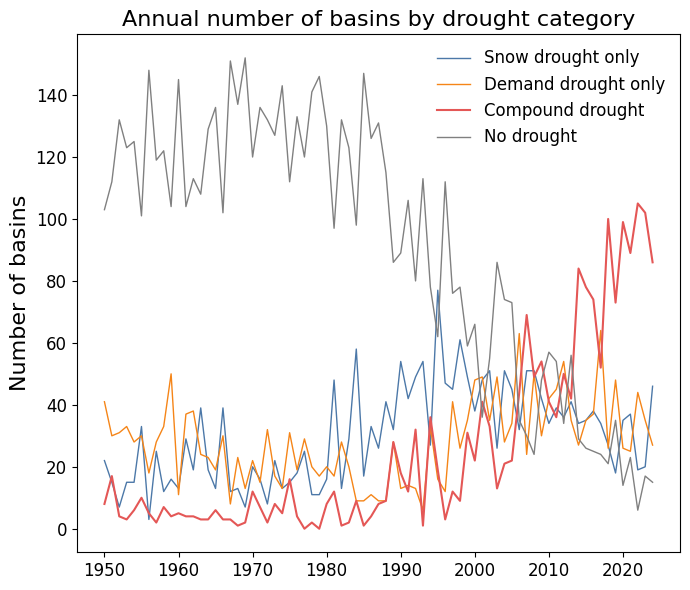

In [75]:
compound_ts  = compound_174.sum("region")
snow_ts      = snow_174.sum("region")
demand_ts    = demand_174.sum("region")
nodrought_ts = normal_174.sum("region")

plt.figure(figsize=(7, 6))

plt.plot(
    compound_174.wy,
    snow_ts,
    color="#4C78A8",
    linewidth=1,
    label="Snow drought only"
)

plt.plot(
    compound_174.wy,
    demand_ts,
    color="#F58518",
    linewidth=1,
    label="Demand drought only"
)

plt.plot(
    compound_174.wy,
    compound_ts,
    color="#E45756",
    linewidth=1.5,
    label="Compound drought"
)

plt.plot(
    compound_174.wy,
    nodrought_ts,
    color="0.5",
    linewidth=1,
    label="No drought"
)

plt.ylabel("Number of basins", fontsize=16)
plt.title("Annual number of basins by drought category", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(
    frameon=False,
    fontsize=12,
    ncol=1
)

plt.tight_layout()
plt.show()

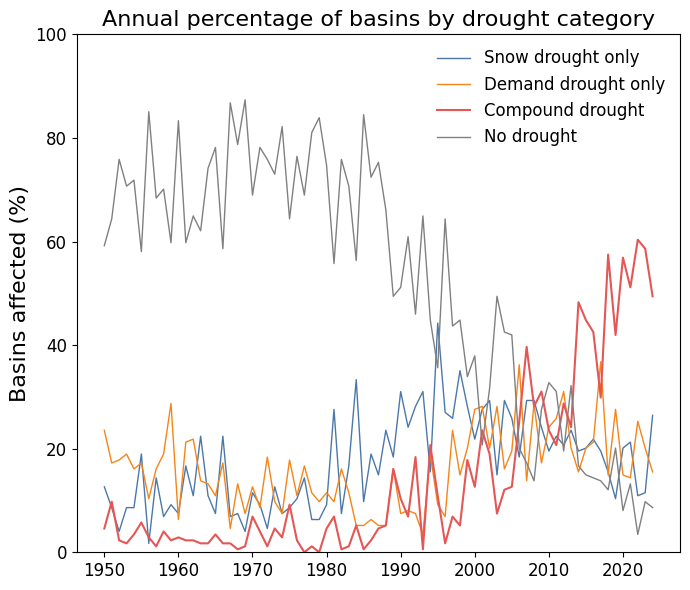

In [76]:
# Number of basins in the 174-basin subset
n_basins = compound_174.sizes["region"]

# Percentage of the 174 basins in each drought category
compound_pct = compound_174.sum("region") / n_basins * 100
snow_pct     = snow_174.sum("region") / n_basins * 100
demand_pct   = demand_174.sum("region") / n_basins * 100
normal_pct   = normal_174.sum("region") / n_basins * 100

plt.figure(figsize=(7, 6))

plt.plot(
    compound_174.wy,
    snow_pct,
    label="Snow drought only",
    color="#4C78A8",
    linewidth=1
)

plt.plot(
    compound_174.wy,
    demand_pct,
    label="Demand drought only",
    color="#F58518",
    linewidth=1
)

plt.plot(
    compound_174.wy,
    compound_pct,
    label="Compound drought",
    color="#E45756",
    linewidth=1.5
)

plt.plot(
    compound_174.wy,
    normal_pct,
    label="No drought",
    color="0.5",
    linewidth=1
)

plt.ylabel("Basins affected (%)", fontsize=16)
plt.title("Annual percentage of basins by drought category", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12,
    ncol=1
)

plt.tight_layout()
plt.show()

In [77]:
WINDOW = 5

rolling_compound = compound_ts.rolling(wy=WINDOW, center=True).mean() #smoothed time series of compound drought frequency
rolling_snow     = snow_ts.rolling(wy=WINDOW, center=True).mean()
rolling_demand   = demand_ts.rolling(wy=WINDOW, center=True).mean()
rolling_normal   = nodrought_ts.rolling(wy=WINDOW, center=True).mean()

# % of basins with compound drought over the surrounding WINDOW years

In [78]:
print(compound_ts.min().values)
print(
    compound.wy[
        compound_ts.argmin()
    ].values
)

print(compound_ts.max().values)
print(
    compound.wy[
        compound_ts.argmax()
    ].values
)

0
1977
105
2022


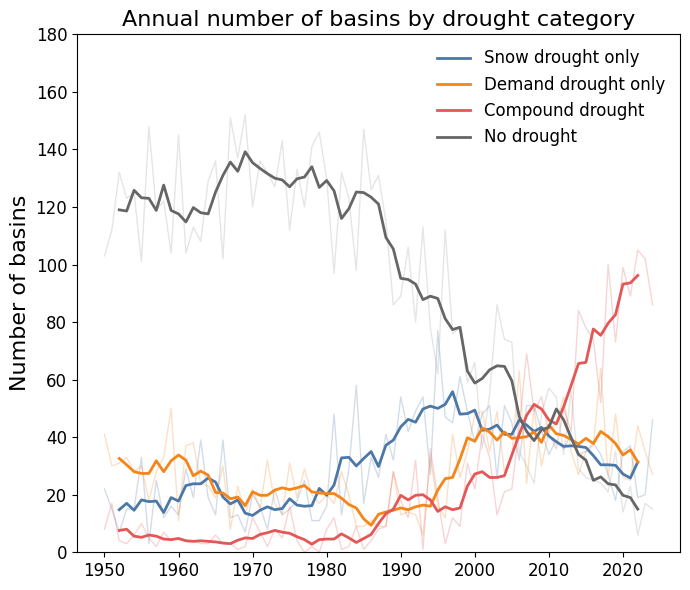

In [79]:
plt.figure(figsize=(7, 6))

# Annual
plt.plot(
    compound_174.wy,
    snow_ts,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    demand_ts,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    compound_ts,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    nodrought_ts,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# Smoothed
plt.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

plt.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Compound drought"
)

plt.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Number of basins", fontsize=16)

plt.title(
    "Annual number of basins by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(0, 180)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [80]:
# Annual series
x = compound_ts.wy.values
y = compound_ts.values

# Sen slope
sen_slope, intercept, lower, upper = theilslopes(
    y,
    x,
    alpha=0.95
)

# Mann-Kendall significance
tau, p = kendalltau(x, y)

# Convert to % of basins per decade
trend_decade = sen_slope * 10 / compound_174.sizes["region"] * 100
lower_decade = lower * 10 / compound_174.sizes["region"] * 100
upper_decade = upper * 10 / compound_174.sizes["region"] * 100

print(
    "Sen slope:",
    round(trend_decade, 2),
    "% of basins per decade"
)

print(
    "95% CI:",
    round(lower_decade, 2),
    "to",
    round(upper_decade, 2),
    "% of basins per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.05" if p < 0.05 else round(p, 4)
)

Sen slope: 4.93 % of basins per decade
95% CI: 3.59 to 6.32 % of basins per decade
Kendall tau: 0.586
p-value: <0.05


In [81]:
WINDOW = 5

rolling_compound = compound_pct.rolling(wy=WINDOW, center=True).mean() #smoothed time series of compound drought frequency
rolling_snow     = snow_pct.rolling(wy=WINDOW, center=True).mean()
rolling_demand   = demand_pct.rolling(wy=WINDOW, center=True).mean()
rolling_normal   = normal_pct.rolling(wy=WINDOW, center=True).mean()

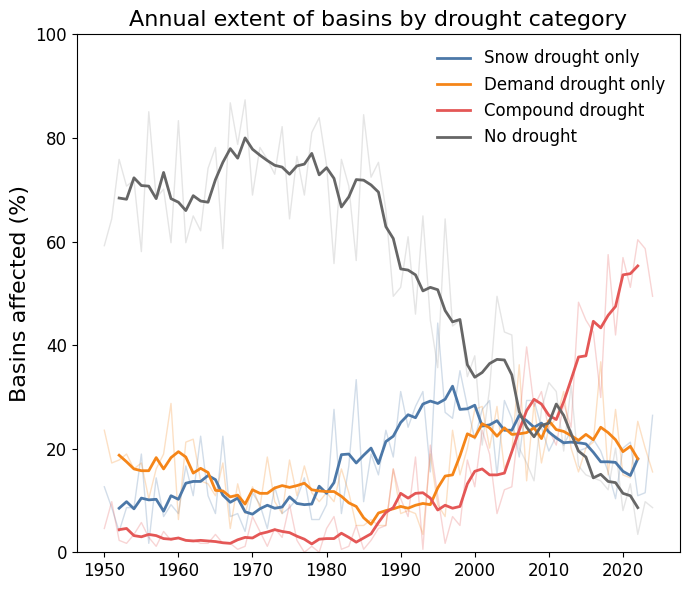

In [82]:
plt.figure(figsize=(7, 6))

# Annual
plt.plot(
    compound_174.wy,
    snow_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    demand_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    compound_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    normal_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# 5-year rolling means
plt.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

plt.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Compound drought"
)

plt.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Basins affected (%)", fontsize=16)

plt.title(
    "Annual extent of basins by drought category",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [83]:
# Annual series
x = compound_pct.wy.values
y = compound_pct.values

# Sen slope
sen_slope, intercept, lower, upper = theilslopes(
    y,
    x,
    alpha=0.95
)

# Mann–Kendall significance (Kendall tau)
tau, p = kendalltau(
    x,
    y
)

# basins per decade
trend_decade = sen_slope * 10

print(
    "Sen slope:",
    round(trend_decade, 2),
    "percentage points per decade"
)

print(
    "95% CI:",
    round(lower * 10, 2),
    "to",
    round(upper * 10, 2),
    "percentage points per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.05" if p < 0.05 else round(p, 4)
)

Sen slope: 4.93 percentage points per decade
95% CI: 3.59 to 6.32 percentage points per decade
Kendall tau: 0.586
p-value: <0.05


In [84]:
# # compute cropland area weight per basin

# # Basin-level cropland area weights

# # ERA5 approximate cell-area weight
# # w_s is proportional to grid-cell area because ERA5 grid is regular lon/lat
# # crop_s is True where cropland exists

# valid_crop = reg_s.notnull() & crop_s

# crop_area_weight = (
#     w_s.where(valid_crop)
#        .groupby(reg_s)
#        .sum(dim=SPATIAL_DIM)
# )

# # Reindex to full basin axis
# crop_area_weight = crop_area_weight.reindex(region=full_region)

In [85]:
# #Do not use
# # cropland-weighted annual extent

# # ------------------------------------------------------------
# # Cropland-area affected by each drought class
# # ------------------------------------------------------------

# compound_crop_area = (compound * crop_area_weight).sum("region")
# snow_crop_area     = (low_swe_only * crop_area_weight).sum("region")
# demand_crop_area   = (high_eto_only * crop_area_weight).sum("region")
# normal_crop_area   = (normal * crop_area_weight).sum("region")

# total_crop_area = crop_area_weight.where(valid_wy.any("wy")).sum("region")

In [86]:
# # percent of cropland area affected

# compound_crop_pct = compound_crop_area / total_crop_area * 100
# snow_crop_pct     = snow_crop_area     / total_crop_area * 100
# demand_crop_pct   = demand_crop_area   / total_crop_area * 100
# normal_crop_pct   = normal_crop_area   / total_crop_area * 100

In [87]:
# WINDOW = 5

# rolling_compound_crop = compound_crop_pct.rolling(wy=WINDOW, center=True).mean()
# rolling_snow_crop     = snow_crop_pct.rolling(wy=WINDOW, center=True).mean()
# rolling_demand_crop   = demand_crop_pct.rolling(wy=WINDOW, center=True).mean()
# rolling_normal_crop   = normal_crop_pct.rolling(wy=WINDOW, center=True).mean()

# plt.figure(figsize=(7, 6))

# # Annual
# plt.plot(
#     compound.wy,
#     snow_crop_pct,
#     color="#4C78A8",
#     alpha=0.25,
#     linewidth=1
# )

# plt.plot(
#     compound.wy,
#     demand_crop_pct,
#     color="#F58518",
#     alpha=0.25,
#     linewidth=1
# )

# plt.plot(
#     compound.wy,
#     compound_crop_pct,
#     color="#E45756",
#     alpha=0.25,
#     linewidth=1
# )

# plt.plot(
#     compound.wy,
#     normal_crop_pct,
#     color="0.6",
#     alpha=0.25,
#     linewidth=1
# )

# # 5-year rolling mean
# plt.plot(
#     rolling_snow_crop.wy,
#     rolling_snow_crop,
#     color="#4C78A8",
#     linewidth=2,
#     label="Snow drought only"
# )

# plt.plot(
#     rolling_demand_crop.wy,
#     rolling_demand_crop,
#     color="#F58518",
#     linewidth=2,
#     label="Demand drought only"
# )

# plt.plot(
#     rolling_compound_crop.wy,
#     rolling_compound_crop,
#     color="#E45756",
#     linewidth=2,
#     label="Compound drought"
# )

# plt.plot(
#     rolling_normal_crop.wy,
#     rolling_normal_crop,
#     color="0.4",
#     linewidth=2,
#     label="No drought"
# )

# plt.ylabel("Cropland area affected (%)", fontsize=16)
# plt.title("Annual cropland area affected by droughts", fontsize=16)

# plt.xticks(fontsize=12)
# plt.yticks(fontsize=12)

# plt.ylim(0, 100)

# plt.legend(
#     frameon=False,
#     fontsize=12
# )

# plt.tight_layout()
# plt.show()

In [88]:
# # Trend for percent cropland area affected

# # Annual series
# x = compound_crop_pct.wy.values
# y = compound_crop_pct.values

# # Remove NaNs if needed
# mask = np.isfinite(x) & np.isfinite(y)

# sen_slope, intercept, lower, upper = theilslopes(
#     y[mask],
#     x[mask],
#     alpha=0.95
# )

# tau, p = kendalltau(
#     x[mask],
#     y[mask]
# )

# trend_decade = sen_slope * 10

# print(
#     "Sen slope:",
#     round(trend_decade, 2),
#     "percentage points of cropland area per decade"
# )

# print(
#     "95% CI:",
#     round(lower * 10, 2),
#     "to",
#     round(upper * 10, 2),
#     "percentage points per decade"
# )

# print(
#     "Kendall tau:",
#     round(tau, 3)
# )

# print(
#     "p-value:",
#     "<0.05" if p < 0.05 else round(p, 4)
# )

In [89]:
# Regrid cropland fraction to ERA5
crop_frac_on_era5 = cropland.interp(
    lat=era5_data["lat"],
    lon=era5_data["lon"],
    method="nearest"
)

# If cropland is percent instead of fraction, uncomment:
crop_frac_on_era5 = crop_frac_on_era5 / 100

crop_frac_on_era5 = crop_frac_on_era5.clip(0, 1).load()

In [90]:
# Compute actual grid-cell area in km²

def gridcell_area_km2(lat, lon):
    """
    Approximate area of regular lat/lon grid cells in km2.
    Works for 1D lat/lon coordinates.
    """
    R = 6371.0  # Earth radius in km

    lat_rad = np.deg2rad(lat.values)
    lon_rad = np.deg2rad(lon.values)

    dlat = np.abs(np.gradient(lat_rad))
    dlon = np.abs(np.gradient(lon_rad))

    area = (
        R**2
        * dlat[:, None]
        * dlon[None, :]
        * np.cos(lat_rad)[:, None]
    )

    return xr.DataArray(
        area,
        dims=("lat", "lon"),
        coords={"lat": lat, "lon": lon},
        name="cell_area_km2"
    )


cell_area_km2 = gridcell_area_km2(
    era5_data["lat"],
    era5_data["lon"]
).load()

In [91]:
# Compute cropland area per ERA5 cell

crop_area_km2 = cell_area_km2 * crop_frac_on_era5
crop_area_km2 = crop_area_km2.load()

# Then stack:
crop_area_s = crop_area_km2.stack({SPATIAL_DIM: ("lat", "lon")}).load()

In [92]:
valid_crop_area = reg_s.notnull() & np.isfinite(crop_area_s)

basin_crop_area_km2 = (
    crop_area_s.where(valid_crop_area)
    .groupby(reg_s)
    .sum(dim=SPATIAL_DIM)
)

basin_crop_area_km2 = basin_crop_area_km2.reindex(region=full_region)

In [93]:
basin_crop_area_174 = basin_crop_area_km2.isel(
    region=analysis_pos
)

# Assign the same basin IDs/order as compound_174
basin_crop_area_174 = basin_crop_area_174.assign_coords(
    region=compound_174.region.values
)

print(basin_crop_area_174.sizes["region"])  # should be 174

assert np.array_equal(
    basin_crop_area_174.region.values,
    compound_174.region.values
)

174


In [94]:
# Annual cropland area affected by each class
compound_crop_area_km2 = (
    compound_174 * basin_crop_area_174
).sum("region")

snow_crop_area_km2 = (
    snow_174 * basin_crop_area_174
).sum("region")

demand_crop_area_km2 = (
    demand_174 * basin_crop_area_174
).sum("region")

normal_crop_area_km2 = (
    normal_174 * basin_crop_area_174
).sum("region")

In [95]:
# Convert to million hectares:

# 1 km2 = 100 ha
compound_crop_area_mha = compound_crop_area_km2 * 100 / 1e6
snow_crop_area_mha     = snow_crop_area_km2 * 100 / 1e6
demand_crop_area_mha   = demand_crop_area_km2 * 100 / 1e6
normal_crop_area_mha   = normal_crop_area_km2 * 100 / 1e6

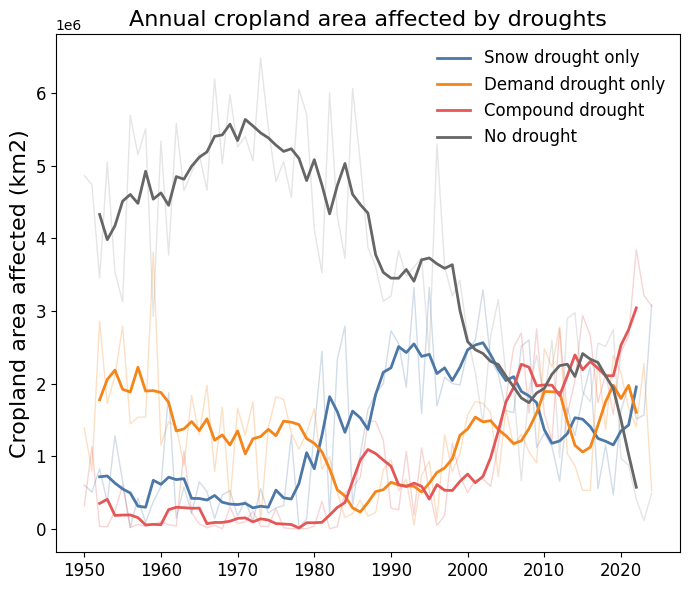

In [96]:
# plot absolute cropland area affected

WINDOW = 5

rolling_compound_area = compound_crop_area_km2.rolling(wy=WINDOW, center=True).mean()
rolling_snow_area     = snow_crop_area_km2.rolling(wy=WINDOW, center=True).mean()
rolling_demand_area   = demand_crop_area_km2.rolling(wy=WINDOW, center=True).mean()
rolling_normal_area   = normal_crop_area_km2.rolling(wy=WINDOW, center=True).mean()

plt.figure(figsize=(7, 6))

# Annual
plt.plot(compound_174.wy, snow_crop_area_km2, color="#4C78A8", alpha=0.25, linewidth=1)
plt.plot(compound_174.wy, demand_crop_area_km2, color="#F58518", alpha=0.25, linewidth=1)
plt.plot(compound_174.wy, compound_crop_area_km2, color="#E45756", alpha=0.25, linewidth=1)
plt.plot(compound_174.wy, normal_crop_area_km2, color="0.6", alpha=0.25, linewidth=1)

# 5-year rolling mean
plt.plot(
    rolling_snow_area.wy,
    rolling_snow_area,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand_area.wy,
    rolling_demand_area,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

plt.plot(
    rolling_compound_area.wy,
    rolling_compound_area,
    color="#E45756",
    linewidth=2,
    label="Compound drought"
)

plt.plot(
    rolling_normal_area.wy,
    rolling_normal_area,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Cropland area affected (km2)", fontsize=16)
plt.title("Annual cropland area affected by droughts", fontsize=16)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.legend(frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

In [97]:
# ------------------------------------------------------------
# Trend in absolute cropland area affected: compound drought
# ------------------------------------------------------------

x = compound_crop_area_km2.wy.values
y = compound_crop_area_km2.values

# remove NaNs
mask = np.isfinite(x) & np.isfinite(y)

sen_slope, intercept, lower, upper = theilslopes(
    y[mask],
    x[mask],
    alpha=0.95
)

tau, p = kendalltau(
    x[mask],
    y[mask]
)

trend_decade = sen_slope * 10

print(
    "Compound drought trend:",
    round(trend_decade, 2),
    "km2 per decade"
)

print(
    "95% CI:",
    round(lower * 10, 2),
    "to",
    round(upper * 10, 2),
    "km2 per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.05" if p < 0.05 else round(p, 4)
)

Compound drought trend: 303340.17 km2 per decade
95% CI: 230025.6 to 390043.44 km2 per decade
Kendall tau: 0.558
p-value: <0.05


In [98]:
def area_trend(da, label):
    x = da.wy.values.astype(float)
    y = da.values.astype(float)

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade_km2 = sen_slope * 10
    trend_decade_mha = trend_decade_km2 / 1e4

    lower_mha = lower * 10 / 1e4
    upper_mha = upper * 10 / 1e4

    print("\n" + label)
    print(
        "Sen slope:",
        round(trend_decade_mha, 2),
        "million ha per decade"
    )
    print(
        "95% CI:",
        round(lower_mha, 2),
        "to",
        round(upper_mha, 2),
        "million ha per decade"
    )
    print("Kendall tau:", round(tau, 3))
    print(
        "p-value:",
        "<0.001" if p < 0.001 else round(p, 4)
    )


area_trend(snow_crop_area_km2, "Snow drought only")
area_trend(demand_crop_area_km2, "Demand drought only")
area_trend(compound_crop_area_km2, "Compound drought")
area_trend(normal_crop_area_km2, "No drought")


Snow drought only
Sen slope: 22.7 million ha per decade
95% CI: 12.76 to 31.52 million ha per decade
Kendall tau: 0.335
p-value: <0.001

Demand drought only
Sen slope: -3.35 million ha per decade
95% CI: -11.46 to 5.03 million ha per decade
Kendall tau: -0.066
p-value: 0.4025

Compound drought
Sen slope: 30.33 million ha per decade
95% CI: 23.0 to 39.0 million ha per decade
Kendall tau: 0.558
p-value: <0.001

No drought
Sen slope: -59.96 million ha per decade
95% CI: -72.02 to -48.79 million ha per decade
Kendall tau: -0.567
p-value: <0.001


In [99]:
# Percent cropland area affected

total_crop_area_km2 = basin_crop_area_174.sum("region")

compound_crop_pct = compound_crop_area_km2 / total_crop_area_km2 * 100
snow_crop_pct     = snow_crop_area_km2     / total_crop_area_km2 * 100
demand_crop_pct   = demand_crop_area_km2   / total_crop_area_km2 * 100
normal_crop_pct   = normal_crop_area_km2   / total_crop_area_km2 * 100

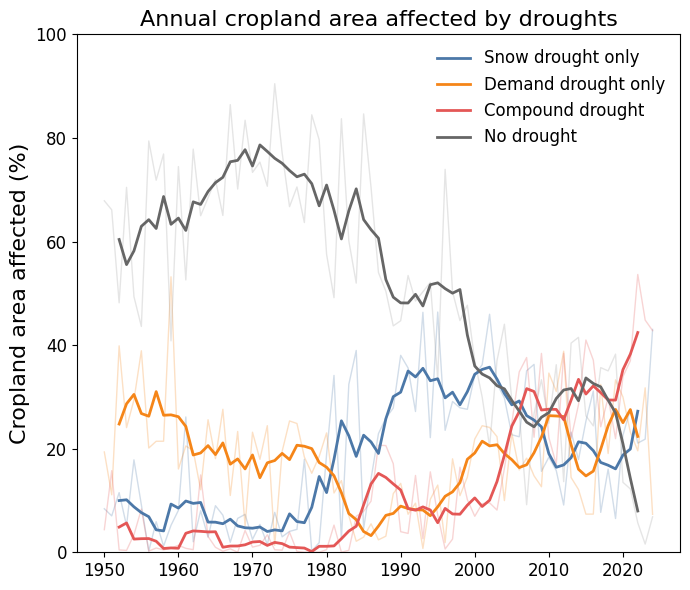

In [100]:
# ------------------------------------------------------------
# Plot percent cropland area affected
# ------------------------------------------------------------

WINDOW = 5

rolling_compound_crop_pct = compound_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_snow_crop_pct     = snow_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_demand_crop_pct   = demand_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_normal_crop_pct   = normal_crop_pct.rolling(wy=WINDOW, center=True).mean()

plt.figure(figsize=(7, 6))

# Annual values
plt.plot(
    compound_174.wy,
    snow_crop_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    demand_crop_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    compound_crop_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

plt.plot(
    compound_174.wy,
    normal_crop_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# 5-year rolling mean
plt.plot(
    rolling_snow_crop_pct.wy,
    rolling_snow_crop_pct,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

plt.plot(
    rolling_demand_crop_pct.wy,
    rolling_demand_crop_pct,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

plt.plot(
    rolling_compound_crop_pct.wy,
    rolling_compound_crop_pct,
    color="#E45756",
    linewidth=2,
    label="Compound drought"
)

plt.plot(
    rolling_normal_crop_pct.wy,
    rolling_normal_crop_pct,
    color="0.4",
    linewidth=2,
    label="No drought"
)

plt.ylabel("Cropland area affected (%)", fontsize=16)

plt.title(
    "Annual cropland area affected by droughts",
    fontsize=16
)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.ylim(0, 100)

plt.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

In [101]:
# ------------------------------------------------------------
# Trend in percent cropland area affected: compound drought
# ------------------------------------------------------------

x = compound_crop_pct.wy.values
y = compound_crop_pct.values

mask = np.isfinite(x) & np.isfinite(y)

sen_slope, intercept, lower, upper = theilslopes(
    y[mask],
    x[mask],
    alpha=0.95
)

tau, p = kendalltau(
    x[mask],
    y[mask]
)

trend_decade = sen_slope * 10

print(
    "Compound drought trend:",
    round(trend_decade, 2),
    "percentage points per decade"
)

print(
    "95% CI:",
    round(lower * 10, 2),
    "to",
    round(upper * 10, 2),
    "percentage points per decade"
)

print(
    "Kendall tau:",
    round(tau, 3)
)

print(
    "p-value:",
    "<0.05" if p < 0.05 else round(p, 4)
)

Compound drought trend: 4.23 percentage points per decade
95% CI: 3.21 to 5.44 percentage points per decade
Kendall tau: 0.558
p-value: <0.05


In [102]:
def pct_area_trend(da, label):
    x = da.wy.values
    y = da.values

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade = sen_slope * 10

    print("\n" + label)
    print("Sen slope:", round(trend_decade, 2), "percentage points per decade")
    print(
        "95% CI:",
        round(lower * 10, 2),
        "to",
        round(upper * 10, 2),
        "percentage points per decade"
    )
    print("Kendall tau:", round(tau, 3))
    print("p-value:", "<0.05" if p < 0.05 else round(p, 4))


pct_area_trend(snow_crop_pct, "Snow drought only")
pct_area_trend(demand_crop_pct, "Demand drought only")
pct_area_trend(compound_crop_pct, "Compound drought")
pct_area_trend(normal_crop_pct, "No drought")


Snow drought only
Sen slope: 3.17 percentage points per decade
95% CI: 1.78 to 4.39 percentage points per decade
Kendall tau: 0.335
p-value: <0.05

Demand drought only
Sen slope: -0.47 percentage points per decade
95% CI: -1.6 to 0.7 percentage points per decade
Kendall tau: -0.066
p-value: 0.4025

Compound drought
Sen slope: 4.23 percentage points per decade
95% CI: 3.21 to 5.44 percentage points per decade
Kendall tau: 0.558
p-value: <0.05

No drought
Sen slope: -8.36 percentage points per decade
95% CI: -10.04 to -6.8 percentage points per decade
Kendall tau: -0.567
p-value: <0.05


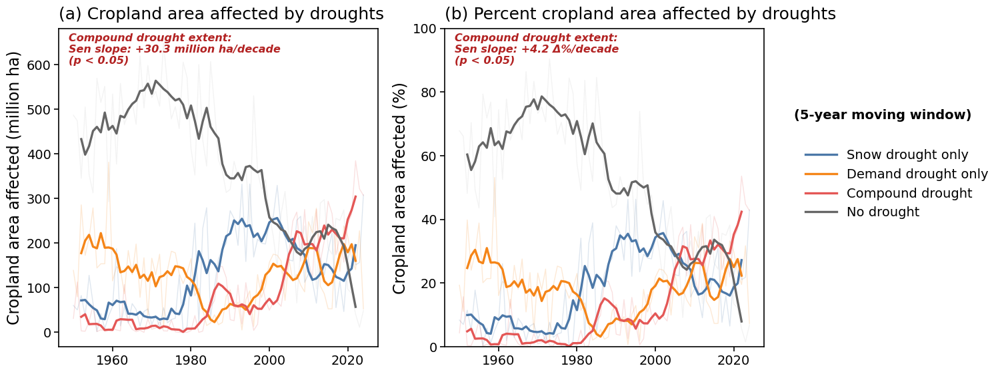

In [103]:
# ------------------------------------------------------------
# Panel plot: cropland area affected + percent cropland area affected
# ------------------------------------------------------------

from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def sen_trend_text(da, unit_label):
    x = da.wy.values
    y = da.values

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade = sen_slope * 10
    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Compound drought extent:\n"
        f"Sen slope: {sign}{trend_decade:.1f} {unit_label}/decade\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ------------------------------------------------------------
# Convert absolute area from km2 to million hectares
# ------------------------------------------------------------

compound_crop_area_mha = compound_crop_area_km2 / 1e4
snow_crop_area_mha     = snow_crop_area_km2 / 1e4
demand_crop_area_mha   = demand_crop_area_km2 / 1e4
normal_crop_area_mha   = normal_crop_area_km2 / 1e4

# ------------------------------------------------------------
# Rolling means
# ------------------------------------------------------------

WINDOW = 5

rolling_compound_area = compound_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_snow_area     = snow_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_demand_area   = demand_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_normal_area   = normal_crop_area_mha.rolling(wy=WINDOW, center=True).mean()

rolling_compound_pct = compound_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_snow_pct     = snow_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_demand_pct   = demand_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_normal_pct   = normal_crop_pct.rolling(wy=WINDOW, center=True).mean()

# ------------------------------------------------------------
# Trend annotations
# ------------------------------------------------------------

area_text, area_trend, area_p = sen_trend_text(compound_crop_area_mha, "million ha")
pct_text, pct_trend, pct_p    = sen_trend_text(compound_crop_pct, "Δ%")

# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.18
annual_lw = 1.0
rolling_lw = 2.4

title_fs = 18
label_fs = 17
tick_fs = 14
legend_fs = 14
annotation_fs = 11.5

# ------------------------------------------------------------
# Figure with separate legend column
# ------------------------------------------------------------

fig = plt.figure(figsize=(17, 7))

gs = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1.35, 1.35, 0.45],   # smaller legend column
    wspace=0.27                         # brings legend closer to panel (b)
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
leg_ax = fig.add_subplot(gs[0, 2])
leg_ax.axis("off")

# square panels
ax1.set_box_aspect(1)
ax2.set_box_aspect(1)

# ============================================================
# Panel (a): Absolute cropland area affected
# ============================================================

# Annual thin lines
ax1.plot(compound_crop_area_mha.wy, snow_crop_area_mha, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_crop_area_mha.wy, demand_crop_area_mha, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_crop_area_mha.wy, compound_crop_area_mha, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_crop_area_mha.wy, normal_crop_area_mha, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax1.plot(rolling_snow_area.wy, rolling_snow_area, color=colors["snow"], linewidth=rolling_lw, label="Snow drought only")
ax1.plot(rolling_demand_area.wy, rolling_demand_area, color=colors["demand"], linewidth=rolling_lw, label="Demand drought only")
ax1.plot(rolling_compound_area.wy, rolling_compound_area, color=colors["compound"], linewidth=rolling_lw, label="Compound drought")
ax1.plot(rolling_normal_area.wy, rolling_normal_area, color=colors["normal"], linewidth=rolling_lw, label="No drought")

ax1.set_title(
    "(a) Cropland area affected by droughts",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax1.set_ylabel(
    "Cropland area affected (million ha)",
    fontsize=label_fs
)

ax1.tick_params(axis="both", labelsize=tick_fs, width=1.2, length=5, colors="black")

# Trend annotation
ax1.text(
    0.03,
    0.985,
    area_text,
    transform=ax1.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)

# ============================================================
# Panel (b): Percent cropland area affected
# ============================================================

# Annual thin lines
ax2.plot(compound_crop_pct.wy, snow_crop_pct, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_pct.wy, demand_crop_pct, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_pct.wy, compound_crop_pct, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_pct.wy, normal_crop_pct, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax2.plot(rolling_snow_pct.wy, rolling_snow_pct, color=colors["snow"], linewidth=rolling_lw)
ax2.plot(rolling_demand_pct.wy, rolling_demand_pct, color=colors["demand"], linewidth=rolling_lw)
ax2.plot(rolling_compound_pct.wy, rolling_compound_pct, color=colors["compound"], linewidth=rolling_lw)
ax2.plot(rolling_normal_pct.wy, rolling_normal_pct, color=colors["normal"], linewidth=rolling_lw)

ax2.set_title(
    "(b) Percent cropland area affected by droughts",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax2.set_ylabel(
    "Cropland area affected (%)",
    fontsize=label_fs
)

ax2.set_ylim(0, 100)
ax2.tick_params(axis="both", labelsize=tick_fs, width=1.2, length=5, colors="black")

# Trend annotation
ax2.text(
    0.03,
    0.985,
    pct_text,
    transform=ax2.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)

# ============================================================
# Shared legend on the right
# ============================================================

legend_handles = [
    Line2D([0], [0], color=colors["snow"], linewidth=rolling_lw, label="Snow drought only"),
    Line2D([0], [0], color=colors["demand"], linewidth=rolling_lw, label="Demand drought only"),
    Line2D([0], [0], color=colors["compound"], linewidth=rolling_lw, label="Compound drought"),
    Line2D([0], [0], color=colors["normal"], linewidth=rolling_lw, label="No drought"),
]

leg_ax.text(
    -0.35,
    0.72,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)

leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(-0.35, 0.64),   # move closer to panel (b)
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)

# ============================================================
# Final formatting: full black outline around panels
# ============================================================

for ax in [ax1, ax2]:
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.2)

plt.savefig(
    "Fig_S4.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [104]:
check_regions = [0, 25, 40]

yrs = compound_174.wy.values

for rr in check_regions:
    y = compound_174[:, rr].astype(int).values

    print("\nRegion:", rr)
    print("Number of compound years:", int(y.sum()))
    print("Years with compound drought:", yrs[y == 1])
    print("Full 0/1 series:")
    print(y)


Region: 0
Number of compound years: 11
Years with compound drought: [2005 2012 2013 2014 2017 2019 2020 2021 2022 2023 2024]
Full 0/1 series:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0 1 0 1 1 1 1 1
 1]

Region: 25
Number of compound years: 8
Years with compound drought: [1957 1990 1995 2004 2015 2016 2022 2023]
Full 0/1 series:
[0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1
 0]

Region: 40
Number of compound years: 14
Years with compound drought: [1989 1992 1994 2008 2009 2014 2015 2016 2018 2019 2020 2022 2023 2024]
Full 0/1 series:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 1 1 1 0 1 1
 1]


In [105]:
# GeoDataFrame aligned with compound_174
analysis_ids = compound_174.region.values

basins_diss_174 = (
    basins_diss[
        basins_diss["MAIN_BAS"].isin(analysis_ids)
    ]
    .set_index("MAIN_BAS")
    .reindex(analysis_ids)
    .reset_index()
)

print(len(basins_diss_174))  # should be 174

assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    compound_174.region.values
)

174


In [106]:
# compound: (wy, region)

slope_per_basin = []
pvals = []

# Extract water years
x = compound_174.wy.values.astype(float)

for r in range(compound_174.shape[1]):

    # Basin compound occurrence time series
    # 1 = compound drought occurred
    # 0 = no compound drought
    y = compound_174[:, r].astype(float).values

    # Only compute trend if occurrence changes through time
    if np.std(y) > 0:

        # Linear trend:
        # occurrence = intercept + slope × year
        slope, intercept, rval, p, stderr = stats.linregress(
            x,
            y
        )

        # Convert:
        # fraction/year
        # → Δ%/decade
        slope_pct_decade = (
            slope * 10 * 100
        )

    else:
        slope_pct_decade = 0.0
        p = 1.0


    # Store basin trend
    slope_per_basin.append(
        slope_pct_decade
    )

    # Store p-value
    pvals.append(
        p
    )

In [107]:
basins_diss_174["compound_trend_pct_decade"] = slope_per_basin
basins_diss_174["p_trend"] = pvals

basins_diss_174["sig_trend"] = (
    basins_diss_174["p_trend"] < 0.05
)

pos_sig = (
    basins_diss_174["sig_trend"] &
    (basins_diss_174["compound_trend_pct_decade"] > 0)
)

neg_sig = (
    basins_diss_174["sig_trend"] &
    (basins_diss_174["compound_trend_pct_decade"] < 0)
)

n_sig = int(basins_diss_174["sig_trend"].sum())
n_pos_sig = int(pos_sig.sum())
n_neg_sig = int(neg_sig.sum())

n_total = len(basins_diss_174)

print("Significant trends:", n_sig)
print("Significantly increasing:", n_pos_sig)
print("Significantly decreasing:", n_neg_sig)
print("% increasing:", round(n_pos_sig / n_total * 100, 1))
print("% decreasing:", round(n_neg_sig / n_total * 100, 1))

Significant trends: 158
Significantly increasing: 158
Significantly decreasing: 0
% increasing: 90.8
% decreasing: 0.0


/tmp/ipykernel_1356544/2983134977.py:56: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sig_mask = basins_diss_plot["sig_trend"].fillna(False).astype(bool)


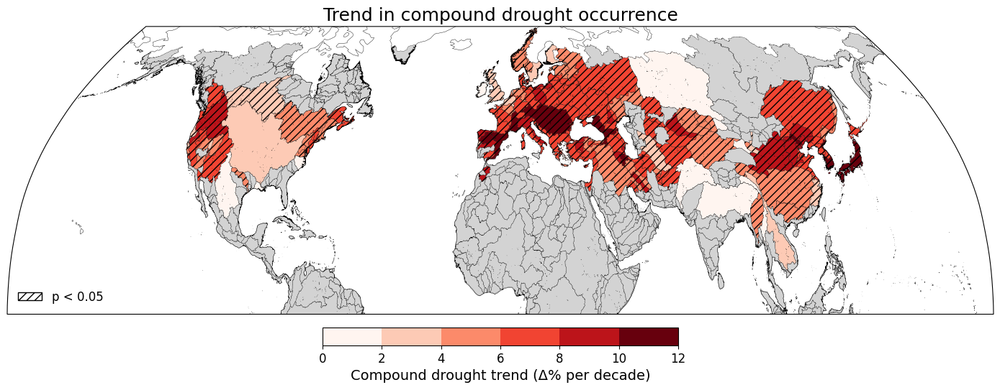

In [108]:
# Keep only basins with trend values; others plot as missing/gray
basins_diss_plot = basins_diss.copy()

# Join the 174-basin trend results
cols = [
    "MAIN_BAS",
    "compound_trend_pct_decade",
    "p_trend",
    "sig_trend"
]

basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)

basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[cols],
    on="MAIN_BAS",
    how="left"
)

# Discrete bins
bins = [0, 2, 4, 6, 8, 10, 12]

cmap = plt.get_cmap("Reds", len(bins) - 1)
norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())

# Base map
basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)

# Hatching only for significant basins
sig_mask = basins_diss_plot["sig_trend"].fillna(False).astype(bool)

basins_diss_plot.loc[sig_mask].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

# Manual colorbar
sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Compound drought trend (Δ% per decade)",
    fontsize=14
)
cbar.ax.tick_params(labelsize=12)

# Hatch legend
hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax.set_title(
    "Trend in compound drought occurrence",
    fontsize=18
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.3)

plt.tight_layout()
plt.show()

In [109]:
def basin_ols_trend(mask_da):
    slope_per_basin = []
    pvals = []

    x = mask_da["wy"].values.astype(float)

    slopes_pct_decade = np.full(mask_da.sizes["region"], np.nan)
    pvals = np.full(mask_da.sizes["region"], np.nan)

    for r in range(mask_da.sizes["region"]):
        y = mask_da.isel(region=r).values.astype(float)

        valid = np.isfinite(x) & np.isfinite(y)

        if valid.sum() < 2:
            continue

        x_valid = x[valid]
        y_valid = y[valid]

        if np.std(y_valid) == 0:
            # Valid constant series: no change through time
            slopes_pct_decade[r] = 0.0
            pvals[r] = 1.0
        else:
            result = stats.linregress(x_valid, y_valid)

            # Fraction per year → percentage points per decade
            slopes_pct_decade[r] = result.slope * 10 * 100
            pvals[r] = result.pvalue

    return slopes_pct_decade, pvals

In [110]:
compound_slope, compound_p = basin_ols_trend(compound_174)
snow_slope, snow_p         = basin_ols_trend(snow_174)
demand_slope, demand_p     = basin_ols_trend(demand_174)
normal_slope, normal_p     = basin_ols_trend(normal_174)

In [111]:
basins_diss_174["compound_trend"] = compound_slope
basins_diss_174["compound_p"] = compound_p

basins_diss_174["snow_trend"] = snow_slope
basins_diss_174["snow_p"] = snow_p

basins_diss_174["demand_trend"] = demand_slope
basins_diss_174["demand_p"] = demand_p

basins_diss_174["normal_trend"] = normal_slope
basins_diss_174["normal_p"] = normal_p

In [112]:
n_total = len(basins_diss_174)

for label, trend_col, p_col in [
    ("Compound", "compound_trend", "compound_p"),
    ("Snow only", "snow_trend", "snow_p"),
    ("Demand only", "demand_trend", "demand_p"),
    ("No drought", "normal_trend", "normal_p")
]:

    valid = (
        basins_diss_174[trend_col].notna() &
        basins_diss_174[p_col].notna()
    )

    sig = valid & (basins_diss_174[p_col] < 0.05)

    pos = sig & (basins_diss_174[trend_col] > 0)
    neg = sig & (basins_diss_174[trend_col] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_sig = 100 * n_sig / n_valid
    pct_pos = 100 * n_pos / n_valid
    pct_neg = 100 * n_neg / n_valid

    print(f"\n{label}")
    print("Valid basins:", n_valid)
    print(f"Significant: {n_sig} ({pct_sig:.1f}%)")
    print(f"Increasing: {n_pos} ({pct_pos:.1f}%)")
    print(f"Decreasing: {n_neg} ({pct_neg:.1f}%)")


Compound
Valid basins: 174
Significant: 158 (90.8%)
Increasing: 158 (90.8%)
Decreasing: 0 (0.0%)

Snow only
Valid basins: 174
Significant: 48 (27.6%)
Increasing: 48 (27.6%)
Decreasing: 0 (0.0%)

Demand only
Valid basins: 174
Significant: 30 (17.2%)
Increasing: 23 (13.2%)
Decreasing: 7 (4.0%)

No drought
Valid basins: 174
Significant: 154 (88.5%)
Increasing: 0 (0.0%)
Decreasing: 154 (88.5%)


In [113]:
print("Regions in compound (full):", compound.sizes["region"])
print("Regions in compound_174:", compound_174.sizes["region"])

print("Rows in basins_diss (full):", len(basins_diss))
print("Rows in basins_diss_174:", len(basins_diss_174))

Regions in compound (full): 602
Regions in compound_174: 174
Rows in basins_diss (full): 602
Rows in basins_diss_174: 174


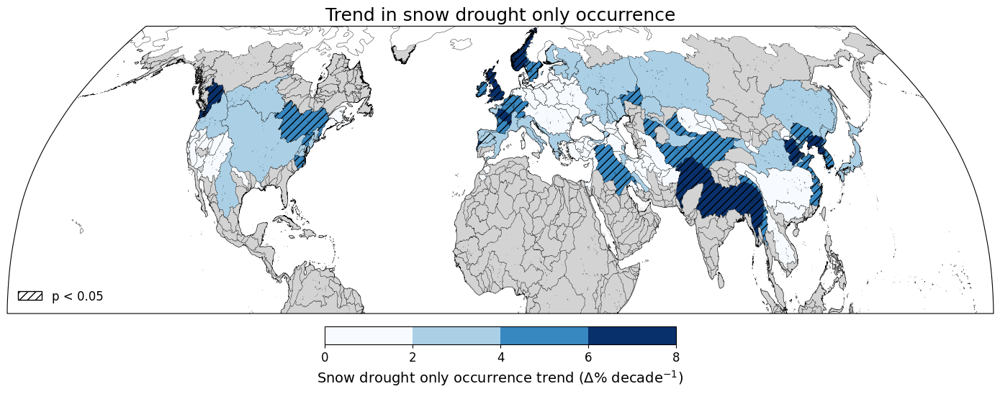

In [114]:
# Keep all basins; missing/NaN trends will plot as gray
basins_diss_plot = basins_diss.copy()

# Remove any old trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=["snow_trend", "snow_p"],
    errors="ignore"
)

# Join the correctly aligned 174-basin results
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        ["MAIN_BAS", "snow_trend", "snow_p"]
    ],
    on="MAIN_BAS",
    how="left"
)

# Discrete bins
bins = [0, 2, 4, 6, 8]

cmap = plt.get_cmap("Blues", len(bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())

# Base map
basins_diss_plot.plot(
    column="snow_trend",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)

# Hatching for significant snow drought trends only
basins_diss_plot[
    basins_diss_plot["snow_p"] < 0.05
].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

# Manual colorbar
sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Snow drought only occurrence trend (Δ% decade$^{-1}$)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)

# Hatch legend
hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax.set_title(
    "Trend in snow drought only occurrence",
    fontsize=18
)

ax.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax.coastlines(
    linewidth=0.3
)

plt.tight_layout()
plt.show()

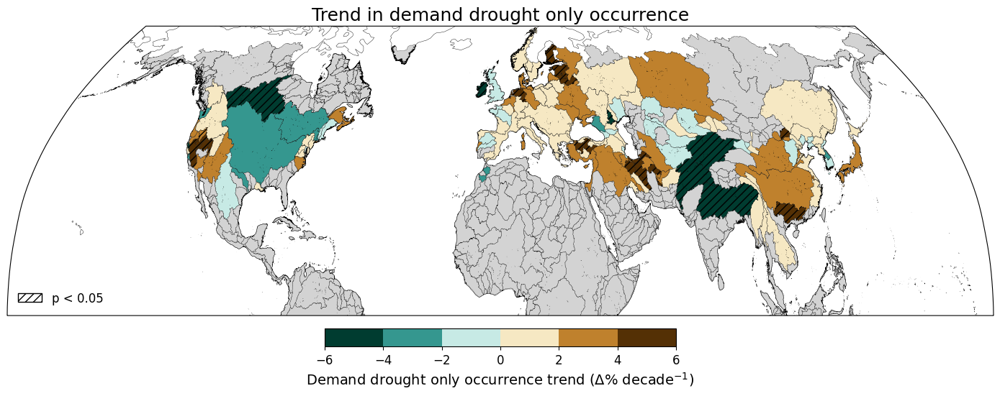

In [115]:
# Keep all basins; missing/NaN trends will plot as gray
basins_diss_plot = basins_diss.copy()

# Remove any old or misaligned demand-trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=["demand_trend", "demand_p"],
    errors="ignore"
)

# Join the correctly aligned 174-basin results
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        ["MAIN_BAS", "demand_trend", "demand_p"]
    ],
    on="MAIN_BAS",
    how="left"
)

# Discrete bins
bins = [-6, -4, -2, 0, 2, 4, 6]

cmap = plt.get_cmap("BrBG_r", len(bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())

# Base map
basins_diss_plot.plot(
    column="demand_trend",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax
)

# Hatching for significant demand drought trends only
basins_diss_plot[
    basins_diss_plot["demand_p"] < 0.05
    ].plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

# Manual colorbar
sm = cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Demand drought only occurrence trend (Δ% decade$^{-1}$)",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=12
)

# Hatch legend
hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax.set_title(
    "Trend in demand drought only occurrence",
    fontsize=18
)

ax.set_extent(
    [-180, 180, 0, 70],
    crs=ccrs.PlateCarree()
)

ax.coastlines(
    linewidth=0.3
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1356544/124606254.py:95: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


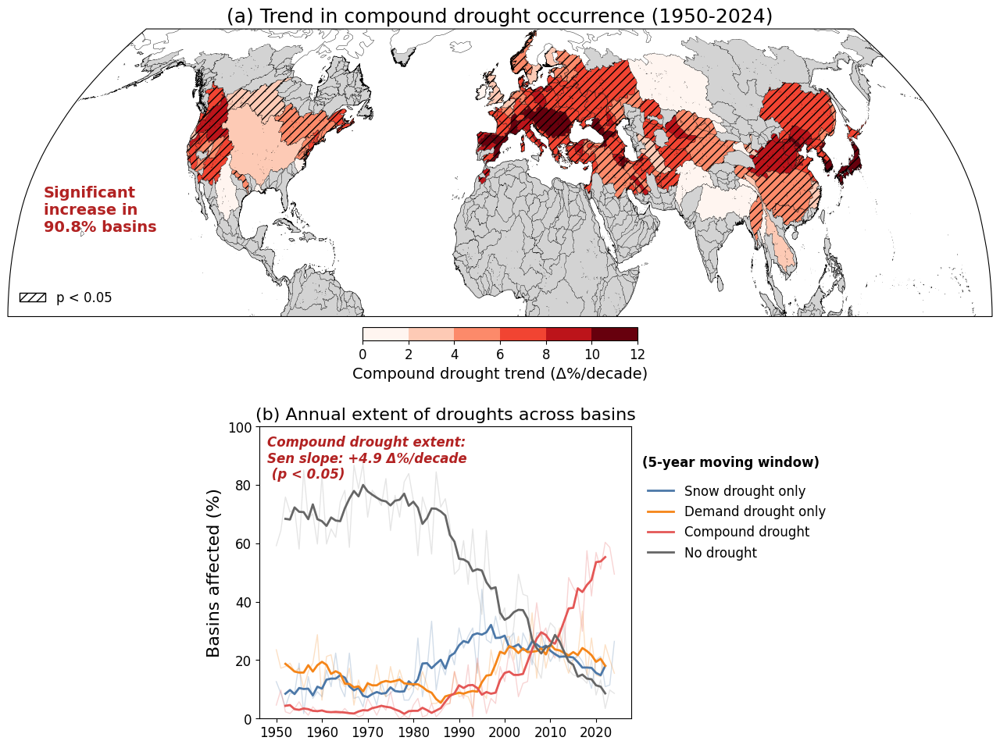

In [116]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs

# ============================================================
# (a) Trend map
# ============================================================
# ============================================================
# Prepare full 602-basin map with 174-basin trend results
# ============================================================

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)

# Add correctly aligned results from the 174 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        [
            "MAIN_BAS",
            "compound_trend_pct_decade",
            "p_trend",
            "sig_trend"
        ]
    ],
    on="MAIN_BAS",
    how="left"
)

# Significant increasing basins among the 174-basin subset
valid_trend = (
    basins_diss_174["compound_trend_pct_decade"].notna() &
    basins_diss_174["p_trend"].notna()
)

sig_increase = (
    valid_trend &
    (basins_diss_174["p_trend"] < 0.05) &
    (basins_diss_174["compound_trend_pct_decade"] > 0)
)

n_valid = int(valid_trend.sum())
n_sig_increase = int(sig_increase.sum())

pct_sig_increase = (
    100 * n_sig_increase / n_valid
    if n_valid > 0 else float("nan")
)

# -----------------------------
# Layout
# -----------------------------
fig = plt.figure(figsize=(14, 11))

ax_a = fig.add_axes([0.05, 0.52, 0.90, 0.40], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.28, 0.08, 0.34, 0.34])


bins = [0, 2, 4, 6, 8, 10, 12]

cmap = plt.get_cmap("Reds", len(bins) - 1)
norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_a
)

# Hatching only for significant basins
sig_mask = (
    basins_diss_plot["sig_trend"]
    .fillna(False)
    .astype(bool)
)

basins_diss_plot.loc[sig_mask].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax_a,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar.set_label(
    "Compound drought trend (Δ%/decade)",
    fontsize=14
)
cbar.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax_a.text(
    -170,
    20,
    f"Significant\nincrease in\n{pct_sig_increase:.1f}% basins",
    color="#B22222",
    fontsize=14,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_a.set_title(
    "(a) Trend in compound drought occurrence (1950-2024)",
    fontsize=18
)

ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)

# ============================================================
# (b) Annual extent line plot
# ============================================================
# Annual
ax_b.plot(
    compound_174.wy,
    snow_pct,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

ax_b.plot(
    compound_174.wy,
    demand_pct,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

ax_b.plot(
    compound_174.wy,
    compound_pct,
    color="#E45756",
    alpha=0.25,
    linewidth=1
)

ax_b.plot(
    compound_174.wy,
    normal_pct,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# Smoothed
ax_b.plot(
    rolling_snow.wy,
    rolling_snow,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

ax_b.plot(
    rolling_demand.wy,
    rolling_demand,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

ax_b.plot(
    rolling_compound.wy,
    rolling_compound,
    color="#E45756",
    linewidth=2,
    label="Compound drought"
)

ax_b.plot(
    rolling_normal.wy,
    rolling_normal,
    color="0.4",
    linewidth=2,
    label="No drought"
)

ax_b.set_ylabel(
    "Basins affected (%)",
    fontsize=16
)

ax_b.set_title(
    "(b) Annual extent of droughts across basins",
    fontsize=16
)

ax_b.tick_params(axis="both", labelsize=12)
ax_b.set_ylim(0, 100)

ax_b.text(
    1948,
    97,
    "Compound drought extent:\n"
    "Sen slope: +4.9 Δ%/decade \n (p < 0.05)",
    color="#B22222",
    fontsize=12,
    fontweight="bold",
    fontstyle="italic",
    va="top"
)

ax_b.text(
    1.03,
    0.90,
    "(5-year moving window)",
    transform=ax_b.transAxes,
    fontsize=12,
    fontweight="bold",
    va="top",
    ha="left"
)

ax_b.legend(
    frameon=False,
    fontsize=12,
    loc="upper left",
    bbox_to_anchor=(1.03, 0.82),
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_2.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

/tmp/ipykernel_1356544/4270470176.py:183: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


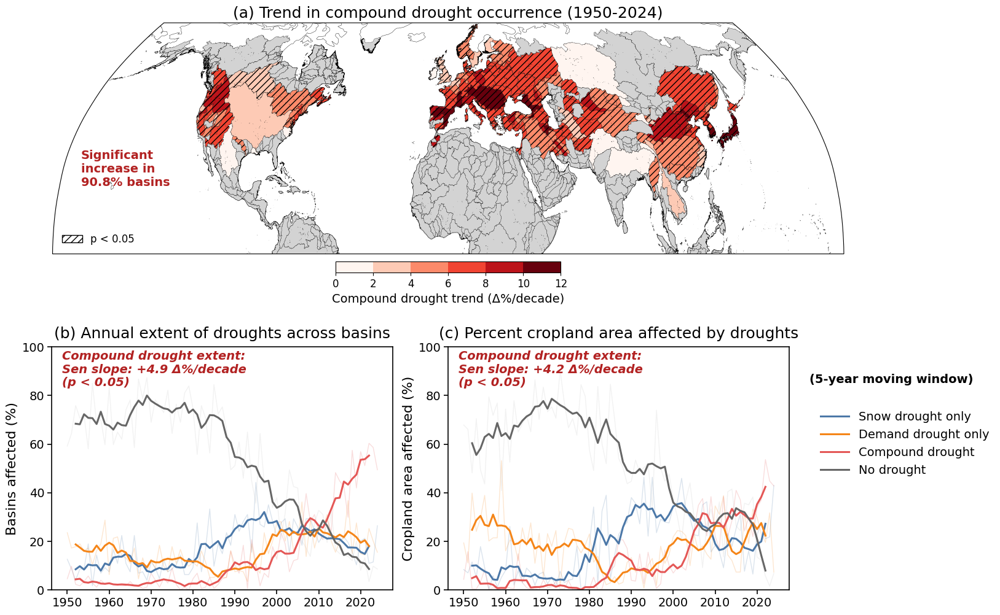

In [117]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
from scipy.stats import theilslopes, kendalltau

# ============================================================
# Helper function for Sen trend annotation
# ============================================================

def sen_trend_text(da, unit_label):
    x = da.wy.values.astype(float)
    y = da.values.astype(float)

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade = sen_slope * 10
    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Compound drought extent:\n"
        f"Sen slope: {sign}{trend_decade:.1f} {unit_label}/decade\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ============================================================
# Cropland percent rolling means
# ============================================================

WINDOW = 5

rolling_compound_crop_pct = compound_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_snow_crop_pct     = snow_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_demand_crop_pct   = demand_crop_pct.rolling(wy=WINDOW, center=True).mean()
rolling_normal_crop_pct   = normal_crop_pct.rolling(wy=WINDOW, center=True).mean()

pct_text, pct_trend, pct_p = sen_trend_text(
    compound_crop_pct,
    "Δ%"
)

# ============================================================
# Prepare full 602-basin map with aligned 174-basin trends
# ============================================================

basins_diss_plot = basins_diss.copy()

# Remove any old or misaligned trend columns
basins_diss_plot = basins_diss_plot.drop(
    columns=[
        "compound_trend_pct_decade",
        "p_trend",
        "sig_trend"
    ],
    errors="ignore"
)

# Join trend results from the 174-basin subset
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        [
            "MAIN_BAS",
            "compound_trend_pct_decade",
            "p_trend",
            "sig_trend"
        ]
    ],
    on="MAIN_BAS",
    how="left"
)

# Significant increasing basins among valid analysis basins
valid_map_trend = (
    basins_diss_174["compound_trend_pct_decade"].notna()
    & basins_diss_174["p_trend"].notna()
)

sig_increase = (
    valid_map_trend
    & (basins_diss_174["p_trend"] < 0.05)
    & (basins_diss_174["compound_trend_pct_decade"] > 0)
)

n_valid = int(valid_map_trend.sum())
n_sig_increase = int(sig_increase.sum())

pct_sig_increase = (
    100 * n_sig_increase / n_valid
    if n_valid > 0
    else np.nan
)

# ============================================================
# Plot settings
# ============================================================

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.20
annual_lw = 1.0
rolling_lw = 2.2

title_fs = 18
label_fs = 16
tick_fs = 14
legend_fs = 14
annotation_fs = 14


# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(figsize=(15, 11))

# Top map
ax_a = fig.add_axes([0.04, 0.55, 0.92, 0.37], projection=ccrs.Robinson())
# Bottom panels
ax_b = fig.add_axes([0.07, 0.08, 0.37, 0.36])
ax_c = fig.add_axes([0.50, 0.08, 0.37, 0.36])

# Shared legend axis
leg_ax = fig.add_axes([0.88, 0.18, 0.12, 0.22])
leg_ax.axis("off")

# ============================================================
# (a) Trend map
# ============================================================

bins = [0, 2, 4, 6, 8, 10, 12]

cmap = plt.get_cmap("Reds", len(bins) - 1)
norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="compound_trend_pct_decade",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_a
)

# Hatching for significant trends
sig_mask = (
    basins_diss_plot["sig_trend"]
    .fillna(False)
    .astype(bool)
)

basins_diss_plot.loc[sig_mask].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax_a,
    orientation="horizontal",
    boundaries=bins,
    ticks=bins,
    pad=0.03,
    fraction=0.045,
    spacing="proportional"
)

cbar.set_label(
    "Compound drought trend (Δ%/decade)",
    fontsize=14
)
cbar.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax_a.text(
    -170,
    20,
    f"Significant\nincrease in\n"
    f"{pct_sig_increase:.1f}% basins",
    color="#B22222",
    fontsize=14,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_a.set_title(
    "(a) Trend in compound drought occurrence (1950-2024)",
    fontsize=18,
    loc="center"
)

ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)


# ============================================================
# (b) Annual extent across basins
# ============================================================

# Annual thin lines
ax_b.plot(compound_174.wy, snow_pct, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax_b.plot(compound_174.wy, demand_pct, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax_b.plot(compound_174.wy, compound_pct, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax_b.plot(compound_174.wy, normal_pct, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax_b.plot(rolling_snow.wy, rolling_snow, color=colors["snow"], linewidth=rolling_lw)
ax_b.plot(rolling_demand.wy, rolling_demand, color=colors["demand"], linewidth=rolling_lw)
ax_b.plot(rolling_compound.wy, rolling_compound, color=colors["compound"], linewidth=rolling_lw)
ax_b.plot(rolling_normal.wy, rolling_normal, color=colors["normal"], linewidth=rolling_lw)

ax_b.set_title(
    "(b) Annual extent of droughts across basins",
    fontsize=title_fs,
    loc="center",
    pad=10
)

ax_b.set_ylabel(
    "Basins affected (%)",
    fontsize=label_fs
)

ax_b.set_ylim(0, 100)

ax_b.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

ax_b.text(
    0.03,
    0.985,
    "Compound drought extent:\n"
    "Sen slope: +4.9 Δ%/decade\n"
    "(p < 0.05)",
    transform=ax_b.transAxes,
    color="#B22222",
    fontsize=annotation_fs,
    fontweight="bold",
    fontstyle="italic",
    ha="left",
    va="top",
    linespacing=1.15
)


# ============================================================
# (c) Percent cropland area affected
# ============================================================

# Annual thin lines
ax_c.plot(compound_crop_pct.wy, snow_crop_pct, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax_c.plot(compound_crop_pct.wy, demand_crop_pct, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax_c.plot(compound_crop_pct.wy, compound_crop_pct, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax_c.plot(compound_crop_pct.wy, normal_crop_pct, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax_c.plot(rolling_snow_crop_pct.wy, rolling_snow_crop_pct, color=colors["snow"], linewidth=rolling_lw)
ax_c.plot(rolling_demand_crop_pct.wy, rolling_demand_crop_pct, color=colors["demand"], linewidth=rolling_lw)
ax_c.plot(rolling_compound_crop_pct.wy, rolling_compound_crop_pct, color=colors["compound"], linewidth=rolling_lw)
ax_c.plot(rolling_normal_crop_pct.wy, rolling_normal_crop_pct, color=colors["normal"], linewidth=rolling_lw)

ax_c.set_title(
    "(c) Percent cropland area affected by droughts",
    fontsize=title_fs,
    loc="center",
    pad=10
)

ax_c.set_ylabel(
    "Cropland area affected (%)",
    fontsize=label_fs
)

ax_c.set_ylim(0, 100)

ax_c.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

ax_c.text(
    0.03,
    0.985,
    pct_text,
    transform=ax_c.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Shared legend for panels (b) and (c)
# ============================================================

legend_handles = [
    Line2D([0], [0], color=colors["snow"], linewidth=rolling_lw, label="Snow drought only"),
    Line2D([0], [0], color=colors["demand"], linewidth=rolling_lw, label="Demand drought only"),
    Line2D([0], [0], color=colors["compound"], linewidth=rolling_lw, label="Compound drought"),
    Line2D([0], [0], color=colors["normal"], linewidth=rolling_lw, label="No drought"),
]

leg_ax.text(
    0.10,
    1.00,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)

leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(0.10, 0.82),
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)


# ============================================================
# Final formatting
# ============================================================

for ax in [ax_b, ax_c]:
    # ax.set_box_aspect(1)

    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.2)

plt.savefig(
    "Fig_2.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.show()

In [118]:
WINDOW = 5

compound_ts  = compound_174.sum("region")
snow_ts      = snow_174.sum("region")
demand_ts    = demand_174.sum("region")
nodrought_ts = normal_174.sum("region")

rolling_compound_n = compound_ts.rolling(wy=WINDOW, center=True).mean()
rolling_snow_n = snow_ts.rolling(wy=WINDOW, center=True).mean()
rolling_demand_n = demand_ts.rolling(wy=WINDOW, center=True).mean()
rolling_normal_n = nodrought_ts.rolling(wy=WINDOW, center=True).mean()

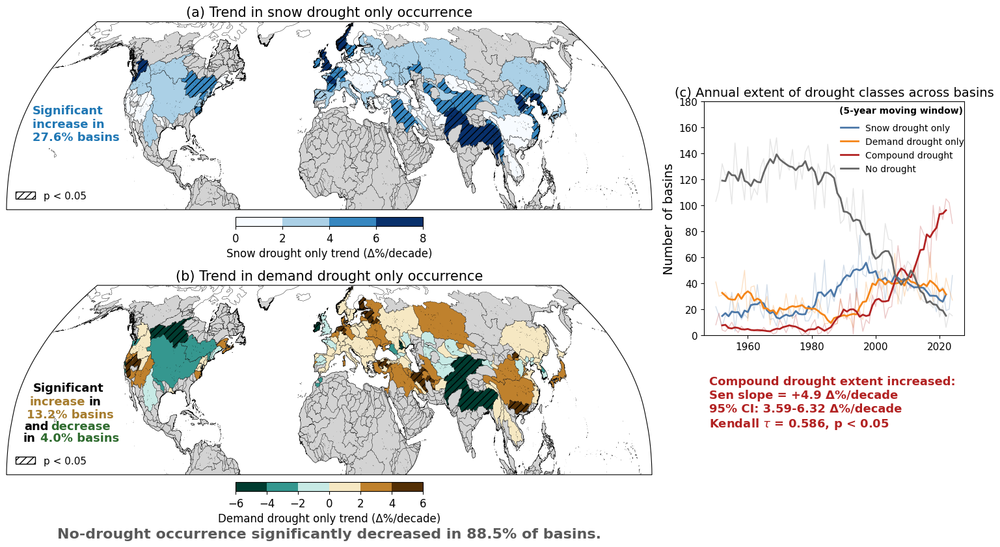

In [119]:
basins_diss_plot = basins_diss.copy()

trend_cols = [
    "snow_trend",
    "snow_p",
    "demand_trend",
    "demand_p",
    "normal_trend",
    "normal_p"
]

basins_diss_plot = basins_diss_plot.drop(
    columns=trend_cols,
    errors="ignore"
)

basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        ["MAIN_BAS"] + trend_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ============================================================
# Calculate significant-trend percentages dynamically
# ============================================================

def significant_stats(gdf, trend_col, p_col):
    valid = gdf[trend_col].notna() & gdf[p_col].notna()
    sig = valid & (gdf[p_col] < 0.05)

    pos = sig & (gdf[trend_col] > 0)
    neg = sig & (gdf[trend_col] < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = 100 * n_pos / n_valid if n_valid > 0 else np.nan
    pct_neg = 100 * n_neg / n_valid if n_valid > 0 else np.nan

    return pct_pos, pct_neg


snow_pct_pos, snow_pct_neg = significant_stats(
    basins_diss_174,
    "snow_trend",
    "snow_p"
)

demand_pct_pos, demand_pct_neg = significant_stats(
    basins_diss_174,
    "demand_trend",
    "demand_p"
)

normal_pct_pos, normal_pct_neg = significant_stats(
    basins_diss_174,
    "normal_trend",
    "normal_p"
)

# ============================================================
# Figure layout
# ============================================================

fig = plt.figure(figsize=(16, 12))

# -----------------------------
# Layout
# -----------------------------
ax_a = fig.add_axes([0.05, 0.62, 0.62, 0.30], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.28, 0.62, 0.30], projection=ccrs.Robinson())
ax_c = fig.add_axes([0.72, 0.48, 0.25, 0.30])

# ============================================================
# (a) Snow drought only trend map
# ============================================================

snow_bins = [0, 2, 4, 6, 8]
snow_cmap = plt.get_cmap("Blues", len(snow_bins) - 1)

snow_norm = mcolors.BoundaryNorm(
    boundaries=snow_bins,
    ncolors=snow_cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="snow_trend",
    cmap=snow_cmap,
    norm=snow_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_a
)

snow_sig_mask = (
    basins_diss_plot["snow_p"]
    .lt(0.05)
    .fillna(False)
)

basins_diss_plot.loc[snow_sig_mask].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_a = cm.ScalarMappable(cmap=snow_cmap, norm=snow_norm)
sm_a.set_array([])

cbar_a = plt.colorbar(
    sm_a,
    ax=ax_a,
    orientation="horizontal",
    boundaries=snow_bins,
    ticks=snow_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_a.set_label(
    "Snow drought only trend (Δ%/decade)",
    fontsize=12
)
cbar_a.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=11
)

ax_a.text(
    -170,
    25,
    f"Significant\nincrease in\n{snow_pct_pos:.1f}% basins",
    color="#1F77B4",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_a.set_title(
    "(a) Trend in snow drought only occurrence",
    fontsize=15
)

ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)

# ============================================================
# (b) Demand drought only trend map
# ============================================================
demand_bins = [-6, -4, -2, 0, 2, 4, 6]
demand_cmap = plt.get_cmap("BrBG_r", len(demand_bins) - 1)

demand_norm = mcolors.BoundaryNorm(
    boundaries=demand_bins,
    ncolors=demand_cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="demand_trend",
    cmap=demand_cmap,
    norm=demand_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_b
)

demand_sig_mask = (
    basins_diss_plot["demand_p"]
    .lt(0.05)
    .fillna(False)
)

basins_diss_plot.loc[demand_sig_mask].plot(
    ax=ax_b,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_b = cm.ScalarMappable(cmap=demand_cmap, norm=demand_norm)
sm_b.set_array([])

cbar_b = plt.colorbar(
    sm_b,
    ax=ax_b,
    orientation="horizontal",
    boundaries=demand_bins,
    ticks=demand_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_b.set_label(
    "Demand drought only trend (Δ%/decade)",
    fontsize=12
)
cbar_b.ax.tick_params(labelsize=12)

ax_b.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=11
)

x = -172
y = 30
dy = 6

ax_b.text(
    x, y,
    "Significant",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-0.8*dy,
    "increase",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+34, y-0.8*dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-1.6*dy,
    f"{demand_pct_pos:.1f}% basins",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-2.3*dy,
    "and",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+15, y-2.3*dy,
    "decrease",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-3*dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+10, y-3*dy,
    f"{demand_pct_neg:.1f}% basins",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.set_title(
    "(b) Trend in demand drought only occurrence",
    fontsize=15
)

ax_b.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_b.coastlines(linewidth=0.3)

fig.text(
    0.36,          # horizontal position
    0.22,         # vertical position (below panel b)
    f"No-drought occurrence significantly decreased in "
    f"{normal_pct_neg:.1f}% of basins.",
    color="0.35",
    fontsize=16,
    fontweight="bold",
    ha="center"
)
# ============================================================
# (c) Annual extent line plot
# ============================================================
# Annual
ax_c.plot(
    compound_174.wy,
    snow_ts,
    color="#4C78A8",
    alpha=0.25,
    linewidth=1
)

ax_c.plot(
    compound_174.wy,
    demand_ts,
    color="#F58518",
    alpha=0.25,
    linewidth=1
)

ax_c.plot(
    compound_174.wy,
    compound_ts,
    color="#B22222",
    alpha=0.25,
    linewidth=1
)

ax_c.plot(
    compound_174.wy,
    nodrought_ts,
    color="0.6",
    alpha=0.25,
    linewidth=1
)

# Smoothed
ax_c.plot(
    rolling_snow_n.wy,
    rolling_snow_n,
    color="#4C78A8",
    linewidth=2,
    label="Snow drought only"
)

ax_c.plot(
    rolling_demand_n.wy,
    rolling_demand_n,
    color="#F58518",
    linewidth=2,
    label="Demand drought only"
)

ax_c.plot(
    rolling_compound.wy,
    rolling_compound_n,
    color="#B22222",
    linewidth=2,
    label="Compound drought"
)

ax_c.plot(
    rolling_normal.wy,
    rolling_normal_n,
    color="0.4",
    linewidth=2,
    label="No drought"
)

ax_c.set_ylabel(
    "Number of basins",
    fontsize=14
)

ax_c.set_title(
    "(c) Annual extent of drought classes across basins",
    fontsize=14
)

ax_c.tick_params(axis="both", labelsize=11)
ax_c.set_ylim(0, 180)

ax_c.text(
    1948,
    -31,
    "Compound drought extent increased: \n"
    "Sen slope = +4.9 Δ%/decade\n"
    "95% CI: 3.59-6.32 Δ%/decade\n"
    "Kendall $\\tau$ = 0.586, p < 0.05",
    color="#B22222",
    fontsize=13,
    fontweight="bold",
    va="top"
)

ax_c.text(
    0.52,
    0.98,
    "(5-year moving window)",
    transform=ax_c.transAxes,
    fontsize=10,
    fontweight="bold",
    va="top",
    ha="left"
)

ax_c.legend(
    frameon=False,
    fontsize=10,
    loc="upper left",
    bbox_to_anchor=(0.51, 0.92),
    borderaxespad=0
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_S3",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

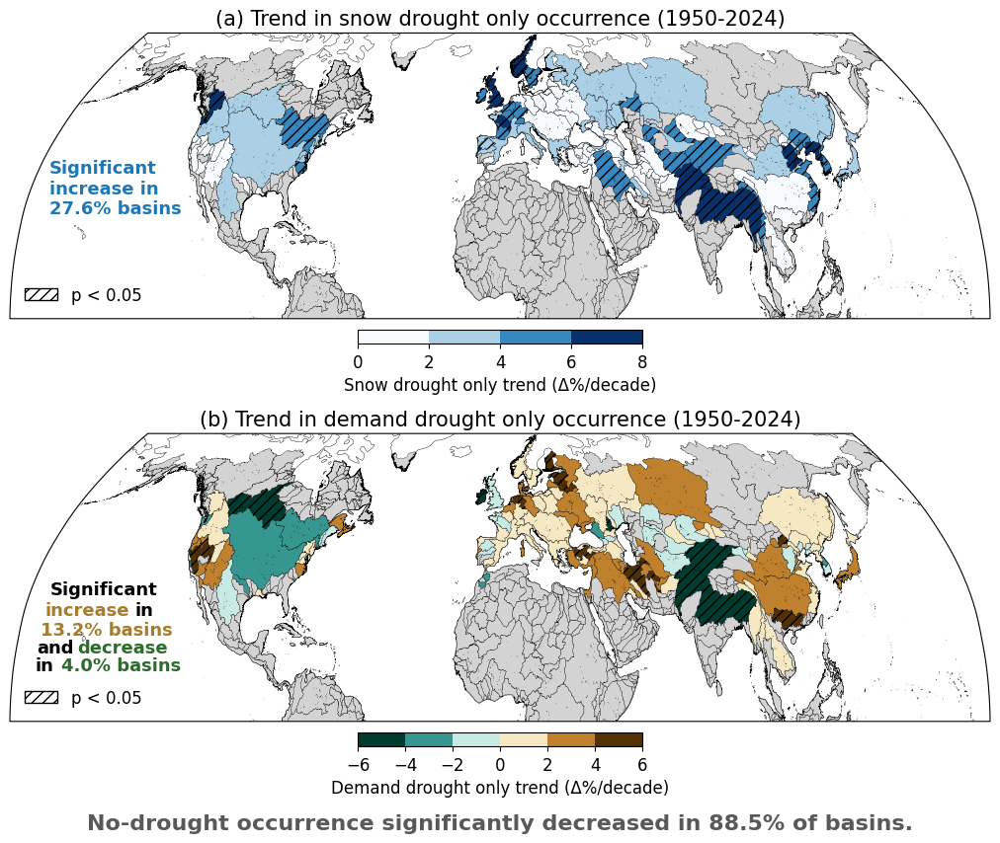

In [120]:
basins_diss_plot = basins_diss.copy()
trend_cols = [
    "snow_trend",
    "snow_p",
    "demand_trend",
    "demand_p",
    "normal_trend",
    "normal_p"
]

# Remove old or misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=trend_cols,
    errors="ignore"
)

# Join the correct 174-basin results
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_174[
        ["MAIN_BAS"] + trend_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ============================================================
# Calculate significant trend percentages
# ============================================================

def significant_trend_stats(gdf, trend_col, p_col, alpha=0.05):
    valid = gdf[trend_col].notna() & gdf[p_col].notna()
    sig = valid & (gdf[p_col] < alpha)

    increasing = sig & (gdf[trend_col] > 0)
    decreasing = sig & (gdf[trend_col] < 0)

    n_valid = int(valid.sum())
    n_increasing = int(increasing.sum())
    n_decreasing = int(decreasing.sum())

    pct_increasing = (
        100 * n_increasing / n_valid
        if n_valid > 0 else np.nan
    )

    pct_decreasing = (
        100 * n_decreasing / n_valid
        if n_valid > 0 else np.nan
    )

    return pct_increasing, pct_decreasing


snow_pct_increase, snow_pct_decrease = significant_trend_stats(
    basins_diss_174,
    "snow_trend",
    "snow_p"
)

demand_pct_increase, demand_pct_decrease = significant_trend_stats(
    basins_diss_174,
    "demand_trend",
    "demand_p"
)

normal_pct_increase, normal_pct_decrease = significant_trend_stats(
    basins_diss_174,
    "normal_trend",
    "normal_p"
)

# -----------------------------
# Layout
# -----------------------------

fig = plt.figure(figsize=(16, 12))

ax_a = fig.add_axes([0.05, 0.62, 0.62, 0.30], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.28, 0.62, 0.30], projection=ccrs.Robinson())

# ============================================================
# (a) Snow drought only trend map
# ============================================================

snow_bins = [0, 2, 4, 6, 8]
snow_cmap = plt.get_cmap("Blues", len(snow_bins) - 1)

snow_norm = mcolors.BoundaryNorm(
    boundaries=snow_bins,
    ncolors=snow_cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="snow_trend",
    cmap=snow_cmap,
    norm=snow_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_a
)

# Significant snow-drought trends
snow_sig_mask = (
    basins_diss_plot["snow_p"]
    .lt(0.05)
    .fillna(False)
)

basins_diss_plot.loc[snow_sig_mask].plot(
    ax=ax_a,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_a = cm.ScalarMappable(cmap=snow_cmap, norm=snow_norm)
sm_a.set_array([])

cbar_a = plt.colorbar(
    sm_a,
    ax=ax_a,
    orientation="horizontal",
    boundaries=snow_bins,
    ticks=snow_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_a.set_label(
    "Snow drought only trend (Δ%/decade)",
    fontsize=12
)
cbar_a.ax.tick_params(labelsize=12)

hatch_patch = mpatches.Patch(
    facecolor="white",
    edgecolor="black",
    hatch="///",
    label="p < 0.05"
)

ax_a.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

ax_a.text(
    -170,
    25,
    f"Significant\nincrease in\n"
    f"{snow_pct_increase:.1f}% basins",
    color="#1F77B4",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_a.set_title(
    "(a) Trend in snow drought only occurrence (1950-2024)",
    fontsize=15
)

ax_a.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_a.coastlines(linewidth=0.3)

# ============================================================
# (b) Demand drought only trend map
# ============================================================
demand_bins = [-6, -4, -2, 0, 2, 4, 6]
demand_cmap = plt.get_cmap("BrBG_r", len(demand_bins) - 1)

demand_norm = mcolors.BoundaryNorm(
    boundaries=demand_bins,
    ncolors=demand_cmap.N,
    clip=True
)

basins_diss_plot.plot(
    column="demand_trend",
    cmap=demand_cmap,
    norm=demand_norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "label": "Not included in analysis"
    },
    ax=ax_b
)

# Significant demand-drought trends
demand_sig_mask = (
    basins_diss_plot["demand_p"]
    .lt(0.05)
    .fillna(False)
)

basins_diss_plot.loc[demand_sig_mask].plot(
    ax=ax_b,
    facecolor="none",
    edgecolor="black",
    hatch="///",
    linewidth=0,
    transform=ccrs.PlateCarree()
)

sm_b = cm.ScalarMappable(cmap=demand_cmap, norm=demand_norm)
sm_b.set_array([])

cbar_b = plt.colorbar(
    sm_b,
    ax=ax_b,
    orientation="horizontal",
    boundaries=demand_bins,
    ticks=demand_bins,
    pad=0.03,
    fraction=0.04,
    spacing="proportional"
)

cbar_b.set_label(
    "Demand drought only trend (Δ%/decade)",
    fontsize=12
)
cbar_b.ax.tick_params(labelsize=12)

ax_b.legend(
    handles=[hatch_patch],
    loc="lower left",
    frameon=False,
    fontsize=12
)

x = -172
y = 30
dy = 6

ax_b.text(
    x, y,
    "Significant",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-0.8*dy,
    "increase",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+34, y-0.8*dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-1.6*dy,
    f"{demand_pct_increase:.1f}% basins",
    color="#A67C2D",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-2.3*dy,
    "and",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+15, y-2.3*dy,
    "decrease",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x, y-3*dy,
    "in",
    color="black",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.text(
    x+10, y-3*dy,
    f"{demand_pct_decrease:.1f}% basins",
    color="#2E6B2E",
    fontsize=13,
    fontweight="bold",
    transform=ccrs.PlateCarree()
)

ax_b.set_title(
    "(b) Trend in demand drought only occurrence (1950-2024)",
    fontsize=15
)

ax_b.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax_b.coastlines(linewidth=0.3)

fig.text(
    0.36,          # horizontal position
    0.21,         # vertical position (below panel b)
    f"No-drought occurrence significantly decreased in "
    f"{normal_pct_decrease:.1f}% of basins.",
    color="0.35",
    fontsize=16,
    fontweight="bold",
    ha="center"
)

# -----------------------------
# Save
# -----------------------------
plt.savefig(
    "Fig_S3",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

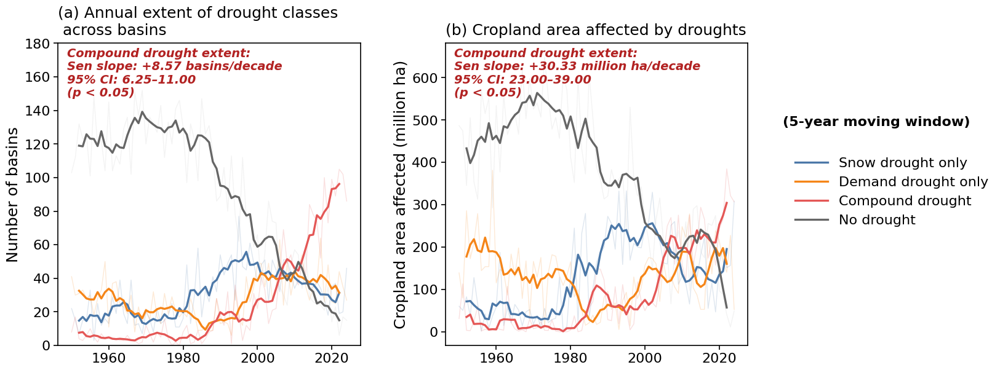

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import theilslopes, kendalltau

# ============================================================
# Helper function for Sen trend annotation
# ============================================================

def sen_trend_text(da, unit_label):
    x = da["wy"].values.astype(float)
    y = da.values.astype(float)

    mask = np.isfinite(x) & np.isfinite(y)

    sen_slope, intercept, lower, upper = theilslopes(
        y[mask],
        x[mask],
        alpha=0.95
    )

    tau, p = kendalltau(
        x[mask],
        y[mask]
    )

    trend_decade = sen_slope * 10
    lower_decade = lower * 10
    upper_decade = upper * 10

    sign = "+" if trend_decade > 0 else ""

    if p < 0.05:
        p_text = "p < 0.05"
    else:
        p_text = f"p = {p:.3f}"

    text = (
        "Compound drought extent:\n"
        f"Sen slope: {sign}{trend_decade:.2f} {unit_label}/decade\n"
        f"95% CI: {lower_decade:.2f}–{upper_decade:.2f}\n"
        f"({p_text})"
    )

    return text, trend_decade, p


# ============================================================
# Convert absolute cropland area from km2 to million hectares
# ============================================================

compound_crop_area_mha = compound_crop_area_km2 / 1e4
snow_crop_area_mha     = snow_crop_area_km2 / 1e4
demand_crop_area_mha   = demand_crop_area_km2 / 1e4
normal_crop_area_mha   = normal_crop_area_km2 / 1e4

# ============================================================
# Rolling means
# ============================================================

WINDOW = 5

# Number of basins
rolling_snow_n     = snow_ts.rolling(wy=WINDOW, center=True).mean()
rolling_demand_n   = demand_ts.rolling(wy=WINDOW, center=True).mean()
rolling_compound_n = compound_ts.rolling(wy=WINDOW, center=True).mean()
rolling_normal_n   = nodrought_ts.rolling(wy=WINDOW, center=True).mean()

# Cropland area
rolling_snow_area     = snow_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_demand_area   = demand_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_compound_area = compound_crop_area_mha.rolling(wy=WINDOW, center=True).mean()
rolling_normal_area   = normal_crop_area_mha.rolling(wy=WINDOW, center=True).mean()

# ============================================================
# Trend annotations
# ============================================================

basin_text, basin_trend, basin_p = sen_trend_text(
    compound_ts,
    "basins"
)

area_text, area_trend, area_p = sen_trend_text(
    compound_crop_area_mha,
    "million ha"
)

# ============================================================
# Plot settings
# ============================================================

colors = {
    "snow": "#4C78A8",
    "demand": "#F58518",
    "compound": "#E45756",
    "normal": "0.4"
}

annual_alpha = 0.18
annual_lw = 1.0
rolling_lw = 2.4

title_fs = 18
label_fs = 18
tick_fs = 16
legend_fs = 16
annotation_fs = 14


# ============================================================
# Figure layout: panel (a), panel (b), shared legend
# ============================================================

fig = plt.figure(figsize=(18, 7.5))

gs = fig.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1.45, 1.45, 0.40],
    wspace=0.37
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
leg_ax = fig.add_subplot(gs[0, 2])
leg_ax.axis("off")

ax1.set_box_aspect(1)
ax2.set_box_aspect(1)

# ============================================================
# Panel (a): Annual extent of drought classes across basins
# ============================================================

# Annual thin lines
ax1.plot(compound_174.wy, snow_ts, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_174.wy, demand_ts, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_174.wy, compound_ts, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax1.plot(compound_174.wy, nodrought_ts, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax1.plot(rolling_snow_n.wy, rolling_snow_n, color=colors["snow"], linewidth=rolling_lw)
ax1.plot(rolling_demand_n.wy, rolling_demand_n, color=colors["demand"], linewidth=rolling_lw)
ax1.plot(rolling_compound_n.wy, rolling_compound_n, color=colors["compound"], linewidth=rolling_lw)
ax1.plot(rolling_normal_n.wy, rolling_normal_n, color=colors["normal"], linewidth=rolling_lw)

ax1.set_title(
    "(a) Annual extent of drought classes \n across basins",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax1.set_ylabel(
    "Number of basins",
    fontsize=label_fs
)

ax1.set_ylim(0, 180)

ax1.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

ax1.text(
    0.03,
    0.985,
    basin_text,
    transform=ax1.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)


# ============================================================
# Panel (b): Cropland area affected by droughts
# ============================================================

# Annual thin lines
ax2.plot(compound_crop_area_mha.wy, snow_crop_area_mha, color=colors["snow"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_area_mha.wy, demand_crop_area_mha, color=colors["demand"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_area_mha.wy, compound_crop_area_mha, color=colors["compound"], alpha=annual_alpha, linewidth=annual_lw)
ax2.plot(compound_crop_area_mha.wy, normal_crop_area_mha, color="0.75", alpha=annual_alpha, linewidth=annual_lw)

# 5-year rolling means
ax2.plot(rolling_snow_area.wy, rolling_snow_area, color=colors["snow"], linewidth=rolling_lw)
ax2.plot(rolling_demand_area.wy, rolling_demand_area, color=colors["demand"], linewidth=rolling_lw)
ax2.plot(rolling_compound_area.wy, rolling_compound_area, color=colors["compound"], linewidth=rolling_lw)
ax2.plot(rolling_normal_area.wy, rolling_normal_area, color=colors["normal"], linewidth=rolling_lw)

ax2.set_title(
    "(b) Cropland area affected by droughts",
    fontsize=title_fs,
    loc="left",
    pad=10
)

ax2.set_ylabel(
    "Cropland area affected (million ha)",
    fontsize=label_fs
)

ax2.tick_params(
    axis="both",
    labelsize=tick_fs,
    width=1.2,
    length=5,
    colors="black"
)

ax2.text(
    0.03,
    0.985,
    area_text,
    transform=ax2.transAxes,
    fontsize=annotation_fs,
    color="#B22222",
    ha="left",
    va="top",
    fontstyle="italic",
    fontweight="bold",
    linespacing=1.15
)

# ============================================================
# Shared legend on the right
# ============================================================

legend_handles = [
    Line2D([0], [0], color=colors["snow"], linewidth=rolling_lw, label="Snow drought only"),
    Line2D([0], [0], color=colors["demand"], linewidth=rolling_lw, label="Demand drought only"),
    Line2D([0], [0], color=colors["compound"], linewidth=rolling_lw, label="Compound drought"),
    Line2D([0], [0], color=colors["normal"], linewidth=rolling_lw, label="No drought"),
]

leg_ax.text(
    -0.60,
    0.72,
    f"({WINDOW}-year moving window)",
    fontsize=legend_fs,
    fontweight="bold",
    ha="left",
    va="top"
)

leg_ax.legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(-0.60, 0.64),
    frameon=False,
    fontsize=legend_fs,
    handlelength=2.4
)

# ============================================================
# Final formatting
# ============================================================

for ax in [ax1, ax2]:
    for side in ["top", "bottom", "left", "right"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color("black")
        ax.spines[side].set_linewidth(1.2)

plt.savefig(
    "Fig_S4.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white"
)

plt.show()

In [122]:
# Basins with at least one valid water year
analysis_mask = valid_wy.any("wy")

print("Total regions:", analysis_mask.size)             # 602
print("Number of analysis basins:", int(analysis_mask.sum()))  # 174

# Positions of the 174 analysis basins
analysis_pos = np.flatnonzero(analysis_mask.values)

# Subset all drought-category arrays by position
compound_174 = compound.isel(region=analysis_pos)
snow_174     = low_swe_only.isel(region=analysis_pos)
demand_174   = high_eto_only.isel(region=analysis_pos)
normal_174   = normal.isel(region=analysis_pos)

print("Compound basins:", compound_174.sizes["region"])
print("Snow-only basins:", snow_174.sizes["region"])
print("Demand-only basins:", demand_174.sizes["region"])
print("No-drought basins:", normal_174.sizes["region"])

Total regions: 602
Number of analysis basins: 174
Compound basins: 174
Snow-only basins: 174
Demand-only basins: 174
No-drought basins: 174


In [123]:
# Positions of the 174 analysis basins
analysis_mask = valid_wy.any("wy")
analysis_pos = np.flatnonzero(analysis_mask.values)

# Select matching basin geometries in exactly the same positional order
basins_diss_174 = (
    basins_diss.iloc[analysis_pos]
    .copy()
    .reset_index(drop=True)
)

# Actual basin IDs in the correct order
selected_ids = basins_diss_174["MAIN_BAS"].to_numpy()

# Subset drought arrays and assign actual basin IDs
compound_174 = (
    compound.isel(region=analysis_pos)
    .assign_coords(region=selected_ids)
)

snow_174 = (
    low_swe_only.isel(region=analysis_pos)
    .assign_coords(region=selected_ids)
)

demand_174 = (
    high_eto_only.isel(region=analysis_pos)
    .assign_coords(region=selected_ids)
)

normal_174 = (
    normal.isel(region=analysis_pos)
    .assign_coords(region=selected_ids)
)

# Verify alignment
assert len(basins_diss_174) == compound_174.sizes["region"] == 174

assert np.array_equal(
    basins_diss_174["MAIN_BAS"].to_numpy(),
    compound_174["region"].values
)

print("Alignment confirmed.")

Alignment confirmed.


In [124]:
# Split water years into two halves
years = compound_174.wy.values

mid_idx = len(years) // 2

first_half_years = years[:mid_idx + 1]      # 1950–1987 (38 years)
second_half_years = years[mid_idx + 1:]     # 1988–2024 (37 years)

first_start = int(first_half_years[0])
first_end   = int(first_half_years[-1])

second_start = int(second_half_years[0])
second_end   = int(second_half_years[-1])

print(f"Period 1: {first_start}–{first_end}")
print(f"Period 2: {second_start}–{second_end}")

Period 1: 1950–1987
Period 2: 1988–2024


In [125]:
compound_1 = compound_174.sel(wy=slice(first_start, first_end))
compound_2 = compound_174.sel(wy=slice(second_start, second_end))

snow_1 = snow_174.sel(wy=slice(first_start, first_end))
snow_2 = snow_174.sel(wy=slice(second_start, second_end))

demand_1 = demand_174.sel(wy=slice(first_start, first_end))
demand_2 = demand_174.sel(wy=slice(second_start, second_end))

normal_1 = normal_174.sel(wy=slice(first_start, first_end))
normal_2 = normal_174.sel(wy=slice(second_start, second_end))

In [126]:
# Compute per-basin trend for each half

def basin_trend_per_period(da):

    x = da["wy"].values.astype(float)
    
    slopes = np.full(da.sizes["region"], np.nan)
    pvals = np.full(da.sizes["region"], np.nan)    

    for r in range(da.sizes["region"]):
        y = da.isel(region=r).values.astype(float)
        
        mask = np.isfinite(x) & np.isfinite(y)

        if mask.sum() < 2:
            continue

        x_mask = x[mask]
        y_mask = y[mask]

        if np.std(y_mask) == 0:
            # Valid constant occurrence series: no trend
            slopes[r] = 0.0
            pvals[r] = 1.0

        else:
            result = stats.linregress(x_mask, y_mask)
            slopes[r] = result.slope
            pvals[r] = result.pvalue

    return slopes, pvals

# Drought classes for each period
drought_classes = {
    "compound": (compound_1, compound_2),
    "snow": (snow_1, snow_2),
    "demand": (demand_1, demand_2),
    "normal": (normal_1, normal_2)
}

# Compute and attach trends
alpha = 0.05

# Already aligned with the 174-region drought arrays
basins_diss_periods = basins_diss_174.copy()

assert len(basins_diss_periods) == compound_1.sizes["region"] == 174

assert np.array_equal(
    basins_diss_periods["MAIN_BAS"].values,
    compound_1["region"].values
)

for name, (da_1, da_2) in drought_classes.items():

    slope_1, p_1 = basin_trend_per_period(da_1)
    slope_2, p_2 = basin_trend_per_period(da_2)

    trend_1_pct_decade = slope_1 * 10 * 100
    trend_2_pct_decade = slope_2 * 10 * 100
    trend_diff_pct_decade = trend_2_pct_decade - trend_1_pct_decade

    basins_diss_periods[f"{name}_trend_1_pct_decade"] = trend_1_pct_decade
    basins_diss_periods[f"{name}_trend_2_pct_decade"] = trend_2_pct_decade
    basins_diss_periods[f"{name}_trend_diff_pct_decade"] = trend_diff_pct_decade

    basins_diss_periods[f"{name}_p_1"] = p_1
    basins_diss_periods[f"{name}_p_2"] = p_2

    basins_diss_periods[f"sig_{name}_trend_1"] = np.isfinite(p_1) & (p_1 < alpha)
    basins_diss_periods[f"sig_{name}_trend_2"] = np.isfinite(p_2) & (p_2 < alpha)

print("Basins in period analysis:", len(basins_diss_periods))

Basins in period analysis: 174


In [127]:
# Summary for all drought classes and periods
trend_classes = {
    "Compound drought": "compound",
    "Snow drought only": "snow",
    "Demand drought only": "demand",
    "No drought": "normal"
}

n_total = len(basins_diss_periods)  

for class_label, col_prefix in trend_classes.items():

    print(f"\n{class_label}")

    for period_label in ["1", "2"]:

        trend_col = f"{col_prefix}_trend_{period_label}_pct_decade"
        sig_col = f"sig_{col_prefix}_trend_{period_label}"

        trend = basins_diss_periods[trend_col]
        sig = basins_diss_periods[sig_col].fillna(False).astype(bool)

        valid = trend.notna()

        pos = valid & sig & (trend > 0)
        neg = valid & sig & (trend < 0)

        n_valid = int(valid.sum())
        n_sig = int((valid & sig).sum())
        n_pos = int(pos.sum())
        n_neg = int(neg.sum())

        # Use valid basins as the denominator
        pct_sig = 100 * n_sig / n_valid if n_valid > 0 else np.nan
        pct_pos = 100 * n_pos / n_valid if n_valid > 0 else np.nan
        pct_neg = 100 * n_neg / n_valid if n_valid > 0 else np.nan

        print(f"\nPeriod {period_label}")
        print("Total analysis basins:", n_total)
        print("Valid basins:", n_valid)
        print(f"Significant: {n_sig} ({pct_sig:.1f}%)")
        print(f"Increasing: {n_pos} ({pct_pos:.1f}%)")
        print(f"Decreasing: {n_neg} ({pct_neg:.1f}%)")

print(basins_diss_periods.columns)


Compound drought

Period 1
Total analysis basins: 174
Valid basins: 174
Significant: 7 (4.0%)
Increasing: 3 (1.7%)
Decreasing: 4 (2.3%)

Period 2
Total analysis basins: 174
Valid basins: 174
Significant: 100 (57.5%)
Increasing: 100 (57.5%)
Decreasing: 0 (0.0%)

Snow drought only

Period 1
Total analysis basins: 174
Valid basins: 174
Significant: 21 (12.1%)
Increasing: 18 (10.3%)
Decreasing: 3 (1.7%)

Period 2
Total analysis basins: 174
Valid basins: 174
Significant: 24 (13.8%)
Increasing: 2 (1.1%)
Decreasing: 22 (12.6%)

Demand drought only

Period 1
Total analysis basins: 174
Valid basins: 174
Significant: 37 (21.3%)
Increasing: 5 (2.9%)
Decreasing: 32 (18.4%)

Period 2
Total analysis basins: 174
Valid basins: 174
Significant: 15 (8.6%)
Increasing: 15 (8.6%)
Decreasing: 0 (0.0%)

No drought

Period 1
Total analysis basins: 174
Valid basins: 174
Significant: 35 (20.1%)
Increasing: 21 (12.1%)
Decreasing: 14 (8.0%)

Period 2
Total analysis basins: 174
Valid basins: 174
Significant: 96 (

In [128]:
# Full-period compound trend for the 174 basins
compound_slope_full, compound_p_full = basin_ols_trend(compound_174)

basins_diss_174["compound_trend_full"] = compound_slope_full
basins_diss_174["compound_p_full"] = compound_p_full
basins_diss_174["sig_compound_full"] = (
    np.isfinite(compound_p_full) &
    (compound_p_full < 0.05)
)

In [129]:
print(
    "Full period significant:",
    int(basins_diss_174["sig_compound_full"].sum())
)

print(
    "Period 2 significant:",
    int(basins_diss_periods["sig_compound_trend_2"].sum())
)

full_sig = basins_diss_174["sig_compound_full"].astype(bool)
late_sig = basins_diss_periods["sig_compound_trend_2"].astype(bool)

print("Full only:", int((full_sig & ~late_sig).sum()))
print("Late only:", int((~full_sig & late_sig).sum()))
print("Both:", int((full_sig & late_sig).sum()))
print("Neither:", int((~full_sig & ~late_sig).sum()))

Full period significant: 158
Period 2 significant: 100
Full only: 60
Late only: 2
Both: 98
Neither: 14


In [130]:
#What are valid basins?

# Examples for a split period (1950–1987):

# [0,0,0,0,0,...]   → never had compound drought
# → std = 0
# → trend = NaN

# [1,1,1,1,1,...]   → compound drought every year
# → std = 0
# → trend = NaN

# Examples that are valid:

# [0,0,1,0,1,...]
# → std > 0
# → trend estimated

# [1,0,1,1,0,...]
# → std > 0

In [131]:
def plot_trend_with_hatching(
    full_gdf,
    results_gdf,
    column,
    sig_col,
    title,
    cmap_name,
    bins,
    cbar_label
):

    # Start with all 602 basins
    plot_gdf = full_gdf.copy()

    # Remove old or misaligned versions of these columns
    plot_gdf = plot_gdf.drop(
        columns=[column, sig_col],
        errors="ignore"
    )

    # Join correctly aligned 174-basin results
    plot_gdf = plot_gdf.merge(
        results_gdf[
            ["MAIN_BAS", column, sig_col]
        ],
        on="MAIN_BAS",
        how="left"
    )

    # Discrete colormap
    n_bins = len(bins) - 1
    cmap = plt.get_cmap(cmap_name, n_bins)

    norm = mcolors.BoundaryNorm(
        boundaries=bins,
        ncolors=n_bins,
        clip=True
    )

    fig = plt.figure(figsize=(14, 7))
    ax = plt.axes(projection=ccrs.Robinson())

    # Base map
    plot_gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "gray",
            "label": "Not included in analysis"
        },
        ax=ax
    )

    # Significant basins
    sig_mask = (
        plot_gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = plot_gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    # Colorbar
    sm = cm.ScalarMappable(
        cmap=cmap,
        norm=norm
    )
    sm.set_array([])

    cbar = plt.colorbar(
        sm,
        ax=ax,
        orientation="horizontal",
        boundaries=bins,
        ticks=bins,
        pad=0.03,
        fraction=0.04,
        spacing="proportional"
    )

    cbar.set_label(
        cbar_label,
        fontsize=14
    )

    cbar.ax.tick_params(
        labelsize=12
    )

    # Hatching legend
    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(
        title,
        fontsize=18
    )

    ax.set_extent(
        [-180, 180, 0, 70],
        crs=ccrs.PlateCarree()
    )

    ax.coastlines(
        linewidth=0.3
    )

    plt.tight_layout()
    plt.show()

trend_bins = np.arange(-12, 14, 2)

compound_bins = trend_bins
snow_bins = trend_bins
demand_bins = trend_bins
normal_bins = trend_bins

Period 1: {'n_valid': 174, 'n_pos': 3, 'pct_pos': 1.7241379310344827, 'n_neg': 4, 'pct_neg': 2.2988505747126435}
Period 2: {'n_valid': 174, 'n_pos': 100, 'pct_pos': 57.47126436781609, 'n_neg': 0, 'pct_neg': 0.0}


/tmp/ipykernel_1356544/3969348913.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1356544/3969348913.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


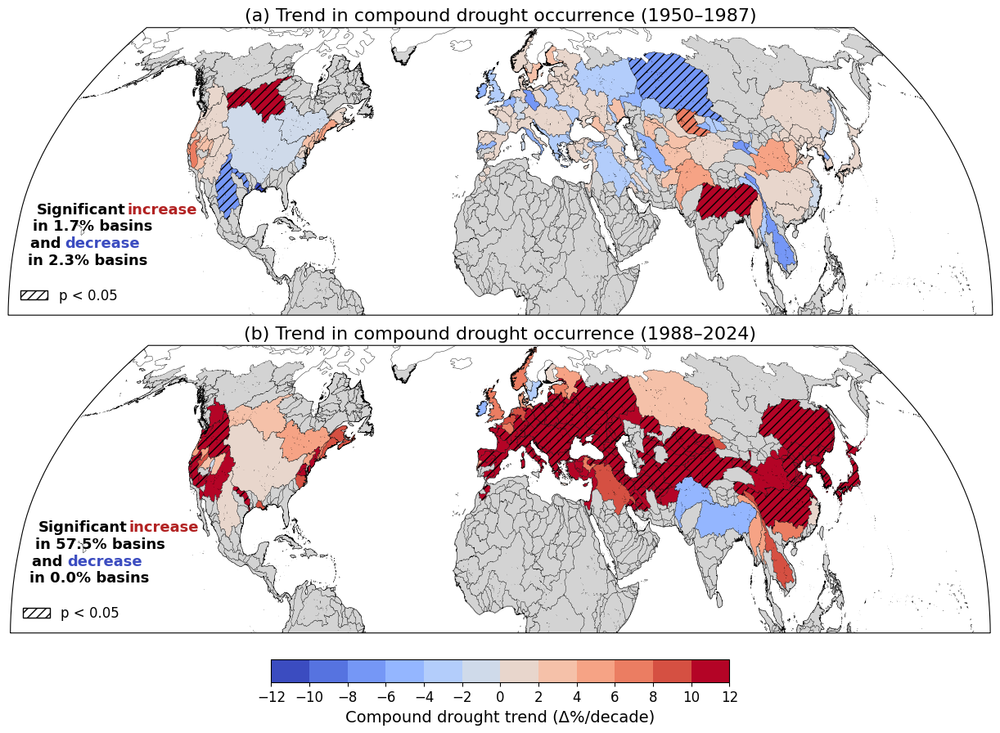

In [132]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 174-basin period results
# ------------------------------------------------------------

period_cols = [
    "compound_trend_1_pct_decade",
    "compound_trend_2_pct_decade",
    "sig_compound_trend_1",
    "sig_compound_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 174 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: compound summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]
    sig = gdf[sig_col].fillna(False).astype(bool)
    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 174 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "compound_trend_1_pct_decade",
    "sig_compound_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "compound_trend_2_pct_decade",
    "sig_compound_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot compound trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

compound_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
compound_cmap = "coolwarm"

norm = mcolors.BoundaryNorm(
    boundaries=compound_bins,
    ncolors=plt.get_cmap(compound_cmap).N,
    clip=True
)

def add_compound_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):

    gdf.plot(
        column=column,
        cmap=compound_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    sig_mask = (
        gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#B22222",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#3B4CC0",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )
        
        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)


# ------------------------------------------------------------
# Panels
# ------------------------------------------------------------
add_compound_panel(
    ax_a,
    gdf=basins_diss_plot,
    column="compound_trend_1_pct_decade",
    sig_col="sig_compound_trend_1",
    title=f"(a) Trend in compound drought occurrence ({first_start}–{first_end})",
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_compound_panel(
    ax_b,
    gdf=basins_diss_plot,
    column="compound_trend_2_pct_decade",
    sig_col="sig_compound_trend_2",
    title=f"(b) Trend in compound drought occurrence ({second_start}–{second_end})",
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)


# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=compound_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=compound_bins,
    ticks=compound_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Compound drought trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)


plt.savefig(
    "Fig_S5.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

Period 1: {'n_valid': 174, 'n_pos': 18, 'pct_pos': 10.344827586206897, 'n_neg': 3, 'pct_neg': 1.7241379310344827}
Period 2: {'n_valid': 174, 'n_pos': 2, 'pct_pos': 1.1494252873563218, 'n_neg': 22, 'pct_neg': 12.64367816091954}


/tmp/ipykernel_1356544/3409956787.py:111: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1356544/3409956787.py:111: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


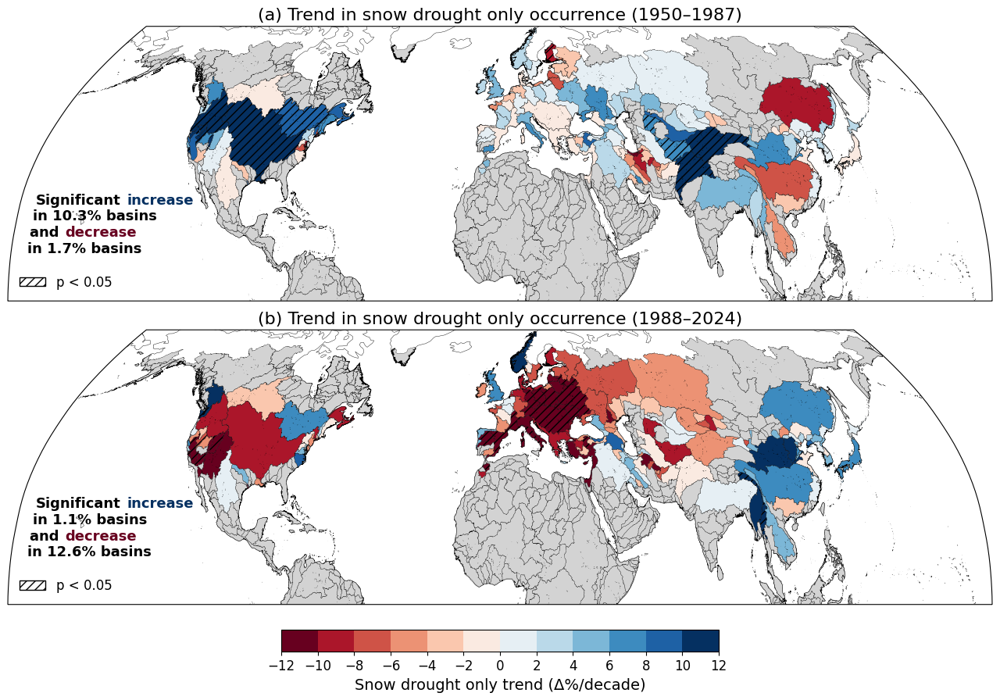

In [133]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 174-basin snow-period results
# ------------------------------------------------------------

period_cols = [
    "snow_trend_1_pct_decade",
    "snow_trend_2_pct_decade",
    "sig_snow_trend_1",
    "sig_snow_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 174 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: compound summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]
    sig = gdf[sig_col].fillna(False).astype(bool)
    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 174 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "snow_trend_1_pct_decade",
    "sig_snow_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "snow_trend_2_pct_decade",
    "sig_snow_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot compound trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

snow_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
snow_cmap = plt.get_cmap("RdBu", len(snow_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=snow_bins,
    ncolors=plt.get_cmap(snow_cmap).N,
    clip=True
)

def add_snow_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):

    gdf.plot(
        column=column,
        cmap=snow_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = (
        gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )


    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#053061",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#67001F",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=12
    )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_aspect("auto")
    ax.coastlines(linewidth=0.3)


# ------------------------------------------------------------
# Summary text for each period
# ------------------------------------------------------------
add_snow_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="snow_trend_1_pct_decade",
    sig_col="sig_snow_trend_1",
    title=(
        f"(a) Trend in snow drought only occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_snow_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="snow_trend_2_pct_decade",
    sig_col="sig_snow_trend_2",
    title=(
        f"(b) Trend in snow drought only occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=snow_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=snow_bins,
    ticks=snow_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Snow drought only trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)


plt.savefig(
    "Fig_S6.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

Period 1: {'n_valid': 174, 'n_pos': 5, 'pct_pos': 2.8735632183908044, 'n_neg': 32, 'pct_neg': 18.39080459770115}
Period 2: {'n_valid': 174, 'n_pos': 15, 'pct_pos': 8.620689655172415, 'n_neg': 0, 'pct_neg': 0.0}


/tmp/ipykernel_1356544/458089131.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1356544/458089131.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


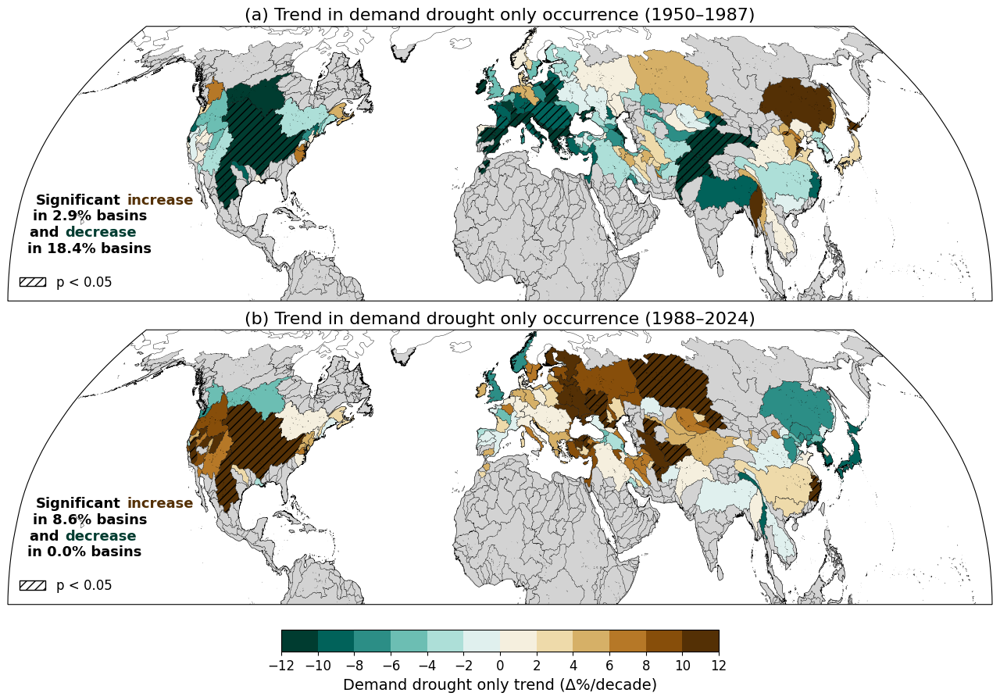

In [134]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 174-basin demand-period results
# ------------------------------------------------------------

period_cols = [
    "demand_trend_1_pct_decade",
    "demand_trend_2_pct_decade",
    "sig_demand_trend_1",
    "sig_demand_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 174 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: compound summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]
    sig = gdf[sig_col].fillna(False).astype(bool)
    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 174 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "demand_trend_1_pct_decade",
    "sig_demand_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "demand_trend_2_pct_decade",
    "sig_demand_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot demand-drought trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

demand_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
demand_cmap = plt.get_cmap("BrBG_r", len(demand_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=demand_bins,
    ncolors=plt.get_cmap(demand_cmap).N,
    clip=True
)

def add_demand_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):
    gdf.plot(
        column=column,
        cmap=demand_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = (
        gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#543005",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#003C30",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=12
    )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_aspect("auto")
    ax.coastlines(linewidth=0.3)

# ------------------------------------------------------------
# Add panels
# ------------------------------------------------------------

add_demand_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="demand_trend_1_pct_decade",
    sig_col="sig_demand_trend_1",
    title=(
        f"(a) Trend in demand drought only occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_demand_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="demand_trend_2_pct_decade",
    sig_col="sig_demand_trend_2",
    title=(
        f"(b) Trend in demand drought only occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=demand_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=demand_bins,
    ticks=demand_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "Demand drought only trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)


plt.savefig(
    "Fig_S7.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

Period 1: {'n_valid': 174, 'n_pos': 21, 'pct_pos': 12.068965517241379, 'n_neg': 14, 'pct_neg': 8.045977011494253}
Period 2: {'n_valid': 174, 'n_pos': 0, 'pct_pos': 0.0, 'n_neg': 96, 'pct_neg': 55.172413793103445}


/tmp/ipykernel_1356544/852258159.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_1356544/852258159.py:110: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


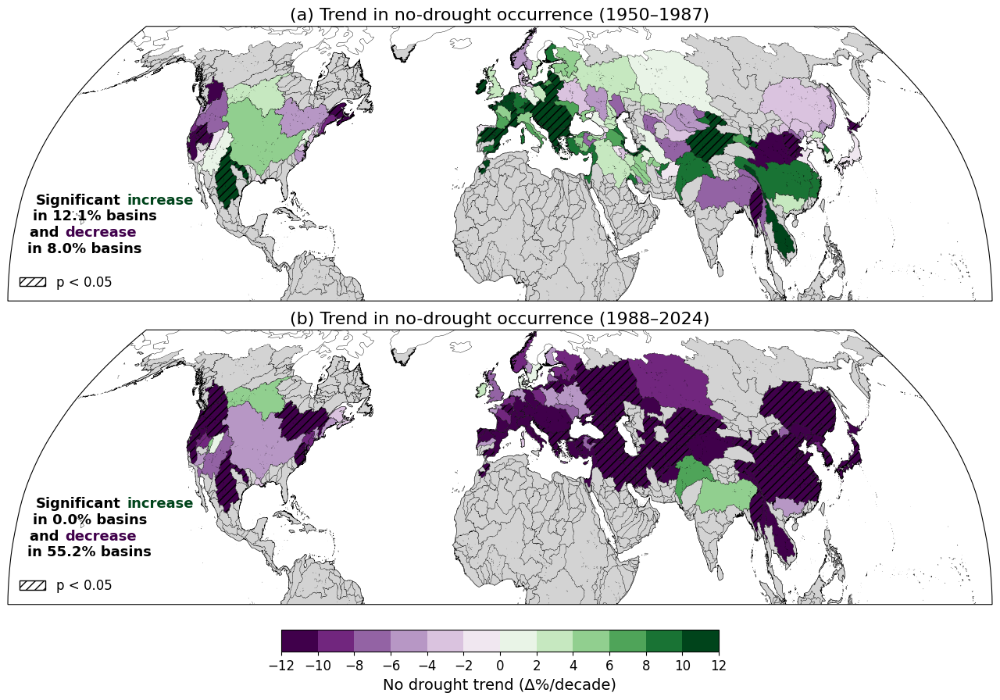

In [135]:
# ------------------------------------------------------------
# Prepare all 602 basins with the 174-basin no-drought period results
# ------------------------------------------------------------

period_cols = [
    "normal_trend_1_pct_decade",
    "normal_trend_2_pct_decade",
    "sig_normal_trend_1",
    "sig_normal_trend_2"
]

basins_diss_plot = basins_diss.copy()

# Remove old or potentially misaligned columns
basins_diss_plot = basins_diss_plot.drop(
    columns=period_cols,
    errors="ignore"
)

# Join correctly aligned results from the 174 analysis basins
basins_diss_plot = basins_diss_plot.merge(
    basins_diss_periods[
        ["MAIN_BAS"] + period_cols
    ],
    on="MAIN_BAS",
    how="left"
)

# ------------------------------------------------------------
# Helper: compound summary for a period
# ------------------------------------------------------------
def get_sig_summary(gdf, trend_col, sig_col):
    trend = gdf[trend_col]
    sig = gdf[sig_col].fillna(False).astype(bool)
    valid = trend.notna()

    pos = sig & (trend > 0)
    neg = sig & (trend < 0)

    n_valid = int(valid.sum())
    n_pos = int(pos.sum())
    n_neg = int(neg.sum())

    pct_pos = (
        100 * n_pos / n_valid
        if n_valid > 0 else np.nan
    )

    pct_neg = (
        100 * n_neg / n_valid
        if n_valid > 0 else np.nan
    )

    return {
        "n_valid": n_valid,
        "n_pos": n_pos,
        "pct_pos": pct_pos,
        "n_neg": n_neg,
        "pct_neg": pct_neg
    }

# Calculate summaries from only the 174 analysis basins
summary_1 = get_sig_summary(
    basins_diss_periods,
    "normal_trend_1_pct_decade",
    "sig_normal_trend_1"
)

summary_2 = get_sig_summary(
    basins_diss_periods,
    "normal_trend_2_pct_decade",
    "sig_normal_trend_2"
)

print("Period 1:", summary_1)
print("Period 2:", summary_2)

# ------------------------------------------------------------
# Plot no-drought trend panels
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))

ax_a = fig.add_axes([0.05, 0.50, 0.90, 0.38], projection=ccrs.Robinson())
ax_b = fig.add_axes([0.05, 0.08, 0.90, 0.38], projection=ccrs.Robinson())

nodrought_bins = [-12, -10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10, 12]
nodrought_cmap = plt.get_cmap("PRGn", len(nodrought_bins) - 1)

norm = mcolors.BoundaryNorm(
    boundaries=nodrought_bins,
    ncolors=plt.get_cmap(nodrought_cmap).N,
    clip=True
)

def add_nodrought_panel(ax, gdf, column, sig_col, title, pct_pos, pct_neg):
    gdf.plot(
        column=column,
        cmap=nodrought_cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray", "label": "Not included in analysis"},
        ax=ax
    )

    # Significant basins
    sig_mask = (
        gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    x = -174
    y = 24
    dy = 4
    
    # line 1
    ax.text(
        x,
        y,
        "Significant",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only increase
    ax.text(
        x+34,
        y,
        "increase",
        color="#00441B",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 2
    ax.text(
        x,
        y-dy,
        f"in {pct_pos:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 3
    ax.text(
        x,
        y-2*dy,
        "and ",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # recolor only decrease
    ax.text(
        x+13,
        y-2*dy,
        "decrease",
        color="#40004B",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )
    
    # line 4
    ax.text(
        x,
        y-3*dy,
        f"in {pct_neg:.1f}% basins",
        color="black",
        fontsize=13,
        fontweight="bold",
        transform=ccrs.PlateCarree()
    )

    if not sig_gdf.empty:
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

    ax.legend(
        handles=[hatch_patch],
        loc="lower left",
        frameon=False,
        fontsize=12
    )

    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.set_aspect("auto")
    ax.coastlines(linewidth=0.3)


# ------------------------------------------------------------
# Add panels
# ------------------------------------------------------------

add_nodrought_panel(
    ax=ax_a,
    gdf=basins_diss_plot,
    column="normal_trend_1_pct_decade",
    sig_col="sig_normal_trend_1",
    title=(
        f"(a) Trend in no-drought occurrence "
        f"({first_start}–{first_end})"
    ),
    pct_pos=summary_1["pct_pos"],
    pct_neg=summary_1["pct_neg"]
)

add_nodrought_panel(
    ax=ax_b,
    gdf=basins_diss_plot,
    column="normal_trend_2_pct_decade",
    sig_col="sig_normal_trend_2",
    title=(
        f"(b) Trend in no-drought occurrence "
        f"({second_start}–{second_end})"
    ),
    pct_pos=summary_2["pct_pos"],
    pct_neg=summary_2["pct_neg"]
)

# ------------------------------------------------------------
# Shared colorbar
# ------------------------------------------------------------
sm = cm.ScalarMappable(
    cmap=nodrought_cmap,
    norm=norm
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=[ax_a, ax_b],
    orientation="horizontal",
    boundaries=nodrought_bins,
    ticks=nodrought_bins,
    pad=0.04,
    fraction=0.035,
    spacing="proportional"
)

cbar.set_label(
    "No drought trend (Δ%/decade)",
    fontsize=14
)

cbar.ax.tick_params(labelsize=12)


plt.savefig(
    "Fig_S8.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.05
)

plt.show()

In [163]:
print(
    f"Water year range: "
    f"{compound_174.wy.min().item()}–{compound_174.wy.max().item()}"
)
print(f"Number of water years: {compound_174.sizes['wy']}")
print(f"Number of analysis basins: {compound_174.sizes['region']}")

Water year range: 1950–2024
Number of water years: 75
Number of analysis basins: 174


In [137]:
# # ============================================================
# # Redefine drought classes using detrended SWE and ETo
# # ============================================================

# q_lo, q_hi = 0.30, 0.70

# # Valid basin-years
# valid_wy = np.isfinite(swe_peak) & np.isfinite(eto_summer)

# # Thresholds per basin from detrended series
# swe_tlow = (
#     swe_peak
#     .where(valid_wy)
#     .quantile(q_lo, dim="wy", skipna=True)
# )

# eto_thigh = (
#     eto_summer
#     .where(valid_wy)
#     .quantile(q_hi, dim="wy", skipna=True)
# )

# # Binary conditions
# low_swe = (swe_peak <= swe_tlow) & valid_wy
# high_eto = (eto_summer >= eto_thigh) & valid_wy

# # Drought classes
# normal = (~low_swe) & (~high_eto) & valid_wy
# low_swe_only = low_swe & (~high_eto) & valid_wy
# high_eto_only = (~low_swe) & high_eto & valid_wy
# compound = low_swe & high_eto & valid_wy

In [164]:
low_swe_174 = compound_174 | snow_174   #P(high ETo∣low SWE)=compound/(compound+low_swe_only)
# means:
# True if low SWE only
# True if compound drought
# False otherwise

# P(high ETo | low SWE)
n_low_swe = low_swe_174.sum("wy")
n_compound = compound_174.sum("wy")

p_cond = xr.where(
    n_low_swe > 0,
    n_compound / n_low_swe,
    np.nan
)

p_cond.name = "p_high_eto_given_low_swe"

# Safe because basins_diss_174 and compound_174 are aligned
assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    p_cond["region"].values
)

basins_diss_174["p_cond"] = p_cond.values

In [165]:
basins_diss_plot = (
    basins_diss
    .drop(columns=["p_cond"], errors="ignore")
    .merge(
        basins_diss_174[["MAIN_BAS", "p_cond"]],
        on="MAIN_BAS",
        how="left"
    )
)

In [166]:
# Test whether P(high ETo | low SWE) > P(high ETo)
# Does having low SWE increase the probability of high ETo?

pvals_cond = []

for r in range(compound_174.sizes["region"]):

    comp = compound_174.isel(region=r).astype(float).values

    low = (
        compound_174.isel(region=r)
        | snow_174.isel(region=r)
    ).astype(float).values

    high_eto_basin = (
        compound_174.isel(region=r)
        | demand_174.isel(region=r)
    ).astype(float).values

    valid = (
        np.isfinite(comp)
        & np.isfinite(low)
        & np.isfinite(high_eto_basin)
    )

    comp_valid = comp[valid]
    low_valid = low[valid]
    high_valid = high_eto_basin[valid]

    trials = int(low_valid.sum())

    if trials > 0:

        successes = int(comp_valid.sum())

        # Unconditional probability of high ETo
        p_expected = float(np.mean(high_valid))

        if 0 < p_expected < 1:
            p = binomtest(
                successes,
                trials,
                p_expected,
                alternative="greater"
            ).pvalue
        else:
            p = np.nan

    else:
        p = np.nan

    pvals_cond.append(p)

pvals_cond = np.asarray(pvals_cond)

# Add results to the aligned 174-basin GeoDataFrame
basins_diss_174["p_cond_pval"] = pvals_cond
basins_diss_174["sig_p_cond"] = (
    np.isfinite(pvals_cond)
    & (pvals_cond < 0.05)
)

In [167]:
assert len(pvals_cond) == len(basins_diss_174) == 174

assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    compound_174["region"].values
)

In [169]:
# Compute excess probability
# Overall probability of high ETo in each of the 174 analysis basins
high_eto_174 = compound_174 | demand_174

# Number of valid WYs for each analysis basin
valid_wy_174 = valid_wy.isel(region=analysis_pos).assign_coords(
    region=compound_174["region"].values
)

n_valid_wy = valid_wy_174.sum("wy")

p_expected = xr.where(
    n_valid_wy > 0,
    high_eto_174.sum("wy") / n_valid_wy,
    np.nan
)

# Excess conditional probability:
# P(high ETo | low SWE) - P(high ETo)
p_cond_excess = p_cond - p_expected

# Confirm basin alignment
assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    p_cond_excess["region"].values
)


# Add to the aligned 174-basin GeoDataFrame
basins_diss_174["p_expected"] = p_expected.values
basins_diss_174["p_cond_excess"] = p_cond_excess.values

In [170]:
print(
    basins_diss_174[
        ["MAIN_BAS", "p_cond", "p_expected", "p_cond_excess"]
    ].head()
)

     MAIN_BAS    p_cond  p_expected  p_cond_excess
0  1040029430  0.478261    0.306667       0.171594
1  1040029700  0.478261    0.306667       0.171594
2  2040000010  0.434783    0.306667       0.128116
3  2040003440  0.434783    0.306667       0.128116
4  2040003550  0.565217    0.306667       0.258551


In [171]:
# Summarize conditional-probability results across the 174 analysis basins

excess = basins_diss_174["p_cond_excess"]

sig = (
    basins_diss_174["sig_p_cond"]
    .fillna(False)
    .astype(bool)
)

valid = (
    excess.notna()
    & basins_diss_174["p_cond_pval"].notna()
)

# Significant positive excess probability
pos = valid & sig & (excess > 0)

n_valid = int(valid.sum())
n_sig = int((valid & sig).sum())
n_pos = int(pos.sum())

median_excess = np.nanmedian(excess[valid])

print(
    "Median excess probability:",
    round(median_excess, 3)
)

print(f"Valid basins: {n_valid}")

print(
    f"Significant basins: {n_sig} "
    f"({100 * n_sig / n_valid:.1f}%)"
)

print(
    f"Significant increase: {n_pos} "
    f"({100 * n_pos / n_valid:.1f}%)"
)

Median excess probability: 0.172
Valid basins: 174
Significant basins: 66 (37.9%)
Significant increase: 66 (37.9%)


In [172]:
# ============================================================
# Prepare all 602 basins with 174-basin conditional results
# ============================================================

conditional_cols = [
    "p_cond",
    "p_expected",
    "p_cond_excess",
    "p_cond_pval",
    "sig_p_cond"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=conditional_cols, errors="ignore")
    .merge(
        basins_diss_174[
            ["MAIN_BAS"] + conditional_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

/tmp/ipykernel_1356544/341459072.py:21: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  sig = gdf[sig_col].fillna(False).astype(bool)


Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_S9_1.png


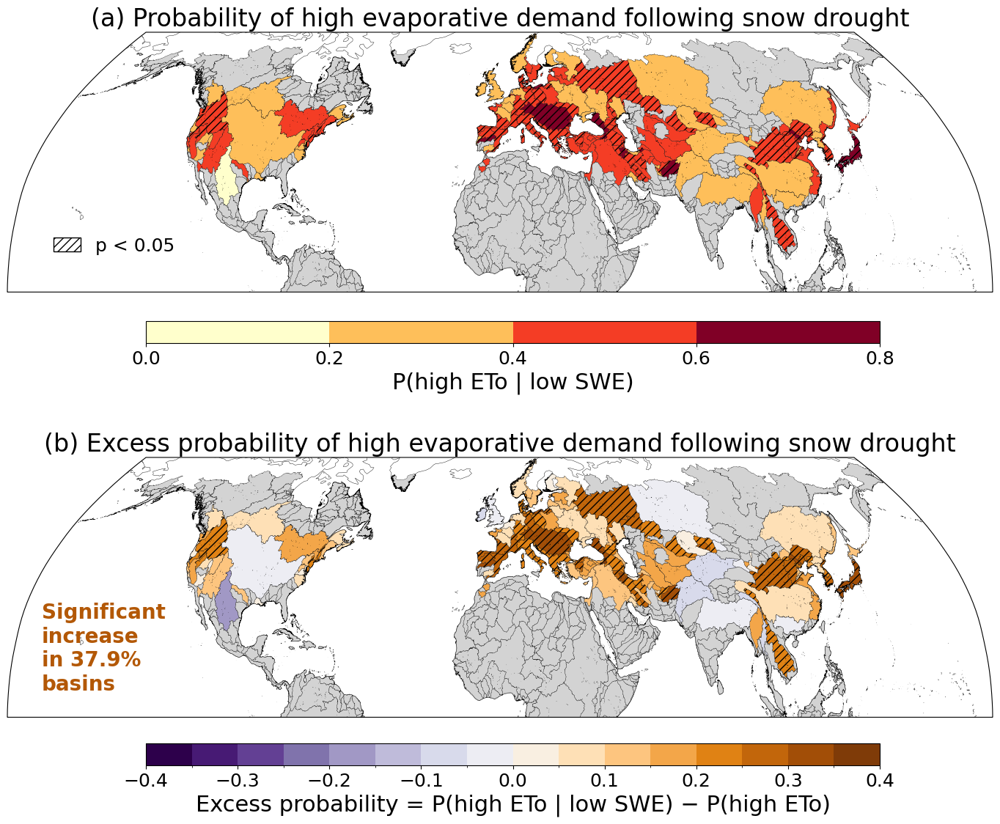

In [173]:
def plot_pcond_panels_vertical(
    gdf,
    pcond_col="p_cond",
    excess_col="p_cond_excess",
    sig_col="sig_p_cond",
    extent=(-180, 180, 0, 70),
    hatch="///"
):
    """
    Plot:
    (a) P(high ETo | low SWE)
    (b) Excess probability = P(high ETo | low SWE) - P(high ETo)

    Significance hatching is based on sig_col.
    """

    # ============================================================
    # Summary statistics for annotation in panel (b)
    # ============================================================
    
    sig = gdf[sig_col].fillna(False).astype(bool)
    excess = gdf[excess_col]
    valid = excess.notna()

    pos_sig = sig & (excess > 0)

    n_valid = int(valid.sum())
    n_pos_sig = int(pos_sig.sum())

    pct_pos_sig = 100 * n_pos_sig / n_valid if n_valid > 0 else np.nan

    # ============================================================
    # Figure and axes
    # ============================================================
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(14, 12),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax1, ax2 = axes

    title_fs = 24
    cbar_label_fs = 22
    tick_fs = 18
    annotation_fs = 20

    # ============================================================
    # Panel (a): Conditional probability
    # ============================================================
    bins_a = [0.0, 0.2, 0.4, 0.6, 0.8]

    cmap_a = plt.get_cmap("YlOrRd", len(bins_a) - 1)

    norm_a = mcolors.BoundaryNorm(
        boundaries=bins_a,
        ncolors=cmap_a.N,
        clip=True
    )

    ax1.set_global()

    gdf.plot(
        column=pcond_col,
        cmap=cmap_a,
        norm=norm_a,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax1
    )

    sig_gdf = gdf.loc[sig]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax1,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )
        
        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

    ax1.legend(
        handles=[hatch_patch],
        loc="lower left",
        bbox_to_anchor=(0.03, 0.08),
        frameon=False,
        fontsize=18,
        handlelength=1.5,
        handleheight=0.8
    )

    ax1.set_title(
        "(a) Probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax1.set_extent(extent, crs=ccrs.PlateCarree())
    ax1.coastlines(linewidth=0.3)

    # Colorbar for panel (a)
    fig.canvas.draw()
    pos1 = ax1.get_position()

    cax1 = fig.add_axes([
        pos1.x0 + 0.03,
        pos1.y0 - 0.04,
        pos1.width - 0.06,
        0.025
    ])

    sm1 = plt.cm.ScalarMappable(norm=norm_a, cmap=cmap_a)
    sm1.set_array([])

    cb1 = fig.colorbar(
        sm1,
        cax=cax1,
        orientation="horizontal",
        boundaries=bins_a,
        ticks=bins_a,
        spacing="proportional"
    )

    cb1.set_label(
        "P(high ETo | low SWE)",
        fontsize=cbar_label_fs
    )

    cb1.ax.tick_params(labelsize=tick_fs)

    # ============================================================
    # Panel (b): Excess probability
    # ============================================================
    bounds_b = np.arange(-0.4, 0.45, 0.05)

    # Use PuOr_r so that:
    # negative/decrease = purple
    # positive/increase = orange
    cmap_b = plt.get_cmap("PuOr_r", len(bounds_b) - 1)

    norm_b = mcolors.BoundaryNorm(
        boundaries=bounds_b,
        ncolors=cmap_b.N,
        clip=True
    )

    ax2.set_global()

    gdf.plot(
        column=excess_col,
        cmap=cmap_b,
        norm=norm_b,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax2
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax2,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    ax2.set_title(
        "(b) Excess probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax2.set_extent(extent, crs=ccrs.PlateCarree())
    ax2.coastlines(linewidth=0.3)

    # ------------------------------------------------------------
    # Add significant increase annotation on left side of panel (b)
    # ------------------------------------------------------------
    ax2.text(
        -170, 18,
        f"Significant \nincrease\nin {pct_pos_sig:.1f}% \nbasins",
        transform=ccrs.PlateCarree(),
        fontsize=annotation_fs,
        color="#B35806",   # orange from PuOr-like palette
        ha="left",
        va="center",
        fontweight="bold"
    )

    # Colorbar for panel (b)
    fig.canvas.draw()
    pos2 = ax2.get_position()

    cax2 = fig.add_axes([
        pos2.x0 + 0.03,
        pos2.y0 - 0.10,
        pos2.width - 0.06,
        0.025
    ])

    sm2 = plt.cm.ScalarMappable(norm=norm_b, cmap=cmap_b)
    sm2.set_array([])

    cb2 = fig.colorbar(
        sm2,
        cax=cax2,
        orientation="horizontal",
        boundaries=bounds_b,
        ticks=[-0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4],
        spacing="proportional"
    )

    cb2.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=cbar_label_fs
    )

    cb2.ax.tick_params(labelsize=tick_fs)

    # ============================================================
    # Final spacing
    # ============================================================
    plt.subplots_adjust(
        top=0.96,
        bottom=0.06,
        left=0.02,
        right=0.98,
        hspace=0.16
    )

    outpath = os.path.abspath("Fig_S9_1.png")
    fig.savefig(outpath, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure to: {outpath}")

    plt.show()

plot_pcond_panels_vertical(
    basins_diss_plot,
    pcond_col="p_cond",
    excess_col="p_cond_excess",
    sig_col="sig_p_cond"
)

In [174]:
print(
    "Median P(high ETo | low SWE):",
    round(np.nanmedian(basins_diss_174["p_cond"]), 3)
)

Median P(high ETo | low SWE): 0.478


In [175]:
median_p = np.nanmedian(basins_diss_174["p_cond"])
print(f"{median_p:.2f}")

0.48


In [176]:
median_pct = 100 * np.nanmedian(basins_diss_174["p_cond"].values)
print(f"Median conditional probability = {median_pct:.1f}%")

Median conditional probability = 47.8%


In [177]:
mean_pct = 100 * np.nanmean(basins_diss_174["p_cond"].values)
print(f"Mean conditional probability = {mean_pct:.1f}%")

Mean conditional probability = 45.9%


In [178]:
# ============================================================
# Detrend SWE peak and summer ETo before redefining drought classes
# ============================================================

def detrend_dim(da, dim="wy"):
    """
    Remove linear trend along dim.
    Returns detrended series with the original mean added back.
    Works for xarray DataArray with dims like (wy, region).
    """
    x = da[dim].astype(float)

    # center x to improve numerical stability
    x_centered = x - x.mean()

     # Valid-data mask
    valid = np.isfinite(da)

    # mean over time
    da_mean = da.mean(dim=dim, skipna=True)

    # Number of valid observations
    n_valid = valid.sum(dim=dim)

    # OLS slope = covariance(x, y) / variance(x)
    numerator = (
        ((da - da_mean) * x_centered)
        .where(valid)
        .sum(dim=dim, skipna=True)
    )

    denominator = (
        (x_centered ** 2)
        .where(valid)
        .sum(dim=dim, skipna=True)
    )

    slope = xr.where(
        (n_valid >= 2) & (denominator > 0),
        numerator / denominator,
        np.nan
    )

    # Remove only the linear component; retain original mean
    da_detrended = da - slope * x_centered

    da_detrended.name = (
        f"{da.name}_detrended"
        if da.name is not None
        else "detrended"
    )

    da_detrended.attrs = da.attrs.copy()

    return da_detrended

In [179]:
# Align first
swe_peak, eto_summer = xr.align(swe_peak, eto_summer, join="inner")

# Detrend continuous variables
swe_peak_dt = detrend_dim(swe_peak, dim="wy")
eto_summer_dt = detrend_dim(eto_summer, dim="wy")

In [180]:
# ============================================================
# Redefine drought classes using detrended SWE and ETo
# ============================================================

q_lo, q_hi = 0.30, 0.70

# Valid basin-years
valid_wy_dt = np.isfinite(swe_peak_dt) & np.isfinite(eto_summer_dt)

# Thresholds per basin from detrended series
swe_tlow_dt = (
    swe_peak_dt
    .where(valid_wy_dt)
    .quantile(q_lo, dim="wy", skipna=True)
)

eto_thigh_dt = (
    eto_summer_dt
    .where(valid_wy_dt)
    .quantile(q_hi, dim="wy", skipna=True)
)

# Binary conditions
low_swe_dt = (swe_peak_dt <= swe_tlow_dt) & valid_wy_dt
high_eto_dt = (eto_summer_dt >= eto_thigh_dt) & valid_wy_dt

# Drought classes
normal_dt = (~low_swe_dt) & (~high_eto_dt) & valid_wy_dt
low_swe_only_dt = low_swe_dt & (~high_eto_dt) & valid_wy_dt
high_eto_only_dt = (~low_swe_dt) & high_eto_dt & valid_wy_dt
compound_dt = low_swe_dt & high_eto_dt & valid_wy_dt

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


In [182]:
# Actual basin IDs in the aligned 174-basin order
analysis_ids = basins_diss_174["MAIN_BAS"].to_numpy()

# Subset detrended drought masks to the same 174 basin positions
compound_dt_174 = (
    compound_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

snow_dt_174 = (
    low_swe_only_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

demand_dt_174 = (
    high_eto_only_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

normal_dt_174 = (
    normal_dt
    .isel(region=analysis_pos)
    .assign_coords(region=analysis_ids)
)

# Verify alignment
assert compound_dt_174.sizes["region"] == 174

assert np.array_equal(
    compound_dt_174["region"].values,
    basins_diss_174["MAIN_BAS"].values
)

In [183]:
low_swe_dt_174 = compound_dt_174 | snow_dt_174   #P(high ETo∣low SWE)=compound/(compound+low_swe_only)
# means:
# True if low SWE only
# True if compound drought
# False otherwise

# P(high ETo | low SWE) after detrending
n_low_swe_dt = low_swe_dt_174.sum("wy")
n_compound_dt = compound_dt_174.sum("wy")

p_cond_dt = xr.where(
    n_low_swe_dt > 0,
    n_compound_dt / n_low_swe_dt,
    np.nan
)

p_cond_dt.name = "p_cond_dt"

# Confirm alignment
assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    p_cond_dt["region"].values
)

# Add to the aligned 174-basin GeoDataFrame
basins_diss_174["p_cond_dt"] = p_cond_dt.values

In [184]:
# Test whether P(high ETo | low SWE) > P(high ETo)
# Does having low SWE increase the probability of high ETo?

# Test whether P(high ETo | low SWE) > P(high ETo)
# after detrending SWE and ETo

pvals_cond_dt = []

for r in range(compound_dt_174.sizes["region"]):

    comp = (
        compound_dt_174
        .isel(region=r)
        .astype(float)
        .values
    )

    low = (
        compound_dt_174.isel(region=r)
        | snow_dt_174.isel(region=r)
    ).astype(float).values

    high_eto_basin = (
        compound_dt_174.isel(region=r)
        | demand_dt_174.isel(region=r)
    ).astype(float).values

    valid = (
        np.isfinite(comp)
        & np.isfinite(low)
        & np.isfinite(high_eto_basin)
    )

    comp_valid = comp[valid]
    low_valid = low[valid]
    high_valid = high_eto_basin[valid]

    trials = int(low_valid.sum())

    if trials > 0:
        successes = int(comp_valid.sum())

        # Unconditional probability of high ETo
        p_expected_dt = float(np.mean(high_valid))

        if 0 < p_expected_dt < 1:
            p = binomtest(
                successes,
                trials,
                p_expected_dt,
                alternative="greater"
            ).pvalue
        else:
            p = np.nan
    else:
        p = np.nan

    pvals_cond_dt.append(p)

pvals_cond_dt = np.asarray(pvals_cond_dt)

# Store results in the aligned 174-basin GeoDataFrame
basins_diss_174["p_cond_pval_dt"] = pvals_cond_dt

basins_diss_174["sig_p_cond_dt"] = (
    np.isfinite(pvals_cond_dt)
    & (pvals_cond_dt < 0.05)
)

# Check expected length and alignment
assert len(pvals_cond_dt) == len(basins_diss_174) == 174

assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    compound_dt_174["region"].values
)

In [187]:
detrended_cond_cols = [
    "p_cond_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=detrended_cond_cols, errors="ignore")
    .merge(
        basins_diss_174[
            ["MAIN_BAS"] + detrended_cond_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

print(basins_diss_plot[detrended_cond_cols].head())

   p_cond_dt  p_cond_pval_dt sig_p_cond_dt
0        NaN             NaN           NaN
1        NaN             NaN           NaN
2        NaN             NaN           NaN
3        NaN             NaN           NaN
4        NaN             NaN           NaN


In [190]:
def plot_pcond_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(14,7))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    # Discrete probability colormap
    bins = [0.0, 0.2, 0.4, 0.6, 0.8]
    
    cmap = plt.get_cmap("YlOrRd", len(bins) - 1)
    
    norm = mcolors.BoundaryNorm(
        boundaries=bins,
        ncolors=cmap.N,
        clip=True
    )

    # plot basins
    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    sig = (
        gdf[sig_col]
        .fillna(False)
        .astype(bool)
    )

    sig_gdf = gdf.loc[sig]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )
        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=14
        )


    # --- colorbar (same placement style as your other maps) ---
    fig.canvas.draw()
    pos = ax.get_position()

    cax = fig.add_axes([
        pos.x0 + 0.03,
        pos.y0 + 0.01,
        pos.width - 0.06,
        0.035
    ])

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cb = fig.colorbar(sm, cax=cax, orientation="horizontal", boundaries=bins, ticks=bins, spacing="proportional")
    cb.set_label("P(high ETo | low SWE)", fontsize=22)
    cb.ax.tick_params(labelsize=18)

    # map styling
    ax.set_title(title, fontsize=24)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

    plt.subplots_adjust(top=0.92, bottom=0.06, left=0.02, right=0.98)
    plt.show()

/tmp/ipykernel_1356544/1819047563.py:32: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


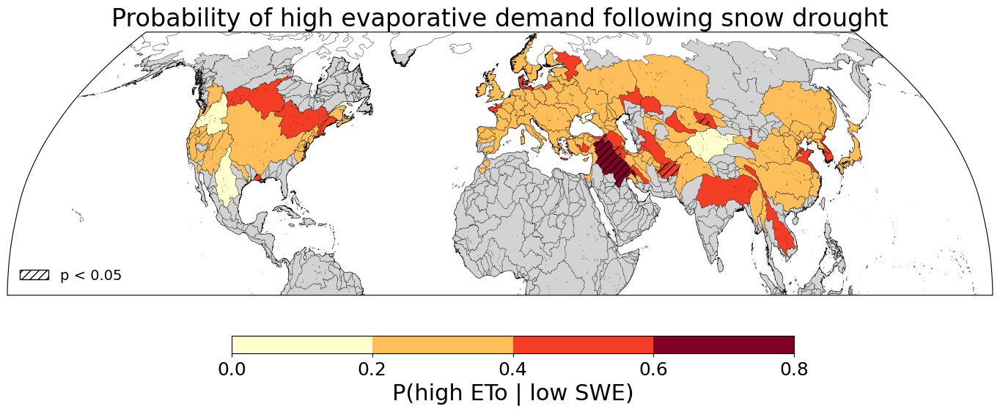

In [191]:
plot_pcond_with_hatching(
    basins_diss_plot,
    column="p_cond_dt",
    sig_col="sig_p_cond_dt",
    title="Probability of high evaporative demand following snow drought"
)

In [154]:
# Many basins are significant:

# Snow drought → increases probability of atmospheric demand
# Non-random coupling

# strong mechanistic finding

In [155]:
# plot excess probability over independence:
# P(high ETo∣low SWE)−P(high ETo)

# This shows where snow drought makes high ETo more likely than expected by chance.

In [192]:
# Compute excess probability
# Overall probability of high ETo after detrending
high_eto_dt_174 = compound_dt_174 | demand_dt_174

# Valid basin-years for the same 174 analysis basins
valid_wy_dt_174 = (
    valid_wy_dt
    .isel(region=analysis_pos)
    .assign_coords(region=basins_diss_174["MAIN_BAS"].values)
)

n_valid_wy_dt = valid_wy_dt_174.sum("wy")

p_expected_dt = xr.where(
    n_valid_wy_dt > 0,
    high_eto_dt_174.sum("wy") / n_valid_wy_dt,
    np.nan
)

p_expected_dt.name = "p_expected_dt"

# Excess conditional probability after detrending
p_cond_excess_dt = p_cond_dt - p_expected_dt
p_cond_excess_dt.name = "p_cond_excess_dt"

# Verify alignment
assert np.array_equal(
    basins_diss_174["MAIN_BAS"].values,
    p_expected_dt["region"].values
)

assert np.array_equal(
    p_cond_dt["region"].values,
    p_expected_dt["region"].values
)

# Store results in the aligned 174-basin GeoDataFrame
basins_diss_174["p_expected_dt"] = p_expected_dt.values
basins_diss_174["p_cond_excess_dt"] = p_cond_excess_dt.values

In [193]:
detrended_cond_cols = [
    "p_cond_dt",
    "p_expected_dt",
    "p_cond_excess_dt",
    "p_cond_pval_dt",
    "sig_p_cond_dt"
]

basins_diss_plot = (
    basins_diss
    .drop(columns=detrended_cond_cols, errors="ignore")
    .merge(
        basins_diss_174[
            ["MAIN_BAS"] + detrended_cond_cols
        ],
        on="MAIN_BAS",
        how="left"
    )
)

In [194]:
# Plotting function for excess probability
def plot_pcond_excess_with_hatching(gdf, column, sig_col, title):

    fig = plt.figure(figsize=(14,7))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    # discrete bins
    bounds = np.arange(-0.4, 0.45, 0.05)   # 0.05 resolution
    cmap = plt.get_cmap("RdBu_r", len(bounds) - 1)
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # main plot
    gdf.plot(
        column=column,
        cmap=cmap,
        norm=norm,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax
    )

    sig_mask = (
        gdf[sig_col]
        .astype("boolean")
        .fillna(False)
        .to_numpy(dtype=bool)
    )

    sig_gdf = gdf.loc[sig_mask]

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax,
            facecolor="none",
            edgecolor="black",
            hatch="///",
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch="///",
            label="p < 0.05"
        )

        ax.legend(
            handles=[hatch_patch],
            loc="lower left",
            frameon=False,
            fontsize=12
        )

    # colorbar
    fig.canvas.draw()
    pos = ax.get_position()

    cax = fig.add_axes([
        pos.x0 + 0.03,
        pos.y0 + 0.03,
        pos.width - 0.06,
        0.035
    ])

    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=[-0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4],
        spacing="proportional"
    )

    cb.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=13
    )

    # styling
    ax.set_title(title, fontsize=16)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.3)

    plt.subplots_adjust(top=0.92, bottom=0.06, left=0.02, right=0.98)
    plt.show()

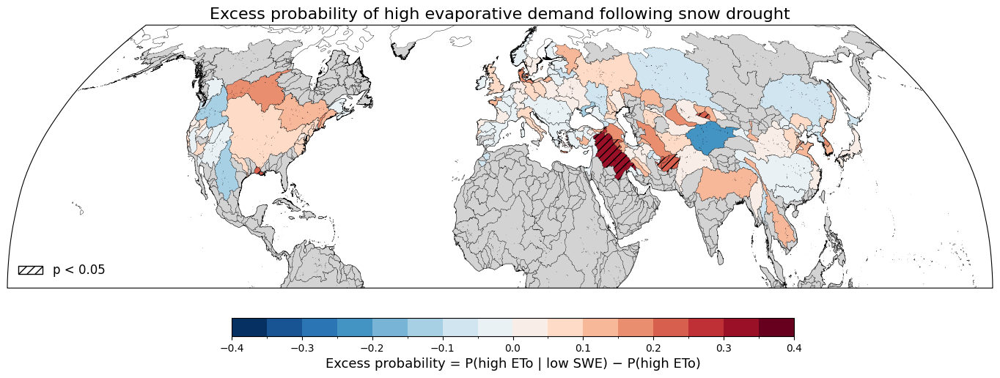

In [196]:
plot_pcond_excess_with_hatching(
    basins_diss_plot,
    column="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    title="Excess probability of high evaporative demand following snow drought"
)

In [197]:
# Summary of detrended conditional-probability results
excess = basins_diss_174["p_cond_excess_dt"]

sig = (
    basins_diss_174["sig_p_cond_dt"]
    .astype("boolean")
    .fillna(False)
)

valid = (
    excess.notna()
    & basins_diss_174["p_cond_pval_dt"].notna()
)

# Significant positive excess probability
pos = valid & sig & (excess > 0)

n_valid = int(valid.sum())
n_sig = int((valid & sig).sum())
n_pos = int(pos.sum())

median_excess = float(np.nanmedian(excess[valid]))

pct_sig = 100 * n_sig / n_valid if n_valid > 0 else np.nan
pct_pos = 100 * n_pos / n_valid if n_valid > 0 else np.nan

print(
    "Median excess probability:",
    round(median_excess, 3)
)

print(f"Valid basins: {n_valid}")

print(
    f"Significant basins: {n_sig} "
    f"({pct_sig:.1f}%)"
)

print(
    f"Significant increase: {n_pos} "
    f"({pct_pos:.1f}%)"
)

Median excess probability: 0.041
Valid basins: 174
Significant basins: 8 (4.6%)
Significant increase: 8 (4.6%)


Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_S9.png


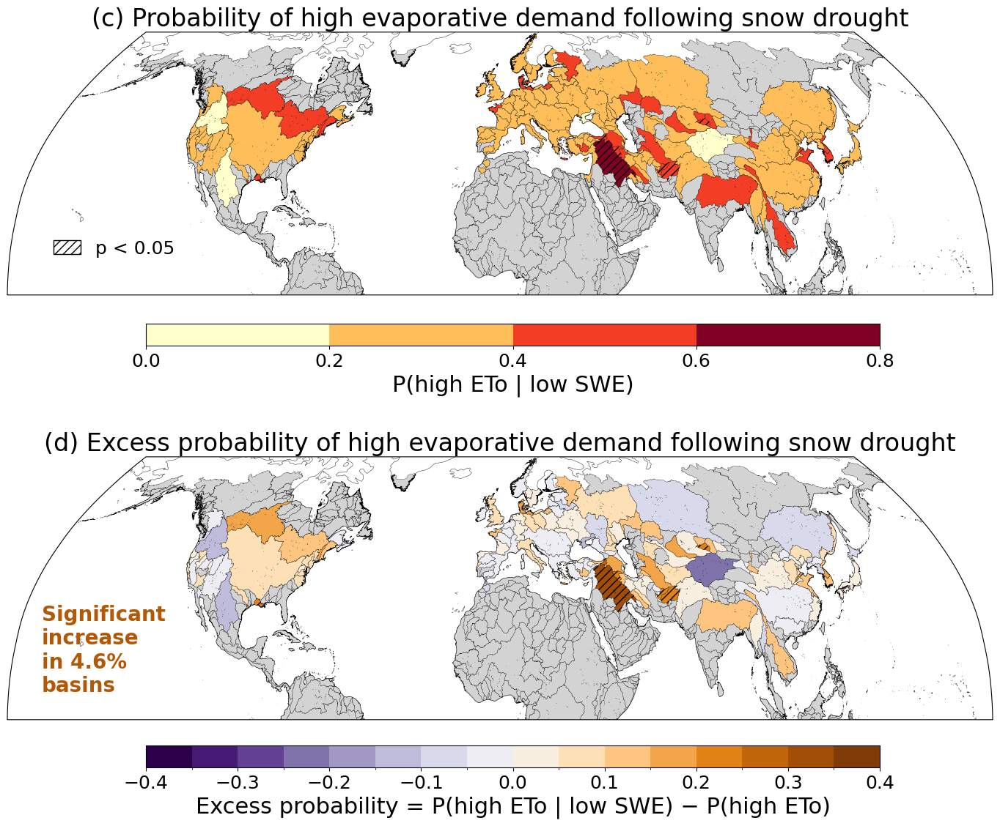

In [198]:
def plot_pcond_panels_vertical(
    gdf,
    pcond_col="p_cond_dt",
    excess_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt",
    extent=(-180, 180, 0, 70),
    hatch="///"
):
    """
    Plot:
    (a) P(high ETo | low SWE)
    (b) Excess probability = P(high ETo | low SWE) - P(high ETo)

    Significance hatching is based on sig_col.
    """

    # ============================================================
    # Summary statistics for annotation in panel (b)
    # ============================================================
    excess = gdf[excess_col]
    sig = gdf[sig_col].astype("boolean").fillna(False).to_numpy(dtype=bool)
    valid = excess.notna() & gdf[pcond_col].notna()

    pos_sig = sig & (excess > 0)

    n_valid = int(valid.sum())
    n_pos_sig = int(pos_sig.sum())

    pct_pos_sig = 100 * n_pos_sig / n_valid if n_valid > 0 else np.nan

    sig_gdf = gdf.loc[sig]

    # ============================================================
    # Figure and axes
    # ============================================================
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(14, 12),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    ax1, ax2 = axes

    title_fs = 24
    cbar_label_fs = 22
    tick_fs = 18
    annotation_fs = 20

    # ============================================================
    # Panel (a): Conditional probability
    # ============================================================
    bins_a = [0.0, 0.2, 0.4, 0.6, 0.8]

    cmap_a = plt.get_cmap("YlOrRd", len(bins_a) - 1)

    norm_a = mcolors.BoundaryNorm(
        boundaries=bins_a,
        ncolors=cmap_a.N,
        clip=True
    )

    ax1.set_global()

    gdf.plot(
        column=pcond_col,
        cmap=cmap_a,
        norm=norm_a,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax1
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax1,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

        hatch_patch = mpatches.Patch(
            facecolor="white",
            edgecolor="black",
            hatch=hatch,
            label="p < 0.05"
        )

        ax1.legend(
            handles=[hatch_patch],
            loc="lower left",
            bbox_to_anchor=(0.03, 0.08),
            frameon=False,
            fontsize=18,
            handlelength=1.5,
            handleheight=0.8
        )

    ax1.set_title(
        "(c) Probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax1.set_extent(extent, crs=ccrs.PlateCarree())
    ax1.coastlines(linewidth=0.3)

    # Colorbar for panel (a)
    fig.canvas.draw()
    pos1 = ax1.get_position()

    cax1 = fig.add_axes([
        pos1.x0 + 0.03,
        pos1.y0 - 0.04,
        pos1.width - 0.06,
        0.025
    ])

    sm1 = plt.cm.ScalarMappable(norm=norm_a, cmap=cmap_a)
    sm1.set_array([])

    cb1 = fig.colorbar(
        sm1,
        cax=cax1,
        orientation="horizontal",
        boundaries=bins_a,
        ticks=bins_a,
        spacing="proportional"
    )

    cb1.set_label(
        "P(high ETo | low SWE)",
        fontsize=cbar_label_fs
    )

    cb1.ax.tick_params(labelsize=tick_fs)

    # ============================================================
    # Panel (b): Excess probability
    # ============================================================
    bounds_b = np.arange(-0.4, 0.45, 0.05)

    # Use PuOr_r so that:
    # negative/decrease = purple
    # positive/increase = orange
    cmap_b = plt.get_cmap("PuOr_r", len(bounds_b) - 1)

    norm_b = mcolors.BoundaryNorm(
        boundaries=bounds_b,
        ncolors=cmap_b.N,
        clip=True
    )

    ax2.set_global()

    gdf.plot(
        column=excess_col,
        cmap=cmap_b,
        norm=norm_b,
        linewidth=0.2,
        edgecolor="black",
        transform=ccrs.PlateCarree(),
        missing_kwds={"color": "lightgray"},
        ax=ax2
    )

    if not sig_gdf.empty:
        sig_gdf.plot(
            ax=ax2,
            facecolor="none",
            edgecolor="black",
            hatch=hatch,
            linewidth=0,
            transform=ccrs.PlateCarree()
        )

    ax2.set_title(
        "(d) Excess probability of high evaporative demand following snow drought",
        fontsize=title_fs
    )

    ax2.set_extent(extent, crs=ccrs.PlateCarree())
    ax2.coastlines(linewidth=0.3)

    # ------------------------------------------------------------
    # Add significant increase annotation on left side of panel (b)
    # ------------------------------------------------------------
    ax2.text(
        -170, 18,
        f"Significant \nincrease\nin {pct_pos_sig:.1f}% \nbasins",
        transform=ccrs.PlateCarree(),
        fontsize=annotation_fs,
        color="#B35806",   # orange from PuOr-like palette
        ha="left",
        va="center",
        fontweight="bold"
    )

    # Colorbar for panel (b)
    fig.canvas.draw()
    pos2 = ax2.get_position()

    cax2 = fig.add_axes([
        pos2.x0 + 0.03,
        pos2.y0 - 0.10,
        pos2.width - 0.06,
        0.025
    ])

    sm2 = plt.cm.ScalarMappable(norm=norm_b, cmap=cmap_b)
    sm2.set_array([])

    cb2 = fig.colorbar(
        sm2,
        cax=cax2,
        orientation="horizontal",
        boundaries=bounds_b,
        ticks=[-0.4, -0.3, -0.2, -0.1, 0, 0.1, 0.2, 0.3, 0.4],
        spacing="proportional"
    )

    cb2.set_label(
        "Excess probability = P(high ETo | low SWE) − P(high ETo)",
        fontsize=cbar_label_fs
    )

    cb2.ax.tick_params(labelsize=tick_fs)

    # ============================================================
    # Final spacing
    # ============================================================
    plt.subplots_adjust(
        top=0.96,
        bottom=0.06,
        left=0.02,
        right=0.98,
        hspace=0.16
    )

    outpath = os.path.abspath("Fig_S9.png")
    fig.savefig(outpath, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure to: {outpath}")

    plt.show()

plot_pcond_panels_vertical(
    basins_diss_plot,
    pcond_col="p_cond_dt",
    excess_col="p_cond_excess_dt",
    sig_col="sig_p_cond_dt"
)